[Previously published Kaggle version](https://www.kaggle.com/code/youseftahoon213/team112-notebook?scriptVersionId=359515074). This local revision must be uploaded separately.

# Formula 1 Podium Prediction Companion
One prediction is one driver entering one race. We predict podium versus no podium using
information available after qualifying and before the race starts.

**Order:** 1 Cleaning → 2 Three analytical questions → 3 Features and preprocessing →
4 Models → 5 Experiments → final test and inference → 6 Explainability.

Raw CSVs remain unchanged. Historical repeated entries use one complete best-finish source row.
Flagged lap/timing values remain recorded, with their uncertainty disclosed and excluded from predictors.

## Setup
Use the project environment and requirements-tested.txt. Put the 14 CSVs in F1 Data,
set F1_DATA_DIR, or attach the dataset on Kaggle. Results are saved in reports
(or F1_OUTPUT_DIR). This local revision does not update the published Kaggle copy automatically.

In [1]:
import os
import json
import hashlib
import random
import time
from copy import deepcopy
from pathlib import Path
from datetime import time as clock_time
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    roc_auc_score, precision_recall_curve, auc, average_precision_score,
    f1_score, precision_score, recall_score, log_loss,
    ConfusionMatrixDisplay, roc_curve
)
from sklearn.inspection import permutation_importance
import joblib
import shap
from lime.lime_tabular import LimeTabularExplainer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
threadpool_limits(limits=1)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
output_folder = Path(os.environ.get("F1_OUTPUT_DIR", "reports")).resolve()
figure_folder = output_folder / "figures"
model_folder = output_folder / "models"
for folder in [output_folder, figure_folder, model_folder]:
    folder.mkdir(parents=True, exist_ok=True)

versions = {name: metadata.version(name) for name in
            ["numpy", "pandas", "scikit-learn", "matplotlib", "shap", "lime", "joblib"]}
print("Python:", os.sys.version.split()[0], "| Random seed:", SEED)
display(pd.Series(versions, name="Version").to_frame())

Python: 3.13.7 | Random seed: 42


/Users/youseftahoon/ACL F1/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Version
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2
shap,0.54.1
lime,0.2.0.1
joblib,1.6.0


In [2]:
# Save each displayed figure and result table for the analytical report.
figure_manifest = []
def show_plot(name):
    figure = plt.gcf()
    filename = name + ".png"
    figure.savefig(figure_folder / filename, dpi=170, bbox_inches="tight")
    figure_manifest.append({
        "name": name, "file": filename,
        "title": " | ".join(ax.get_title() for ax in figure.axes if ax.get_title())
    })
    plt.show()
    plt.close(figure)

def save_table(frame, name, index=False):
    frame.to_csv(output_folder / (name + ".csv"), index=index)

In [3]:
# Folder containing the CSV files
data_folder = Path(os.environ.get("F1_DATA_DIR", "F1 Data"))

# Find the attached CSV folder when running on Kaggle
if not (data_folder / "results.csv").exists() and Path("/kaggle/input").exists():
    data_folder = next(
        (path.parent for path in sorted(Path("/kaggle/input").rglob("results.csv"))
         if (path.parent / "qualifying.csv").exists()),
        data_folder
    )

if not (data_folder / "results.csv").exists():
    raise FileNotFoundError("Attach the F1 CSVs or set F1_DATA_DIR to their folder.")

# Read each CSV separately
circuits = pd.read_csv(data_folder / "circuits.csv", na_values=[r"\N"])
constructors = pd.read_csv(data_folder / "constructors.csv", na_values=[r"\N"])
constructor_results = pd.read_csv(data_folder / "constructor_results.csv", na_values=[r"\N"])
constructor_standings = pd.read_csv(data_folder / "constructor_standings.csv", na_values=[r"\N"])

drivers = pd.read_csv(data_folder / "drivers.csv", na_values=[r"\N"])
driver_standings = pd.read_csv(data_folder / "driver_standings.csv", na_values=[r"\N"])

races = pd.read_csv(data_folder / "races.csv", na_values=[r"\N"])
results = pd.read_csv(data_folder / "results.csv", na_values=[r"\N"])
qualifying = pd.read_csv(data_folder / "qualifying.csv", na_values=[r"\N"])

lap_times = pd.read_csv(data_folder / "lap_times.csv", na_values=[r"\N"])
pit_stops = pd.read_csv(data_folder / "pit_stops.csv", na_values=[r"\N"])
sprint_results = pd.read_csv(data_folder / "sprint_results.csv", na_values=[r"\N"])

seasons = pd.read_csv(data_folder / "seasons.csv", na_values=[r"\N"])
status = pd.read_csv(data_folder / "status.csv", na_values=[r"\N"])

In [4]:
CSV_NAMES = ["circuits", "constructors", "constructor_results", "constructor_standings",
             "drivers", "driver_standings", "races", "results", "qualifying",
             "lap_times", "pit_stops", "sprint_results", "seasons", "status"]
source_hashes = {
    name: hashlib.sha256((data_folder / (name + ".csv")).read_bytes()).hexdigest()
    for name in CSV_NAMES
}
assert len(source_hashes) == 14
print("Loaded all 14 source tables; source hashes recorded.")

Loaded all 14 source tables; source hashes recorded.


# Stage 1 - Data Cleaning and Auditing
Inspect and clean each table separately. Original DataFrames and CSVs are preserved.

The small helper below shows the same before/after comparison for each file. A dash means a column is absent, not that its values are missing.

In [5]:
def compare_cleaning(before, after):
    print(f"Rows: {len(before):,} → {len(after):,}")
    print(f"Columns: {before.shape[1]} → {after.shape[1]}")
    display(pd.DataFrame({
        "Type before": before.dtypes.astype(str),
        "Type after": after.dtypes.astype(str),
        "Missing before": before.isna().sum(),
        "Missing after": after.isna().sum()
    }).fillna("—"))

## 1. Results
Each row is a recorded race entry. Check IDs, missing values and historical repeated driver–race entries before creating the separate outcome table.

### Inspect

In [6]:
# Keep the original results unchanged
results_clean = results.copy()

display(results.head())

print("Number of rows:", results.shape[0])
print("Number of columns:", results.shape[1])

results.info()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


Number of rows: 26759
Number of columns: 18
<class 'pandas.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  str    
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   str    
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   str    
 16  fastestLapSpeed  8252 non

In [7]:
# Count missing values in each column
missing_count = results_clean.isna().sum()

# Calculate the percentage missing in each column
missing_percentage = missing_count / len(results_clean) * 100

# Put both into one table
missing_summary = pd.DataFrame({
    "Missing count": missing_count,
    "Missing percentage": missing_percentage.round(2)
})

display(missing_summary)

# Every result must have an ID
print("Missing result IDs:", results_clean["resultId"].isna().sum())

# Each result ID must appear only once
print("Repeated result IDs:", results_clean["resultId"].duplicated().sum())

# Check race IDs
print(
    "Unknown races:",
    (~results_clean["raceId"].isin(races["raceId"])).sum()
)

# Check driver IDs
print(
    "Unknown drivers:",
    (~results_clean["driverId"].isin(drivers["driverId"])).sum()
)

# Check team IDs
print(
    "Unknown teams:",
    (~results_clean["constructorId"].isin(constructors["constructorId"])).sum()
)

# Check status IDs
print(
    "Unknown statuses:",
    (~results_clean["statusId"].isin(status["statusId"])).sum()
)

,Missing count,Missing percentage
resultId,0,0.00
raceId,0,0.00
driverId,0,0.00
constructorId,0,0.00
number,6,0.02
grid,0,0.00
position,10953,40.93
positionText,0,0.00
positionOrder,0,0.00
points,0,0.00


Missing result IDs: 0
Repeated result IDs: 0
Unknown races: 0
Unknown drivers: 0
Unknown teams: 0
Unknown statuses: 0


,grid,positionOrder,points,laps
count,26759.000000,26759.000000,26759.000000,26759.000000
mean,11.134796,12.794051,1.987632,46.301768
std,7.202860,7.665951,4.351209,29.496557
min,0.000000,1.000000,0.000000,0.000000
25%,5.000000,6.000000,0.000000,23.000000
50%,11.000000,12.000000,0.000000,53.000000
75%,17.000000,18.000000,2.000000,66.000000
max,34.000000,39.000000,50.000000,200.000000


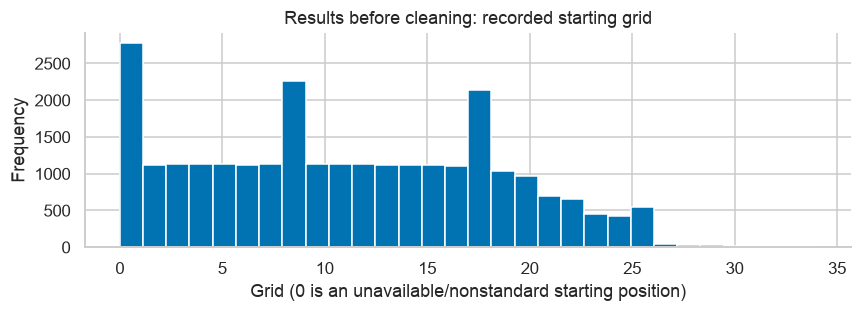

In [8]:
display(results[["grid", "positionOrder", "points", "laps"]].describe())
results["grid"].plot.hist(bins=30, figsize=(8, 3))
plt.title("Results before cleaning: recorded starting grid")
plt.xlabel("Grid (0 is an unavailable/nonstandard starting position)")
plt.tight_layout()
show_plot("cleaning_010")

### Clean types and supported missing values
Check zero fastest-lap ranks before treating them as missing. Recover a missing position only when numeric `positionText` agrees with `positionOrder`; keep other missing values.

In [9]:
# Find rows where fastest-lap rank is zero
zero_rank = results_clean["rank"] == 0

# Check whether these rows contain any fastest-lap details
display(results_clean.loc[
    zero_rank,
    ["fastestLap", "fastestLapTime", "fastestLapSpeed"]
].notna().sum())

fastestLap         0
fastestLapTime     0
fastestLapSpeed    0
dtype: int64

In [10]:
# Replace the unrecorded rank marker with a missing value
results_clean.loc[zero_rank, "rank"] = float("nan")

# Convert numeric position text into numbers
# Letter codes such as R or W become missing
position_from_text = pd.to_numeric(
    results_clean["positionText"],
    errors="coerce"
)

# Select only missing positions supported by both other columns
recover_position = (
    results_clean["position"].isna()
    & position_from_text.notna()
    & (position_from_text == results_clean["positionOrder"])
)

# Inspect the rows before changing them
display(results_clean.loc[
    recover_position,
    ["resultId", "position", "positionText", "positionOrder"]
])

,resultId,position,positionText,positionOrder
1148,1149,NaN,11,11
1151,1152,NaN,14,14


In [11]:
results_clean.loc[recover_position, "position"] = (
    position_from_text[recover_position]
)

# Convert columns that should be whole numbers into nullable integers
whole_number_columns = [
    "number",
    "position",
    "milliseconds",
    "fastestLap",
    "rank"
]

for column in whole_number_columns:
    results_clean[column] = results_clean[column].astype("Int64")

Convert durations to seconds. Keep reported elapsed time separate from text beginning with `+`, which represents a gap. The original timing fields remain available.

In [12]:
def convert_to_seconds(value):
    # Keep missing values missing
    if pd.isna(value):
        return float("nan")

    # Remove a leading + and split the time into parts
    parts = str(value).lstrip("+").split(":")

    total_seconds = 0

    for part in parts:
        total_seconds = total_seconds * 60 + float(part)

    return total_seconds

In [13]:
results_clean["fastest_lap_seconds"] = (
    results_clean["fastestLapTime"].apply(convert_to_seconds)
)

display(results_clean[
    ["fastestLapTime", "fastest_lap_seconds"]
].head())

# Convert the recorded time values
time_seconds = results_clean["time"].apply(convert_to_seconds)

# Identify values starting with +
is_gap = results_clean["time"].str.startswith("+", na=False)

# Store the two meanings separately
results_clean["reported_elapsed_seconds"] = time_seconds.where(~is_gap)
results_clean["reported_gap_seconds"] = time_seconds.where(is_gap)

display(results_clean[
    ["time", "reported_elapsed_seconds", "reported_gap_seconds"]
].head())

,fastestLapTime,fastest_lap_seconds
0,1:27.452,87.452
1,1:27.739,87.739
2,1:28.090,88.090
3,1:28.603,88.603
4,1:27.418,87.418


,time,reported_elapsed_seconds,reported_gap_seconds
0,1:34:50.616,5690.616,NaN
1,+5.478,NaN,5.478
2,+8.163,NaN,8.163
3,+17.181,NaN,17.181
4,+18.014,NaN,18.014


### Review unusual records
Flags identify records to inspect; they do not justify deleting a row. Position and finishing-order differences are retained because the fields have different meanings.

In [14]:
results_review = results_clean[
    ["resultId", "raceId", "driverId"]
].copy()

# Grid zero has several possible meanings
results_review["grid_zero"] = results_clean["grid"] == 0

# A fastest-lap number greater than recorded completed laps
results_review["lap_values_need_review"] = (
    results_clean["fastestLap"] > results_clean["laps"]
).fillna(False)

# These two position columns do not always mean the same thing
results_review["positions_differ"] = (
    results_clean["position"].notna()
    & (results_clean["position"] != results_clean["positionOrder"])
).fillna(False)

# The first-ranked result normally should not contain a gap-style time
winner_has_gap = (
    (results_clean["positionOrder"] == 1)
    & is_gap
)

# Compare elapsed-time text with its recorded milliseconds
timing_difference = (
    results_clean["reported_elapsed_seconds"]
    - results_clean["milliseconds"] / 1000
).abs()

timing_mismatch = (timing_difference > 0.01).fillna(False)

# Flag races containing either timing issue
suspect_races = results_clean.loc[
    winner_has_gap | timing_mismatch,
    "raceId"
].unique()

results_review["timing_needs_review"] = (
    results_clean["raceId"].isin(suspect_races)
)

display(results_review[
    [
        "grid_zero",
        "lap_values_need_review",
        "positions_differ",
        "timing_needs_review"
    ]
].sum())

grid_zero                 1638
lap_values_need_review      12
positions_differ            13
timing_needs_review         20
dtype: Int64

In [15]:
# Preserve the original grid column.
# In the analysis version, keep only positive starting positions.
results_clean["grid_for_analysis"] = results_clean["grid"].where(
    results_clean["grid"] > 0
).astype("Int64")

# Check the affected records
display(results_clean.loc[
    results_review["grid_zero"],
    ["resultId", "raceId", "driverId", "grid", "grid_for_analysis"]
].head())

,resultId,raceId,driverId,grid,grid_for_analysis
2281,2282,127,62,0,<NA>
2432,2433,134,49,0,<NA>
2433,2434,134,59,0,<NA>
2434,2435,134,21,0,<NA>
2797,2798,151,58,0,<NA>


In [16]:
# Select the records with questionable lap numbers
lap_review = results_clean.loc[
    results_review["lap_values_need_review"],
    [
        "resultId", "raceId", "driverId",
        "laps", "fastestLap", "fastestLapTime", "statusId"
    ]
].copy()

# Add the explanation of how the driver's race ended
lap_review = lap_review.merge(
    status,
    on="statusId",
    how="left",
    validate="many_to_one"
)

display(lap_review)

,resultId,raceId,driverId,laps,fastestLap,fastestLapTime,statusId,status
0,185,26,21,16,21,1:34.930,20,Spun off
1,22143,900,824,49,55,1:35.635,18,+8 Laps
2,22145,900,813,29,30,1:34.766,132,ERS
3,22147,900,20,3,26,1:37.064,5,Engine
4,22149,900,13,0,2,1:40.287,4,Collision
5,24059,1002,817,23,46,1:25.692,5,Engine
6,24060,1002,4,9,18,1:25.229,5,Engine
7,24061,1002,843,0,6,1:27.009,23,Brakes
8,24138,1006,817,8,49,1:40.433,84,Battery
9,24139,1006,154,2,12,1:41.982,130,Collision damage


In [17]:
timing_review = results_clean.loc[
    results_review["timing_needs_review"],
    ["resultId", "raceId", "driverId", "positionOrder", "time", "milliseconds",
     "reported_elapsed_seconds", "reported_gap_seconds"]
].copy()
timing_review["milliseconds_as_seconds"] = timing_review["milliseconds"] / 1000
display(timing_review.sort_values(["raceId", "positionOrder"]))

,resultId,raceId,driverId,positionOrder,time,milliseconds,reported_elapsed_seconds,reported_gap_seconds,milliseconds_as_seconds
26539,26545,1134,1,1,+0.526,526,NaN,0.526,0.526
26540,26546,1134,857,2,+1.173,1699,NaN,1.173,1.699
26541,26547,1134,844,3,+8.549,9075,NaN,8.549,9.075
26542,26548,1134,830,4,+9.226,9752,NaN,9.226,9.752
26543,26549,1134,846,5,+9.850,10376,NaN,9.850,10.376
26544,26550,1134,832,6,+19.795,20321,NaN,19.795,20.321
26545,26551,1134,815,7,+43.195,43721,NaN,43.195,43.721
26546,26552,1134,4,8,+49.963,50489,NaN,49.963,50.489
26547,26553,1134,839,9,+52.552,53078,NaN,52.552,53.078
26548,26554,1134,817,10,+54.926,55452,NaN,54.926,55.452


**Retention decision:** keep the flagged lap and timing values unchanged. The flags remain
        available for review; neither field is a predictor. Retention does not establish accuracy.
        No values are generated or corrected without evidence.

### Resolve repeated driver–race outcomes
Investigate repeated pairs with their year, car number, constructor and status. They are not automatically duplicate mistakes.

In [18]:
# Find all rows that share the same race and driver
duplicate_rows = results[
    results.duplicated(subset=["raceId", "driverId"], keep=False)
]

display(duplicate_rows.sort_values(["raceId", "driverId"]))

# Add the race year and name
duplicate_details = duplicate_rows.merge(
    races[["raceId", "year", "name"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Add the explanation of how each entry ended
duplicate_details = duplicate_details.merge(
    status[["statusId", "status"]],
    on="statusId",
    how="left",
    validate="many_to_one"
)

# Display only the columns we need for this investigation
duplicate_details = duplicate_details[
    [
        "year", "name", "raceId", "driverId",
        "constructorId", "number", "grid",
        "positionOrder", "status"
    ]
]

display(duplicate_details.sort_values(["year", "raceId", "driverId"]))

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
13188,13189,540,229,54,10.0,0,NaN,F,26,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81
13191,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97
17362,17363,717,373,172,1.0,1,7.0,7,7,0.0,102,NaN,NaN,NaN,NaN,NaN,NaN,60
24298,24304,717,373,172,2.0,1,NaN,R,12,0.0,54,NaN,NaN,NaN,NaN,NaN,NaN,98
17740,17741,733,465,172,48.0,0,NaN,W,22,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20181,20182,838,627,154,26.0,15,6.0,6,6,0.0,56,NaN,NaN,NaN,NaN,NaN,NaN,18
20163,20164,839,579,51,18.0,1,NaN,R,15,1.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6
20183,20184,839,579,51,60.0,7,NaN,R,13,0.0,34,NaN,NaN,NaN,NaN,NaN,NaN,5
20165,20166,839,647,6,16.0,2,NaN,R,17,0.0,21,NaN,NaN,NaN,NaN,NaN,NaN,5


,year,name,raceId,driverId,constructorId,number,grid,positionOrder,status
84,1950,Indianapolis 500,835,529,150,14.0,8,31,Wheel bearing
88,1950,Indianapolis 500,835,529,113,17.0,9,5,+2 Laps
85,1950,French Grand Prix,838,627,154,20.0,6,12,Overheating
89,1950,French Grand Prix,838,627,154,26.0,15,6,+8 Laps
86,1950,Italian Grand Prix,839,579,51,18.0,1,15,Gearbox
...,...,...,...,...,...,...,...,...,...
4,1962,British Grand Prix,733,465,97,50.0,0,25,Withdrew
2,1964,United States Grand Prix,717,373,172,1.0,1,7,Out of fuel
175,1964,United States Grand Prix,717,373,172,2.0,1,12,Injection
0,1978,Italian Grand Prix,540,229,54,10.0,0,26,Did not qualify


Keep one complete best-finish entry per driver-race. Select the smallest positionOrder;
        ties prefer the smallest positive grid, then smallest resultId. Grid and constructor stay
        attached to that entry. This convention preserves one real recorded combination rather than
        combining different cars. Historical truth can still be ambiguous.

In [19]:
chosen = results_clean.assign(_grid_priority=results_clean['grid'].astype(float).where(results_clean['grid'].gt(0), np.inf))
selected_results = (chosen.sort_values(['raceId','driverId','positionOrder','_grid_priority','resultId'], kind='mergesort')
    .drop_duplicates(['raceId','driverId'], keep='first').drop(columns='_grid_priority').copy())
driver_race_outcomes = selected_results[['resultId','raceId','driverId','constructorId','positionOrder','grid_for_analysis']].copy()
assert not driver_race_outcomes.duplicated(['raceId','driverId']).any()
assert selected_results['resultId'].isin(results_clean['resultId']).all()
display(driver_race_outcomes.head())
print('Unique driver–race outcomes:',len(driver_race_outcomes))

,resultId,raceId,driverId,constructorId,positionOrder,grid_for_analysis
7572,7573,1,1,1,20,18
7562,7563,1,2,2,10,9
7558,7559,1,3,3,6,5
7557,7558,1,4,4,5,10
7571,7572,1,5,1,19,12


Unique driver–race outcomes: 26668


In [20]:
grid_summary = results_clean.groupby(['raceId','driverId'],as_index=False).agg(
    entry_count=('resultId','size'), different_positive_grids=('grid_for_analysis','nunique'))
print('Repeated pairs:',int(grid_summary['entry_count'].gt(1).sum()))
print('Groups with different positive grids:',int(grid_summary['different_positive_grids'].gt(1).sum()))
# Reconcile all source fields together, not just the key.
coherent = driver_race_outcomes.merge(
    results_clean[['resultId','raceId','driverId','constructorId','positionOrder','grid_for_analysis']],
    on=['resultId','raceId','driverId','constructorId','positionOrder','grid_for_analysis'],
    how='left', indicator=True, validate='one_to_one')
assert coherent['_merge'].eq('both').all()
print('Every summary grid/constructor/outcome belongs to one original entry: PASS')

Repeated pairs: 85
Groups with different positive grids: 81
Every summary grid/constructor/outcome belongs to one original entry: PASS


In [21]:
# Compare the previous independent-grid rule with the selected real source row.
previous_summary = results_clean.groupby(["raceId", "driverId"], as_index=False).agg(
    previous_best_finish=("positionOrder", "min"),
    previous_best_grid=("grid_for_analysis", "min"))
duplicate_rule_check = driver_race_outcomes.merge(
    previous_summary, on=["raceId", "driverId"], validate="one_to_one")
same_grid = (
    duplicate_rule_check["grid_for_analysis"].eq(duplicate_rule_check["previous_best_grid"])
    | (duplicate_rule_check["grid_for_analysis"].isna()
       & duplicate_rule_check["previous_best_grid"].isna())).fillna(False)
assert duplicate_rule_check["positionOrder"].eq(duplicate_rule_check["previous_best_finish"]).all()
changed_rule_rows = duplicate_rule_check.loc[~same_grid].copy()
print("Finishing outcomes unchanged; analytical grids changed for", len(changed_rule_rows), "historical pairs.")
display(changed_rule_rows.head(12))
save_table(changed_rule_rows, "duplicate_rule_changes")

Finishing outcomes unchanged; analytical grids changed for 56 historical pairs.


,resultId,raceId,driverId,constructorId,positionOrder,grid_for_analysis,previous_best_finish,previous_best_grid
18445,17962,742,475,102,19,20,19,5
18532,24303,745,418,172,11,15,11,11
18553,22372,746,475,170,3,8,3,1
19080,20296,770,479,118,14,10,14,5
19210,20286,776,581,6,6,11,6,5
19225,20289,777,501,105,8,14,8,8
19229,20288,777,578,6,7,9,7,5
19269,20290,779,356,87,7,15,7,13
19288,20291,780,475,118,1,3,1,1
19289,18806,780,479,118,1,3,1,1


In [22]:
# Count different constructors for each driver in each race
constructor_counts = results_clean.groupby(
    ["raceId", "driverId"]
)["constructorId"].nunique()

# Show groups with more than one constructor
constructor_conflicts = constructor_counts[
    constructor_counts > 1
]

print("Affected driver-race groups:", len(constructor_conflicts))
display(constructor_conflicts)

Affected driver-race groups: 16


raceId  driverId
540     229         2
733     465         2
742     475         2
766     541         2
788     624         2
800     556         2
        612         3
        702         2
        730         2
809     512         2
        518         2
        520         2
        521         2
        612         2
        702         2
835     529         2
Name: constructorId, dtype: int64

In [23]:
# Show every entry in the groups with conflicting constructors.
constructor_review = duplicate_details.merge(
    constructor_conflicts.rename("constructor_count").reset_index(),
    on=["raceId", "driverId"],
    validate="many_to_one"
).sort_values(["year", "raceId", "driverId"])
display(constructor_review)

,year,name,raceId,driverId,constructorId,number,grid,positionOrder,status,constructor_count
18,1950,Indianapolis 500,835,529,150,14.0,8,31,Wheel bearing,2
19,1950,Indianapolis 500,835,529,113,17.0,9,5,+2 Laps,2
16,1953,Indianapolis 500,809,512,143,56.0,33,32,Ignition,2
25,1953,Indianapolis 500,809,512,113,62.0,18,19,Oil leak,2
12,1953,Indianapolis 500,809,518,110,4.0,27,24,Ignition,2
20,1953,Indianapolis 500,809,518,113,3.0,9,3,Finished,2
13,1953,Indianapolis 500,809,520,113,41.0,13,28,Accident,2
22,1953,Indianapolis 500,809,520,114,98.0,6,9,Accident,2
14,1953,Indianapolis 500,809,521,114,97.0,16,29,Fuel leak,2
21,1953,Indianapolis 500,809,521,114,98.0,6,9,Accident,2


**Constructor selection resolved by the agreed rule:** the 16 historical conflict groups
        inherit the constructor of the selected source entry. Constructor IDs are labels, not ranks.
        All detailed entries remain available. These repeated pairs are outside our 2003-2024
        modeling period. Question 1 checks sensitivity to excluding repeated pairs.

In [24]:
display(pd.DataFrame({
    "Table": ["Detailed results", "Driver–race outcomes"],
    "Rows": [len(results_clean), len(driver_race_outcomes)],
    "Repeated driver–race pairs": [
        results_clean.duplicated(["raceId", "driverId"]).sum(),
        driver_race_outcomes.duplicated(["raceId", "driverId"]).sum()
    ]
}))

,Table,Rows,Repeated driver–race pairs
0,Detailed results,26759,91
1,Driver–race outcomes,26668,0


### Before and after
        Detailed source rows remain intact. Supported position recovery and rank-sentinel changes
        are shown below. The separate outcome table now keeps a coherent source row and its resultId.

In [25]:
# Confirm that no source rows were removed
print("Rows before:", len(results))
print("Rows after:", len(results_clean))

# Confirm that the required outcome remains complete
print(
    "Missing finishing orders:",
    results_clean["positionOrder"].isna().sum()
)

# Confirm that individual result IDs remain unique
print(
    "Repeated result IDs:",
    results_clean["resultId"].duplicated().sum()
)

Rows before: 26759
Rows after: 26759
Missing finishing orders: 0
Repeated result IDs: 0


In [26]:
compare_cleaning(results, results_clean)

Rows: 26,759 → 26,759
Columns: 18 → 22


,Type before,Type after,Missing before,Missing after
constructorId,int64,int64,0.0,0
driverId,int64,int64,0.0,0
fastestLap,float64,Int64,18507.0,18507
fastestLapSpeed,float64,float64,18507.0,18507
fastestLapTime,str,str,18507.0,18507
fastest_lap_seconds,—,float64,—,18507
grid,int64,int64,0.0,0
grid_for_analysis,—,Int64,—,1638
laps,int64,int64,0.0,0
milliseconds,float64,Int64,19079.0,19079


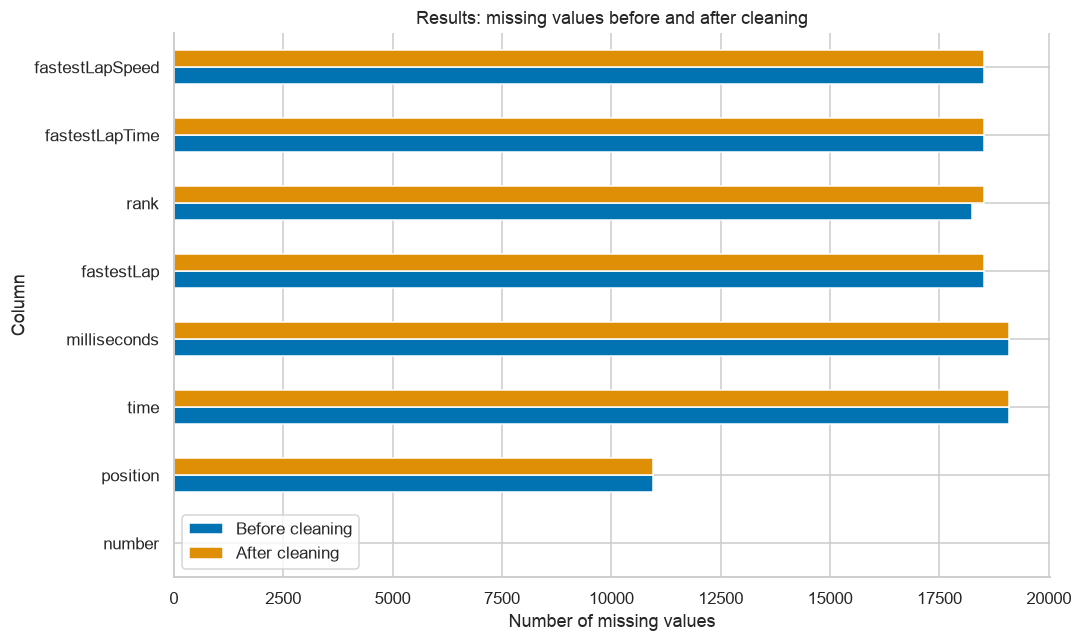

In [27]:
# Compare the original columns before and after cleaning
missing_before_after = pd.DataFrame({
    "Before cleaning": results.isna().sum(),
    "After cleaning": results_clean[results.columns].isna().sum()
})

# Display only columns with missing values before or after
columns_with_missing = missing_before_after[
    (missing_before_after > 0).any(axis=1)
]

# Draw the comparison
columns_with_missing.plot.barh(figsize=(10, 6))

plt.title("Results: missing values before and after cleaning")
plt.xlabel("Number of missing values")
plt.ylabel("Column")
plt.tight_layout()
show_plot("cleaning_036")

## 2. Drivers
One row per driver. Inspect identifiers and missingness; then remove unused `number`, `code` and `url`, and parse birth dates.

In [28]:
# Preserve the original table
drivers_clean = drivers.copy()

# Show the first five rows
display(drivers_clean.head())

print("Number of drivers:", len(drivers_clean))

drivers_clean.info()

,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44.0,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,NaN,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6.0,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14.0,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,NaN,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen


Number of drivers: 861
<class 'pandas.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   driverId     861 non-null    int64  
 1   driverRef    861 non-null    str    
 2   number       59 non-null     float64
 3   code         104 non-null    str    
 4   forename     861 non-null    str    
 5   surname      861 non-null    str    
 6   dob          861 non-null    str    
 7   nationality  861 non-null    str    
 8   url          861 non-null    str    
dtypes: float64(1), int64(1), str(7)
memory usage: 60.7 KB


In [29]:
drivers_missing = pd.DataFrame({
    "Missing count": drivers_clean.isna().sum(),
    "Missing percentage": (
        drivers_clean.isna().sum() / len(drivers_clean) * 100
    ).round(2)
})

display(drivers_missing)

#check for missing or repeated driver IDs
print(
    "Missing driver IDs:",
    drivers_clean["driverId"].isna().sum()
)

print(
    "Repeated driver IDs:",
    drivers_clean["driverId"].duplicated().sum()
)

print(
    "Completely repeated rows:",
    drivers_clean.duplicated().sum()
)

display(drivers_clean[
    ["driverId", "forename", "surname", "dob", "nationality"]
].head(10))

,Missing count,Missing percentage
driverId,0,0.00
driverRef,0,0.00
number,802,93.15
code,757,87.92
forename,0,0.00
surname,0,0.00
dob,0,0.00
nationality,0,0.00
url,0,0.00


Missing driver IDs: 0
Repeated driver IDs: 0
Completely repeated rows: 0


,driverId,forename,surname,dob,nationality
0,1,Lewis,Hamilton,1985-01-07,British
1,2,Nick,Heidfeld,1977-05-10,German
2,3,Nico,Rosberg,1985-06-27,German
3,4,Fernando,Alonso,1981-07-29,Spanish
4,5,Heikki,Kovalainen,1981-10-19,Finnish
5,6,Kazuki,Nakajima,1985-01-11,Japanese
6,7,Sébastien,Bourdais,1979-02-28,French
7,8,Kimi,Räikkönen,1979-10-17,Finnish
8,9,Robert,Kubica,1984-12-07,Polish
9,10,Timo,Glock,1982-03-18,German


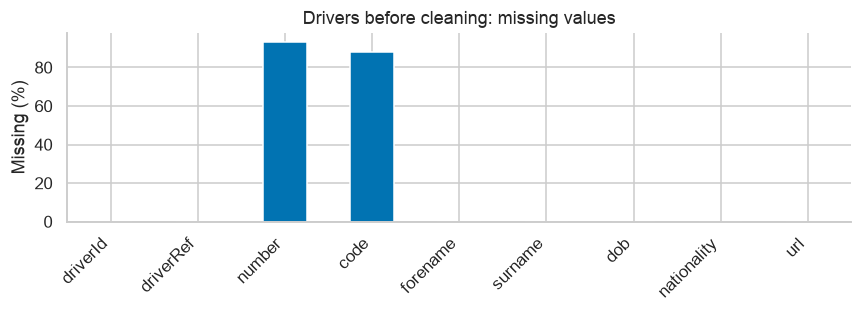

In [30]:
drivers_missing["Missing percentage"].plot.bar(figsize=(8, 3))
plt.title("Drivers before cleaning: missing values")
plt.ylabel("Missing (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
show_plot("cleaning_040")

In [31]:
# Create the cleaned table without these unnecessary columns
drivers_clean = drivers.drop(
    columns=["number", "code", "url"]
).copy()

drivers_clean["dob"] = pd.to_datetime(
    drivers_clean["dob"],
    format="%Y-%m-%d"
)

In [32]:
compare_cleaning(drivers, drivers_clean)

Rows: 861 → 861
Columns: 9 → 6


,Type before,Type after,Missing before,Missing after
code,str,—,757,—
dob,str,datetime64[us],0,0.0
driverId,int64,int64,0,0.0
driverRef,str,str,0,0.0
forename,str,str,0,0.0
nationality,str,str,0,0.0
number,float64,—,802,—
surname,str,str,0,0.0
url,str,—,0,—


All 861 drivers remain. `number` and `code` are 93.15% and 87.92% missing and are not needed in the current cleaned table; raw values remain available. Birth dates parse successfully and the six retained columns have no missing values.

## 3. Constructors
One row per constructor. Check IDs and completeness; remove only the reference URL.

In [33]:
# Create a working copy
constructors_clean = constructors.copy()

# Preview the table
display(constructors_clean.head())

# Check its size and column types
print("Number of constructors:", len(constructors_clean))

constructors_clean.info()

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


Number of constructors: 212
<class 'pandas.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   constructorId   212 non-null    int64
 1   constructorRef  212 non-null    str  
 2   name            212 non-null    str  
 3   nationality     212 non-null    str  
 4   url             212 non-null    str  
dtypes: int64(1), str(4)
memory usage: 8.4 KB


In [34]:
# Check missing values
display(constructors_clean.isna().sum())

# Each constructor should have one unique ID
print(
    "Missing constructor IDs:",
    constructors_clean["constructorId"].isna().sum()
)

print(
    "Repeated constructor IDs:",
    constructors_clean["constructorId"].duplicated().sum()
)

print(
    "Completely repeated rows:",
    constructors_clean.duplicated().sum()
)

constructorId     0
constructorRef    0
name              0
nationality       0
url               0
dtype: int64

Missing constructor IDs: 0
Repeated constructor IDs: 0
Completely repeated rows: 0


In [35]:
# Keep the original constructors table unchanged
constructors_clean = constructors.drop(columns=["url"]).copy()

display(constructors_clean.head())

,constructorId,constructorRef,name,nationality
0,1,mclaren,McLaren,British
1,2,bmw_sauber,BMW Sauber,German
2,3,williams,Williams,British
3,4,renault,Renault,French
4,5,toro_rosso,Toro Rosso,Italian


In [36]:
compare_cleaning(constructors, constructors_clean)

Rows: 212 → 212
Columns: 5 → 4


,Type before,Type after,Missing before,Missing after
constructorId,int64,int64,0,0.0
constructorRef,str,str,0,0.0
name,str,str,0,0.0
nationality,str,str,0,0.0
url,str,—,0,—


All 212 constructors remain, with no missing values or repeated IDs. Names and nationalities are unchanged.

## 4. Circuits
Check circuit IDs, country labels and geographic ranges. Remove only `url`; negative altitude alone is not an error.

In [37]:
circuits_clean = circuits.copy()

display(circuits_clean.head())

print("Number of circuits:", len(circuits_clean))

circuits_clean.info()

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


Number of circuits: 77
<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     str    
 2   name        77 non-null     str    
 3   location    77 non-null     str    
 4   country     77 non-null     str    
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     str    
dtypes: float64(2), int64(2), str(5)
memory usage: 5.5 KB


In [38]:
circuits_missing = pd.DataFrame({
    "Missing count": circuits_clean.isna().sum(),
    "Missing percentage": (
        circuits_clean.isna().sum() / len(circuits_clean) * 100
    ).round(2)
})

display(circuits_missing)

print(
    "Missing circuit IDs:",
    circuits_clean["circuitId"].isna().sum()
)

print(
    "Repeated circuit IDs:",
    circuits_clean["circuitId"].duplicated().sum()
)

print(
    "Completely repeated rows:",
    circuits_clean.duplicated().sum()
)

,Missing count,Missing percentage
circuitId,0,0.0
circuitRef,0,0.0
name,0,0.0
location,0,0.0
country,0,0.0
lat,0,0.0
lng,0,0.0
alt,0,0.0
url,0,0.0


Missing circuit IDs: 0
Repeated circuit IDs: 0
Completely repeated rows: 0


In [39]:
display(circuits_clean[["lat", "lng", "alt"]].describe())

display(sorted(circuits_clean["country"].dropna().unique()))

,lat,lng,alt
count,77.000000,77.000000,77.000000
mean,33.442925,1.076683,247.012987
std,22.808866,65.516951,362.738469
min,-37.849700,-118.189000,-7.000000
25%,32.777400,-9.394170,18.000000
50%,40.951700,3.930830,129.000000
75%,46.958900,19.248600,332.000000
max,57.265300,144.968000,2227.000000


['Argentina',
 'Australia',
 'Austria',
 'Azerbaijan',
 'Bahrain',
 'Belgium',
 'Brazil',
 'Canada',
 'China',
 'France',
 'Germany',
 'Hungary',
 'India',
 'Italy',
 'Japan',
 'Korea',
 'Malaysia',
 'Mexico',
 'Monaco',
 'Morocco',
 'Netherlands',
 'Portugal',
 'Qatar',
 'Russia',
 'Saudi Arabia',
 'Singapore',
 'South Africa',
 'Spain',
 'Sweden',
 'Switzerland',
 'Turkey',
 'UAE',
 'UK',
 'USA',
 'United States']

In [40]:
print("Invalid latitude:", (~circuits_clean["lat"].between(-90, 90)).sum())
print("Invalid longitude:", (~circuits_clean["lng"].between(-180, 180)).sum())

Invalid latitude: 0
Invalid longitude: 0


In [41]:
# Remove reference URLs while preserving the original table
circuits_clean = circuits.drop(columns=["url"]).copy()

display(circuits_clean.head())

,circuitId,circuitRef,name,location,country,lat,lng,alt
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130


In [42]:
compare_cleaning(circuits, circuits_clean)

Rows: 77 → 77
Columns: 9 → 8


,Type before,Type after,Missing before,Missing after
alt,int64,int64,0,0.0
circuitId,int64,int64,0,0.0
circuitRef,str,str,0,0.0
country,str,str,0,0.0
lat,float64,float64,0,0.0
lng,float64,float64,0,0.0
location,str,str,0,0.0
name,str,str,0,0.0
url,str,—,0,—


All 77 circuits remain. Coordinates fall within valid ranges, and altitude ranges from −7 to 2,227 metres. Country labels are preserved; any later country matching needs an explicit mapping.

## 5. Races
One row per race. Check race IDs, season rounds, circuit references and dates. Remove unused session schedules (over 90% missing) and `url`; keep the race date and available start times.

In [43]:
races_clean = races.copy()

display(races_clean.head())

print("Number of races:", len(races_clean))

races_clean.info()

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Number of races: 1125
<class 'pandas.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   raceId       1125 non-null   int64
 1   year         1125 non-null   int64
 2   round        1125 non-null   int64
 3   circuitId    1125 non-null   int64
 4   name         1125 non-null   str  
 5   date         1125 non-null   str  
 6   time         394 non-null    str  
 7   url          1125 non-null   str  
 8   fp1_date     90 non-null     str  
 9   fp1_time     68 non-null     str  
 10  fp2_date     90 non-null     str  
 11  fp2_time     68 non-null     str  
 12  fp3_date     72 non-null     str  
 13  fp3_time     53 non-null     str  
 14  quali_date   90 non-null     str  
 15  quali_time   68 non-null     str  
 16  sprint_date  18 non-null     str  
 17  sprint_time  15 non-null     str  
dtypes: int64(4), str(14)
memory usage: 158.3 KB


In [44]:
races_missing = pd.DataFrame({
    "Missing count": races_clean.isna().sum(),
    "Missing percentage": (
        races_clean.isna().sum() / len(races_clean) * 100
    ).round(2)
})

display(races_missing)

print("Missing race IDs:", races_clean["raceId"].isna().sum())

print("Repeated race IDs:", races_clean["raceId"].duplicated().sum())

print("Completely repeated rows:", races_clean.duplicated().sum())

# Each season should normally have one race per round number
print(
    "Repeated year-round combinations:",
    races_clean.duplicated(subset=["year", "round"]).sum()
)

print(
    "Unknown circuit IDs:",
    (~races_clean["circuitId"].isin(circuits_clean["circuitId"])).sum()
)

,Missing count,Missing percentage
raceId,0,0.00
year,0,0.00
round,0,0.00
circuitId,0,0.00
name,0,0.00
date,0,0.00
time,731,64.98
url,0,0.00
fp1_date,1035,92.00
fp1_time,1057,93.96


Missing race IDs: 0
Repeated race IDs: 0
Completely repeated rows: 0
Repeated year-round combinations: 0
Unknown circuit IDs: 0


In [45]:
display(races_clean[["year", "round"]].describe())

display(races_clean[
    ["raceId", "year", "round", "name", "date", "time"]
].head(10))

,year,round
count,1125.000000,1125.000000
mean,1992.703111,8.579556
std,20.603848,5.159910
min,1950.000000,1.000000
25%,1977.000000,4.000000
50%,1994.000000,8.000000
75%,2011.000000,13.000000
max,2024.000000,24.000000


,raceId,year,round,name,date,time
0,1,2009,1,Australian Grand Prix,2009-03-29,06:00:00
1,2,2009,2,Malaysian Grand Prix,2009-04-05,09:00:00
2,3,2009,3,Chinese Grand Prix,2009-04-19,07:00:00
3,4,2009,4,Bahrain Grand Prix,2009-04-26,12:00:00
4,5,2009,5,Spanish Grand Prix,2009-05-10,12:00:00
5,6,2009,6,Monaco Grand Prix,2009-05-24,12:00:00
6,7,2009,7,Turkish Grand Prix,2009-06-07,12:00:00
7,8,2009,8,British Grand Prix,2009-06-21,12:00:00
8,9,2009,9,German Grand Prix,2009-07-12,12:00:00
9,10,2009,10,Hungarian Grand Prix,2009-07-26,12:00:00


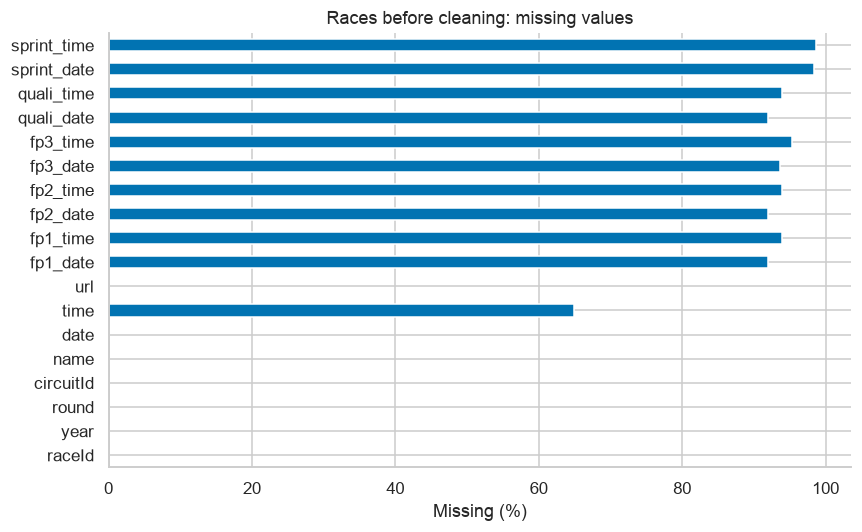

In [46]:
races_missing["Missing percentage"].plot.barh(figsize=(8, 5))
plt.title("Races before cleaning: missing values")
plt.xlabel("Missing (%)")
plt.tight_layout()
show_plot("cleaning_062")

In [47]:
columns_to_drop = [
    "url",
    "fp1_date", "fp1_time",
    "fp2_date", "fp2_time",
    "fp3_date", "fp3_time",
    "quali_date", "quali_time",
    "sprint_date", "sprint_time"
]

races_clean = races.drop(columns=columns_to_drop).copy()

races_clean["date"] = pd.to_datetime(
    races_clean["date"],
    format="%Y-%m-%d"
)

races_clean["time"] = pd.to_datetime(
    races_clean["time"],
    format="%H:%M:%S"
).dt.time

In [48]:
# Display any races whose date year differs from the year column
display(races_clean[
    races_clean["date"].dt.year != races_clean["year"]
])

,raceId,year,round,circuitId,name,date,time


In [49]:
compare_cleaning(races, races_clean)

Rows: 1,125 → 1,125
Columns: 18 → 7


,Type before,Type after,Missing before,Missing after
circuitId,int64,int64,0,0.0
date,str,datetime64[us],0,0.0
fp1_date,str,—,1035,—
fp1_time,str,—,1057,—
fp2_date,str,—,1035,—
fp2_time,str,—,1057,—
fp3_date,str,—,1053,—
fp3_time,str,—,1072,—
name,str,str,0,0.0
quali_date,str,—,1035,—


All 1,125 races remain. Dates agree with the year column. The 731 unavailable race start times remain missing; parsed clock times have pandas `object` dtype.

## 6. Status
This lookup explains how an entry ended. Check IDs and inspect the labels; no cleaning change is needed.

In [50]:
status_clean = status.copy()

display(status_clean.head(15))

print("Number of statuses:", len(status_clean))

status_clean.info()

,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine
5,6,Gearbox
6,7,Transmission
7,8,Clutch
8,9,Hydraulics
9,10,Electrical


Number of statuses: 139
<class 'pandas.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   statusId  139 non-null    int64
 1   status    139 non-null    str  
dtypes: int64(1), str(1)
memory usage: 2.3 KB


In [51]:
print("Missing values:")
print(status_clean.isna().sum())

print(
    "Repeated status IDs:",
    status_clean["statusId"].duplicated().sum()
)

print(
    "Completely repeated rows:",
    status_clean.duplicated().sum()
)

print(
    status_clean.sort_values("statusId").to_string(index=False)
)

Missing values:
statusId    0
status      0
dtype: int64
Repeated status IDs: 0
Completely repeated rows: 0
 statusId             status
        1           Finished
        2       Disqualified
        3           Accident
        4          Collision
        5             Engine
        6            Gearbox
        7       Transmission
        8             Clutch
        9         Hydraulics
       10         Electrical
       11             +1 Lap
       12            +2 Laps
       13            +3 Laps
       14            +4 Laps
       15            +5 Laps
       16            +6 Laps
       17            +7 Laps
       18            +8 Laps
       19            +9 Laps
       20           Spun off
       21           Radiator
       22         Suspension
       23             Brakes
       24       Differential
       25        Overheating
       26         Mechanical
       27               Tyre
       28        Driver Seat
       29           Puncture
       30         Driv

In [52]:
compare_cleaning(status, status_clean)

Rows: 139 → 139
Columns: 2 → 2


,Type before,Type after,Missing before,Missing after
statusId,int64,int64,0,0
status,str,str,0,0


All 139 status records are complete and unique. Keep the lookup unchanged.

## 7. Seasons
Check unique years and coverage of race seasons. Remove the reference URL.

In [53]:
seasons_clean = seasons.copy()

display(seasons_clean.head())

seasons_clean.info()

print("Missing values:")
print(seasons_clean.isna().sum())

print(
    "Repeated years:",
    seasons_clean["year"].duplicated().sum()
)

print(
    "Race years absent from seasons:",
    (~races_clean["year"].isin(seasons_clean["year"])).sum()
)

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


<class 'pandas.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   year    75 non-null     int64
 1   url     75 non-null     str  
dtypes: int64(1), str(1)
memory usage: 1.3 KB
Missing values:
year    0
url     0
dtype: int64
Repeated years: 0
Race years absent from seasons: 0


In [54]:
seasons_clean = seasons.drop(columns=["url"]).copy()

display(seasons_clean.head())

,year
0,2009
1,2008
2,2007
3,2006
4,2005


In [55]:
compare_cleaning(seasons, seasons_clean)

Rows: 75 → 75
Columns: 2 → 1


,Type before,Type after,Missing before,Missing after
url,str,—,0,—
year,int64,int64,0,0.0


All 75 season years remain; every race year appears in this table.

## 8. Qualifying
Check entry IDs, driver–race uniqueness and historical coverage. Keep missing session times: absence can reflect non-participation, the qualifying format, or unavailable records. Missingness alone cannot distinguish these reasons.

In [56]:
qualifying_clean = qualifying.copy()

display(qualifying_clean.head())

print("Number of qualifying entries:", len(qualifying_clean))

qualifying_clean.info()

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


Number of qualifying entries: 10494
<class 'pandas.DataFrame'>
RangeIndex: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   qualifyId      10494 non-null  int64
 1   raceId         10494 non-null  int64
 2   driverId       10494 non-null  int64
 3   constructorId  10494 non-null  int64
 4   number         10494 non-null  int64
 5   position       10494 non-null  int64
 6   q1             10338 non-null  str  
 7   q2             5847 non-null   str  
 8   q3             3629 non-null   str  
dtypes: int64(6), str(3)
memory usage: 738.0 KB


In [57]:
qualifying_missing = pd.DataFrame({
    "Missing count": qualifying_clean.isna().sum(),
    "Missing percentage": (
        qualifying_clean.isna().sum() / len(qualifying_clean) * 100
    ).round(2)
})

display(qualifying_missing)

print(
    "Missing qualifying IDs:",
    qualifying_clean["qualifyId"].isna().sum()
)

print(
    "Repeated qualifying IDs:",
    qualifying_clean["qualifyId"].duplicated().sum()
)

print(
    "Repeated driver-race combinations:",
    qualifying_clean.duplicated(["raceId", "driverId"]).sum()
)

print(
    "Completely repeated rows:",
    qualifying_clean.duplicated().sum()
)

print(
    "Unknown race IDs:",
    (~qualifying_clean["raceId"].isin(races_clean["raceId"])).sum()
)

print(
    "Unknown driver IDs:",
    (~qualifying_clean["driverId"].isin(drivers_clean["driverId"])).sum()
)

print(
    "Unknown constructor IDs:",
    (~qualifying_clean["constructorId"].isin(
        constructors_clean["constructorId"]
    )).sum()
)

,Missing count,Missing percentage
qualifyId,0,0.00
raceId,0,0.00
driverId,0,0.00
constructorId,0,0.00
number,0,0.00
position,0,0.00
q1,156,1.49
q2,4647,44.28
q3,6865,65.42


Missing qualifying IDs: 0
Repeated qualifying IDs: 0
Repeated driver-race combinations: 0
Completely repeated rows: 0
Unknown race IDs: 0
Unknown driver IDs: 0
Unknown constructor IDs: 0


In [58]:
# Add the season for inspection
qualifying_by_year = qualifying_clean.merge(
    races_clean[["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

display(qualifying_by_year.groupby("year").size())

year
1994    392
1995    418
1996    148
1997    220
1998    153
1999     65
2000     88
2001     22
2002     42
2003    320
2004    360
2005    376
2006    396
2007    374
2008    368
2009    340
2010    456
2011    452
2012    476
2013    418
2014    405
2015    374
2016    457
2017    398
2018    420
2019    418
2020    340
2021    439
2022    440
2023    440
2024    479
dtype: int64

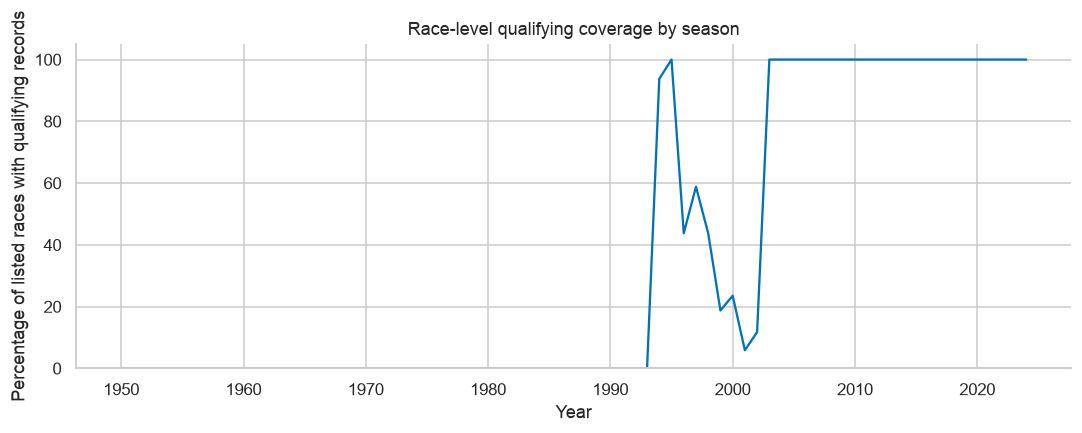

In [59]:
# Number of races listed in each season
races_per_year = races_clean.groupby("year")["raceId"].nunique()

# Number of races with at least one qualifying record
qualifying_races_per_year = (
    qualifying_by_year.groupby("year")["raceId"].nunique()
)

# Include seasons with no qualifying records
qualifying_races_per_year = qualifying_races_per_year.reindex(
    races_per_year.index,
    fill_value=0
)

coverage_percentage = (
    qualifying_races_per_year / races_per_year * 100
)

coverage_percentage.plot(figsize=(10, 4))

plt.title("Race-level qualifying coverage by season")
plt.xlabel("Year")
plt.ylabel("Percentage of listed races with qualifying records")
plt.ylim(0, 105)
plt.tight_layout()
show_plot("cleaning_081")

Coverage begins in 1994 and varies in the early years. The chart measures races with at least one qualifying record, not completeness for every driver.

In [60]:
qualifying_clean["q1_seconds"] = (
    qualifying_clean["q1"].apply(convert_to_seconds)
)

qualifying_clean["q2_seconds"] = (
    qualifying_clean["q2"].apply(convert_to_seconds)
)

qualifying_clean["q3_seconds"] = (
    qualifying_clean["q3"].apply(convert_to_seconds)
)

display(qualifying_clean[
    ["q1", "q1_seconds", "q2", "q2_seconds", "q3", "q3_seconds"]
].head(10))

,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236
5,1:26.427,86.427,1:26.101,86.101,1:28.527,88.527
6,1:26.295,86.295,1:26.059,86.059,1:28.687,88.687
7,1:26.381,86.381,1:26.063,86.063,1:29.041,89.041
8,1:26.919,86.919,1:26.164,86.164,1:29.593,89.593
9,1:26.702,86.702,1:25.842,85.842,NaN,NaN


In [61]:
for session in ["q1", "q2", "q3"]:
    print(
        session,
        "| Missing before:", qualifying_clean[session].isna().sum(),
        "| Missing after:", qualifying_clean[session + "_seconds"].isna().sum()
    )

for column in ["q1_seconds", "q2_seconds", "q3_seconds"]:
    print(
        column,
        "| Zero or negative times:",
        (qualifying_clean[column] <= 0).sum()
    )

print(
    "Zero or negative qualifying positions:",
    (qualifying_clean["position"] <= 0).sum()
)

q1 | Missing before: 156 | Missing after: 156
q2 | Missing before: 4647 | Missing after: 4647
q3 | Missing before: 6865 | Missing after: 6865
q1_seconds | Zero or negative times: 0
q2_seconds | Zero or negative times: 0
q3_seconds | Zero or negative times: 0
Zero or negative qualifying positions: 0


In [62]:
compare_cleaning(qualifying, qualifying_clean)

Rows: 10,494 → 10,494
Columns: 9 → 12


,Type before,Type after,Missing before,Missing after
constructorId,int64,int64,0.0,0
driverId,int64,int64,0.0,0
number,int64,int64,0.0,0
position,int64,int64,0.0,0
q1,str,str,156.0,156
q1_seconds,—,float64,—,156
q2,str,str,4647.0,4647
q2_seconds,—,float64,—,4647
q3,str,str,6865.0,6865
q3_seconds,—,float64,—,6865


All 10,494 entries remain. Three seconds columns were added without filling or losing recorded times; missing Q1/Q2/Q3 counts remain 156/4,647/6,865. No nonpositive recorded qualifying times or positions were found.

## 9. Driver standings
These are championship standings after each race. Check keys, references, points, positions and wins; keep the table unchanged if checks reveal no issue.

In [63]:
driver_standings_clean = driver_standings.copy()

display(driver_standings_clean.head())

print("Number of entries:", len(driver_standings_clean))

driver_standings_clean.info()

,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


Number of entries: 34863
<class 'pandas.DataFrame'>
RangeIndex: 34863 entries, 0 to 34862
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driverStandingsId  34863 non-null  int64  
 1   raceId             34863 non-null  int64  
 2   driverId           34863 non-null  int64  
 3   points             34863 non-null  float64
 4   position           34863 non-null  int64  
 5   positionText       34863 non-null  str    
 6   wins               34863 non-null  int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 1.9 MB


In [64]:
print("Missing values:")
print(driver_standings_clean.isna().sum())

print(
    "Repeated standings IDs:",
    driver_standings_clean["driverStandingsId"].duplicated().sum()
)

print(
    "Repeated driver-race combinations:",
    driver_standings_clean.duplicated(["raceId", "driverId"]).sum()
)

print(
    "Completely repeated rows:",
    driver_standings_clean.duplicated().sum()
)

print(
    "Unknown race IDs:",
    (~driver_standings_clean["raceId"].isin(
        races_clean["raceId"]
    )).sum()
)

print(
    "Unknown driver IDs:",
    (~driver_standings_clean["driverId"].isin(
        drivers_clean["driverId"]
    )).sum()
)

Missing values:
driverStandingsId    0
raceId               0
driverId             0
points               0
position             0
positionText         0
wins                 0
dtype: int64
Repeated standings IDs: 0
Repeated driver-race combinations: 0
Completely repeated rows: 0
Unknown race IDs: 0
Unknown driver IDs: 0


In [65]:
display(driver_standings_clean[
    ["points", "position", "wins"]
].describe())

# Inspect any unusual values without changing them
display(driver_standings_clean[
    (driver_standings_clean["points"] < 0)
    | (driver_standings_clean["position"] <= 0)
    | (driver_standings_clean["wins"] < 0)
])

,points,position,wins
count,34863.000000,34863.000000,34863.000000
mean,14.704423,19.716720,0.277343
std,38.978094,16.293401,1.032618
min,0.000000,1.000000,0.000000
25%,0.000000,8.000000,0.000000
50%,1.000000,16.000000,0.000000
75%,10.000000,26.000000,0.000000
max,575.000000,108.000000,19.000000


,driverStandingsId,raceId,driverId,points,position,positionText,wins


In [66]:
compare_cleaning(driver_standings, driver_standings_clean)

Rows: 34,863 → 34,863
Columns: 7 → 7


,Type before,Type after,Missing before,Missing after
driverStandingsId,int64,int64,0,0
raceId,int64,int64,0,0
driverId,int64,int64,0,0
points,float64,float64,0,0
position,int64,int64,0,0
positionText,str,str,0,0
wins,int64,int64,0,0


All 34,863 records are retained. No missing values, repeated driver–race pairs, invalid references or values failing the displayed range checks were found.

## 10. Constructor standings
Check championship standings at one constructor per race, including IDs, references and numeric ranges.

In [67]:
constructor_standings_clean = constructor_standings.copy()

display(constructor_standings_clean.head())

print("Number of entries:", len(constructor_standings_clean))

constructor_standings_clean.info()

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


Number of entries: 13391
<class 'pandas.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  str    
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 732.4 KB


In [68]:
print("Missing values:")
print(constructor_standings_clean.isna().sum())

print(
    "Repeated standings IDs:",
    constructor_standings_clean["constructorStandingsId"].duplicated().sum()
)

print(
    "Repeated team-race combinations:",
    constructor_standings_clean.duplicated(
        ["raceId", "constructorId"]
    ).sum()
)

print(
    "Completely repeated rows:",
    constructor_standings_clean.duplicated().sum()
)

print(
    "Unknown race IDs:",
    (~constructor_standings_clean["raceId"].isin(
        races_clean["raceId"]
    )).sum()
)

print(
    "Unknown constructor IDs:",
    (~constructor_standings_clean["constructorId"].isin(
        constructors_clean["constructorId"]
    )).sum()
)

Missing values:
constructorStandingsId    0
raceId                    0
constructorId             0
points                    0
position                  0
positionText              0
wins                      0
dtype: int64
Repeated standings IDs: 0
Repeated team-race combinations: 0
Completely repeated rows: 0
Unknown race IDs: 0
Unknown constructor IDs: 0


In [69]:
display(constructor_standings_clean[
    ["points", "position", "wins"]
].describe())

# Display values that need investigation
display(constructor_standings_clean[
    (constructor_standings_clean["points"] < 0)
    | (constructor_standings_clean["position"] <= 0)
    | (constructor_standings_clean["wins"] < 0)
])

,points,position,wins
count,13391.000000,13391.000000,13391.000000
mean,37.178515,7.226047,0.697409
std,84.346048,4.355923,1.879569
min,0.000000,1.000000,0.000000
25%,0.000000,4.000000,0.000000
50%,7.000000,7.000000,0.000000
75%,33.000000,10.000000,0.000000
max,860.000000,22.000000,21.000000


,constructorStandingsId,raceId,constructorId,points,position,positionText,wins


In [70]:
compare_cleaning(constructor_standings, constructor_standings_clean)

Rows: 13,391 → 13,391
Columns: 7 → 7


,Type before,Type after,Missing before,Missing after
constructorStandingsId,int64,int64,0,0
raceId,int64,int64,0,0
constructorId,int64,int64,0,0
points,float64,float64,0,0
position,int64,int64,0,0
positionText,str,str,0,0
wins,int64,int64,0,0


All 13,391 records remain unchanged. Missingness, key, reference and displayed range checks reveal no issue.

## 11. Constructor results
These are race-level constructor results. Inspect the sparse status field before applying the previously agreed column removal.

In [71]:
constructor_results_clean = constructor_results.copy()

display(constructor_results_clean.head())

print("Number of entries:", len(constructor_results_clean))

constructor_results_clean.info()

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


Number of entries: 12625
<class 'pandas.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                17 non-null     str    
dtypes: float64(1), int64(3), str(1)
memory usage: 493.3 KB


In [72]:
print("Missing values:")
print(constructor_results_clean.isna().sum())

print(
    "Repeated result IDs:",
    constructor_results_clean["constructorResultsId"].duplicated().sum()
)

print(
    "Repeated team-race combinations:",
    constructor_results_clean.duplicated(
        ["raceId", "constructorId"]
    ).sum()
)

print(
    "Completely repeated rows:",
    constructor_results_clean.duplicated().sum()
)

print(
    "Unknown race IDs:",
    (~constructor_results_clean["raceId"].isin(
        races_clean["raceId"]
    )).sum()
)

print(
    "Unknown constructor IDs:",
    (~constructor_results_clean["constructorId"].isin(
        constructors_clean["constructorId"]
    )).sum()
)

Missing values:
constructorResultsId        0
raceId                      0
constructorId               0
points                      0
status                  12608
dtype: int64
Repeated result IDs: 0
Repeated team-race combinations: 0
Completely repeated rows: 0
Unknown race IDs: 0
Unknown constructor IDs: 0


In [73]:
display(constructor_results_clean["points"].describe())

# Include missing values in the status counts
display(constructor_results_clean["status"].value_counts(dropna=False))

# Inspect negative points, if any
display(constructor_results_clean[
    constructor_results_clean["points"] < 0
])

display(constructor_results_clean[
    constructor_results_clean["status"].notna()
])

count    12625.000000
mean         4.053545
std          7.862202
min          0.000000
25%          0.000000
50%          0.000000
75%          5.000000
max         66.000000
Name: points, dtype: float64

status
NaN    12608
D         17
Name: count, dtype: int64

,constructorResultsId,raceId,constructorId,points,status


,constructorResultsId,raceId,constructorId,points,status
185,186,36,1,14.0,D
195,196,37,1,18.0,D
207,208,38,1,12.0,D
218,219,39,1,14.0,D
228,229,40,1,18.0,D
239,240,41,1,12.0,D
250,251,42,1,18.0,D
262,263,43,1,8.0,D
273,274,44,1,14.0,D
283,284,45,1,10.0,D


`status` contains 17 `D` values and 12,608 missing values. Preserve the existing decision to drop it from the cleaned table. Those 17 exception markers are still available in the raw table; dropping the field does not mean they have no meaning.

In [74]:
constructor_results_clean = constructor_results.drop(
    columns=["status"]
).copy()

display(constructor_results_clean.head())

,constructorResultsId,raceId,constructorId,points
0,1,18,1,14.0
1,2,18,2,8.0
2,3,18,3,9.0
3,4,18,4,5.0
4,5,18,5,2.0


In [75]:
compare_cleaning(constructor_results, constructor_results_clean)

Rows: 12,625 → 12,625
Columns: 5 → 4


,Type before,Type after,Missing before,Missing after
constructorId,int64,int64,0,0.0
constructorResultsId,int64,int64,0,0.0
points,float64,float64,0,0.0
raceId,int64,int64,0,0.0
status,str,—,12608,—


All 12,625 rows and their points are retained. The four remaining columns have no missing values.

## 12. Sprint results
Check entry IDs and references, then inspect missing values alongside race-ending statuses. Do not invent finishing positions or timings for incomplete entries.

In [76]:
sprint_results_clean = sprint_results.copy()

display(sprint_results_clean.head())

print("Number of entries:", len(sprint_results_clean))

sprint_results_clean.info()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1.0,1,1,3,17,25:38.426,1538426.0,14.0,1:30.013,1
1,2,1061,1,131,44,1,2.0,2,2,2,17,+1.430,1539856.0,17.0,1:29.937,1
2,3,1061,822,131,77,3,3.0,3,3,1,17,+7.502,1545928.0,17.0,1:29.958,1
3,4,1061,844,6,16,4,4.0,4,4,0,17,+11.278,1549704.0,16.0,1:30.163,1
4,5,1061,846,1,4,6,5.0,5,5,0,17,+24.111,1562537.0,16.0,1:30.566,1


Number of entries: 360
<class 'pandas.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    float64
 7   positionText    360 non-null    str    
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time            340 non-null    str    
 12  milliseconds    340 non-null    float64
 13  fastestLap      351 non-null    float64
 14  fastestLapTime  351 non-null    str    
 15  statusId        360 non-null    int64  
dtypes: float64(3), int64(10), str(3)
memory usage: 45.1 KB


In [77]:
sprint_missing = pd.DataFrame({
    "Missing count": sprint_results_clean.isna().sum(),
    "Missing percentage": (
        sprint_results_clean.isna().sum()
        / len(sprint_results_clean) * 100
    ).round(2)
})

display(sprint_missing)

print(
    "Repeated result IDs:",
    sprint_results_clean["resultId"].duplicated().sum()
)

print(
    "Repeated driver-race combinations:",
    sprint_results_clean.duplicated(["raceId", "driverId"]).sum()
)

print(
    "Completely repeated rows:",
    sprint_results_clean.duplicated().sum()
)

print(
    "Unknown races:",
    (~sprint_results_clean["raceId"].isin(races_clean["raceId"])).sum()
)

print(
    "Unknown drivers:",
    (~sprint_results_clean["driverId"].isin(drivers_clean["driverId"])).sum()
)

print(
    "Unknown constructors:",
    (~sprint_results_clean["constructorId"].isin(
        constructors_clean["constructorId"]
    )).sum()
)

print(
    "Unknown statuses:",
    (~sprint_results_clean["statusId"].isin(status_clean["statusId"])).sum()
)

,Missing count,Missing percentage
resultId,0,0.00
raceId,0,0.00
driverId,0,0.00
constructorId,0,0.00
number,0,0.00
grid,0,0.00
position,15,4.17
positionText,0,0.00
positionOrder,0,0.00
points,0,0.00


Repeated result IDs: 0
Repeated driver-race combinations: 0
Completely repeated rows: 0
Unknown races: 0
Unknown drivers: 0
Unknown constructors: 0
Unknown statuses: 0


In [78]:
# Columns we want to investigate
columns_with_missing = [
    "position",
    "time",
    "milliseconds",
    "fastestLap",
    "fastestLapTime"
]

# Select rows missing at least one of these values
missing_rows = sprint_results_clean[
    sprint_results_clean[columns_with_missing].isna().any(axis=1)
]

# Add readable status descriptions
missing_details = missing_rows.merge(
    status_clean,
    on="statusId",
    how="left",
    validate="many_to_one"
)

display(missing_details[
    [
        "raceId", "driverId",
        "position", "positionText", "positionOrder",
        "laps", "time", "milliseconds",
        "fastestLap", "fastestLapTime", "status"
    ]
])

,raceId,driverId,position,positionText,positionOrder,laps,time,milliseconds,fastestLap,fastestLapTime,status
0,1061,815,NaN,R,20,16,NaN,NaN,6.0,1:31.465,Vibrations
1,1065,842,NaN,R,20,0,NaN,NaN,NaN,NaN,Accident
2,1077,855,NaN,R,20,0,NaN,NaN,NaN,NaN,Retired
3,1084,20,19.0,19,19,21,NaN,NaN,4.0,1:10.317,Collision damage
4,1084,4,NaN,N,20,0,NaN,NaN,NaN,NaN,Electrical
5,1095,848,NaN,R,20,12,NaN,NaN,4.0,1:15.998,Retired
6,1101,852,NaN,R,19,2,NaN,NaN,NaN,NaN,Collision damage
7,1101,858,NaN,W,20,0,NaN,NaN,NaN,NaN,Accident
8,1110,815,NaN,R,19,8,NaN,NaN,2.0,2:02.516,Collision damage
9,1110,4,NaN,R,20,2,NaN,NaN,NaN,NaN,Accident


Convert whole-number fields to nullable integers and durations to seconds. Keep elapsed times separate from reported gaps, as in results.

In [79]:
# Store whole numbers while allowing missing values
for column in ["position", "milliseconds", "fastestLap"]:
    sprint_results_clean[column] = (
        sprint_results_clean[column].astype("Int64")
    )

sprint_results_clean["fastest_lap_seconds"] = (
    sprint_results_clean["fastestLapTime"].apply(convert_to_seconds)
)

time_seconds = sprint_results_clean["time"].apply(convert_to_seconds)

is_gap = sprint_results_clean["time"].str.startswith("+", na=False)

sprint_results_clean["reported_elapsed_seconds"] = (
    time_seconds.where(~is_gap)
)

sprint_results_clean["reported_gap_seconds"] = (
    time_seconds.where(is_gap)
)

In [80]:
print("Rows before:", len(sprint_results))
print("Rows after:", len(sprint_results_clean))

print(
    "Missing finishing orders:",
    sprint_results_clean["positionOrder"].isna().sum()
)

Rows before: 360
Rows after: 360
Missing finishing orders: 0


In [81]:
compare_cleaning(sprint_results, sprint_results_clean)

Rows: 360 → 360
Columns: 16 → 19


,Type before,Type after,Missing before,Missing after
constructorId,int64,int64,0.0,0
driverId,int64,int64,0.0,0
fastestLap,float64,Int64,9.0,9
fastestLapTime,str,str,9.0,9
fastest_lap_seconds,—,float64,—,9
grid,int64,int64,0.0,0
laps,int64,int64,0.0,0
milliseconds,float64,Int64,20.0,20
number,int64,int64,0.0,0
points,int64,int64,0.0,0


All 360 entries remain. The 15 missing positions, 20 missing time/millisecond values and nine missing fastest-lap values are retained. The status inspection provides context, not a reliable replacement value.

## 13. Lap times
The key is `(raceId, driverId, lap)`. Check repeated laps even if their position or time differs. Convert recorded milliseconds to seconds without changing source values.

In [82]:
lap_times_clean = lap_times.copy()

display(lap_times_clean.head())

print("Number of lap records:", len(lap_times_clean))

lap_times_clean.info()

,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342


Number of lap records: 589081
<class 'pandas.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   raceId        589081 non-null  int64
 1   driverId      589081 non-null  int64
 2   lap           589081 non-null  int64
 3   position      589081 non-null  int64
 4   time          589081 non-null  str  
 5   milliseconds  589081 non-null  int64
dtypes: int64(5), str(1)
memory usage: 27.0 MB


In [83]:
print("Missing values:")
print(lap_times_clean.isna().sum())

print(
    "Repeated driver-race-lap combinations:",
    lap_times_clean.duplicated(
        ["raceId", "driverId", "lap"]
    ).sum()
)

print(
    "Completely repeated rows:",
    lap_times_clean.duplicated().sum()
)

print(
    "Unknown race IDs:",
    (~lap_times_clean["raceId"].isin(races_clean["raceId"])).sum()
)

print(
    "Unknown driver IDs:",
    (~lap_times_clean["driverId"].isin(drivers_clean["driverId"])).sum()
)

Missing values:


raceId          0
driverId        0
lap             0
position        0
time            0
milliseconds    0
dtype: int64
Repeated driver-race-lap combinations: 0


Completely repeated rows: 0
Unknown race IDs: 0
Unknown driver IDs: 0


In [84]:
display(lap_times_clean[["lap", "position", "milliseconds"]].describe())

# Display zero or negative values for investigation
display(lap_times_clean[
    (lap_times_clean["lap"] <= 0)
    | (lap_times_clean["position"] <= 0)
    | (lap_times_clean["milliseconds"] <= 0)
])

repeated_laps = lap_times_clean[
    lap_times_clean.duplicated(
        ["raceId", "driverId", "lap"],
        keep=False
    )
]

display(repeated_laps.sort_values(["raceId", "driverId", "lap"]))

,lap,position,milliseconds
count,589081.000000,589081.000000,5.890810e+05
mean,30.018104,9.661951,9.579945e+04
std,18.407126,5.528553,7.639973e+04
min,1.000000,1.000000,5.540400e+04
25%,14.000000,5.000000,8.204100e+04
50%,29.000000,9.000000,9.060800e+04
75%,44.000000,14.000000,1.019300e+05
max,87.000000,24.000000,7.507547e+06


,raceId,driverId,lap,position,time,milliseconds


,raceId,driverId,lap,position,time,milliseconds


In [85]:
lap_times_clean["lap_seconds"] = (
    lap_times_clean["milliseconds"] / 1000
)

In [86]:
compare_cleaning(lap_times, lap_times_clean)

Rows: 589,081 → 589,081
Columns: 6 → 7


,Type before,Type after,Missing before,Missing after
driverId,int64,int64,0.0,0
lap,int64,int64,0.0,0
lap_seconds,—,float64,—,0
milliseconds,int64,int64,0.0,0
position,int64,int64,0.0,0
raceId,int64,int64,0.0,0
time,str,str,0.0,0


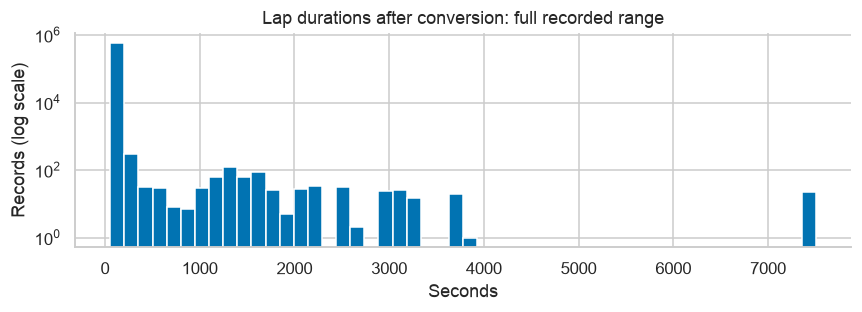

,raceId,driverId,lap,position,time,milliseconds,lap_seconds
8372,847,2,25,4,2:05:07.547,7507547,7507.547
8020,847,13,25,3,2:05:06.656,7506656,7506.656
8426,847,808,25,5,2:05:06.243,7506243,7506.243
8621,847,155,25,2,2:05:06.095,7506095,7506.095
7916,847,20,25,1,2:05:05.152,7505152,7505.152


In [87]:
lap_times_clean["lap_seconds"].plot.hist(bins=50, logy=True, figsize=(8, 3))
plt.title("Lap durations after conversion: full recorded range")
plt.xlabel("Seconds")
plt.ylabel("Records (log scale)")
plt.tight_layout()
show_plot("cleaning_122")
display(lap_times_clean.nlargest(5, "lap_seconds"))

All 589,081 laps remain, with no missing values or repeated keys. The long duration tail is visible rather than clipped. Unusually long records are retained; their causes are not inferred from duration alone.

## 14. Pit stops
The key is `(raceId, driverId, stop)`. Check references and numeric ranges; convert duration to seconds and clock time to a time value.

In [88]:
pit_stops_clean = pit_stops.copy()

display(pit_stops_clean.head())

print("Number of pit stops:", len(pit_stops_clean))

pit_stops_clean.info()

,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842


Number of pit stops: 11371
<class 'pandas.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   raceId        11371 non-null  int64
 1   driverId      11371 non-null  int64
 2   stop          11371 non-null  int64
 3   lap           11371 non-null  int64
 4   time          11371 non-null  str  
 5   duration      11371 non-null  str  
 6   milliseconds  11371 non-null  int64
dtypes: int64(5), str(2)
memory usage: 622.0 KB


In [89]:
print("Missing values:")
print(pit_stops_clean.isna().sum())

print(
    "Repeated driver-race-stop combinations:",
    pit_stops_clean.duplicated(
        ["raceId", "driverId", "stop"]
    ).sum()
)

print(
    "Completely repeated rows:",
    pit_stops_clean.duplicated().sum()
)

print(
    "Unknown race IDs:",
    (~pit_stops_clean["raceId"].isin(races_clean["raceId"])).sum()
)

print(
    "Unknown driver IDs:",
    (~pit_stops_clean["driverId"].isin(drivers_clean["driverId"])).sum()
)

Missing values:
raceId          0
driverId        0
stop            0
lap             0
time            0
duration        0
milliseconds    0
dtype: int64
Repeated driver-race-stop combinations: 0
Completely repeated rows: 0
Unknown race IDs: 0
Unknown driver IDs: 0


In [90]:
display(pit_stops_clean[["stop", "lap", "milliseconds"]].describe())

display(pit_stops_clean[
    (pit_stops_clean["stop"] <= 0)
    | (pit_stops_clean["lap"] < 0)
    | (pit_stops_clean["milliseconds"] <= 0)
])

,stop,lap,milliseconds
count,11371.000000,11371.000000,1.137100e+04
mean,1.787969,25.387389,8.523050e+04
std,1.521462,14.831497,3.104273e+05
min,1.000000,1.000000,1.289700e+04
25%,1.000000,13.000000,2.193750e+04
50%,2.000000,25.000000,2.360600e+04
75%,2.000000,36.000000,2.654400e+04
max,70.000000,78.000000,3.069017e+06


,raceId,driverId,stop,lap,time,duration,milliseconds


In [91]:
# Convert recorded duration from milliseconds to seconds
pit_stops_clean["duration_seconds"] = (
    pit_stops_clean["milliseconds"] / 1000
)

# Convert the recorded clock time into a time value
pit_stops_clean["time"] = pd.to_datetime(
    pit_stops_clean["time"],
    format="%H:%M:%S"
).dt.time

display(pit_stops_clean.nlargest(10, "duration_seconds")[
    ["raceId", "driverId", "stop", "lap", "duration", "duration_seconds"]
])

,raceId,driverId,stop,lap,duration,duration_seconds
9156,1083,840,1,1,51:09.017,3069.017
9155,1083,20,1,1,51:07.301,3067.301
9157,1083,854,1,1,51:05.174,3065.174
9154,1083,825,1,1,51:03.613,3063.613
9152,1083,817,1,1,51:03.314,3063.314
9151,1083,822,1,1,50:55.732,3055.732
9147,1083,4,1,1,50:55.700,3055.700
9150,1083,849,1,1,50:51.904,3051.904
9153,1083,842,1,1,50:48.950,3048.950
9145,1083,1,1,1,50:46.888,3046.888


In [92]:
compare_cleaning(pit_stops, pit_stops_clean)

Rows: 11,371 → 11,371
Columns: 7 → 8


,Type before,Type after,Missing before,Missing after
driverId,int64,int64,0.0,0
duration,str,str,0.0,0
duration_seconds,—,float64,—,0
lap,int64,int64,0.0,0
milliseconds,int64,int64,0.0,0
raceId,int64,int64,0.0,0
stop,int64,int64,0.0,0
time,str,object,0.0,0


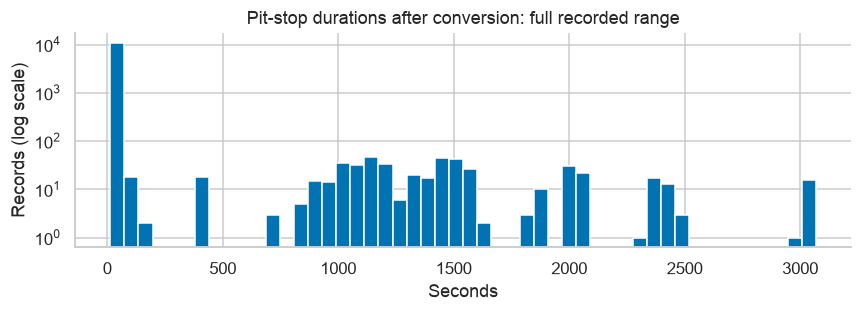

In [93]:
pit_stops_clean["duration_seconds"].plot.hist(bins=50, logy=True, figsize=(8, 3))
plt.title("Pit-stop durations after conversion: full recorded range")
plt.xlabel("Seconds")
plt.ylabel("Records (log scale)")
plt.tight_layout()
show_plot("cleaning_130")

All 11,371 records remain. No missing values, repeated keys or nonpositive durations were found. Long durations and unusual stop counts are left intact; they require context before exclusion.

## 15. Overall comparison and final audit
The following tables summarize the completed dataset sections. Missing-value totals compare shared columns only, so dropping a column is not presented as filling its values.

In [94]:
# Match each original table with its cleaned version
table_pairs = [
    ("results", results, results_clean),
    ("drivers", drivers, drivers_clean),
    ("constructors", constructors, constructors_clean),
    ("circuits", circuits, circuits_clean),
    ("races", races, races_clean),
    ("status", status, status_clean),
    ("seasons", seasons, seasons_clean),
    ("qualifying", qualifying, qualifying_clean),
    ("driver_standings", driver_standings, driver_standings_clean),
    ("constructor_standings", constructor_standings, constructor_standings_clean),
    ("constructor_results", constructor_results, constructor_results_clean),
    ("sprint_results", sprint_results, sprint_results_clean),
    ("lap_times", lap_times, lap_times_clean),
    ("pit_stops", pit_stops, pit_stops_clean)
]

summary_rows = []

for name, original, cleaned in table_pairs:
    # Identify columns removed from the working copy
    removed_columns = original.columns.difference(cleaned.columns)

    summary_rows.append({
        "File": name,
        "Rows before": len(original),
        "Rows after": len(cleaned),
        "Columns before": len(original.columns),
        "Columns after": len(cleaned.columns),
        "Removed columns": ", ".join(removed_columns)
    })

cleaning_summary = pd.DataFrame(summary_rows).set_index("File")

display(cleaning_summary)

,Rows before,Rows after,Columns before,Columns after,Removed columns
File,,,,,
results,26759,26759,18,22,
drivers,861,861,9,6,"code, number, url"
constructors,212,212,5,4,url
circuits,77,77,9,8,url
races,1125,1125,18,7,"fp1_date, fp1_time, fp2_date, fp2_time, fp3_da..."
status,139,139,2,2,
seasons,75,75,2,1,url
qualifying,10494,10494,9,12,
driver_standings,34863,34863,7,7,


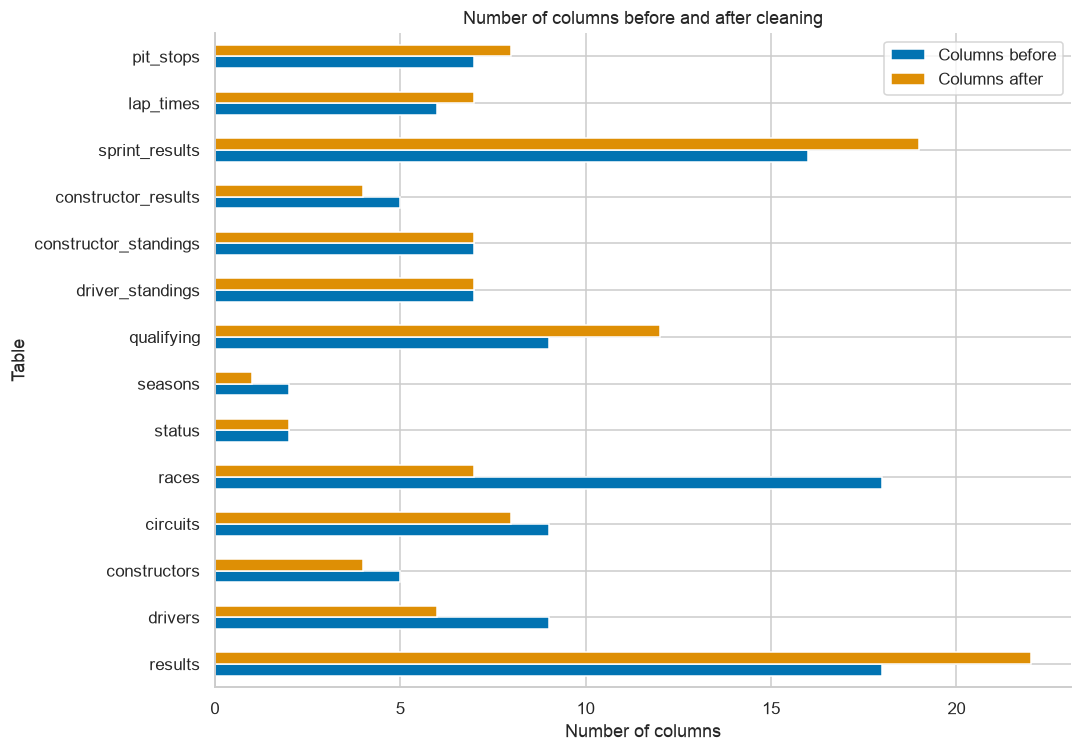

In [95]:
cleaning_summary[
    ["Columns before", "Columns after"]
].plot.barh(figsize=(10, 7))

plt.title("Number of columns before and after cleaning")
plt.xlabel("Number of columns")
plt.ylabel("Table")
plt.tight_layout()
show_plot("cleaning_134")

In [96]:
missing_rows = []

for name, original, cleaned in table_pairs:
    # Compare only columns present in both versions
    common_columns = original.columns.intersection(cleaned.columns)

    missing_rows.append({
        "File": name,
        "Before cleaning": original[common_columns].isna().sum().sum(),
        "After cleaning": cleaned[common_columns].isna().sum().sum()
    })

missing_summary = pd.DataFrame(missing_rows).set_index("File")

display(missing_summary)

,Before cleaning,After cleaning
File,,
results,122887,123143
drivers,0,0
constructors,0,0
circuits,0,0
races,731,731
status,0,0
seasons,0,0
qualifying,11668,11668
driver_standings,0,0


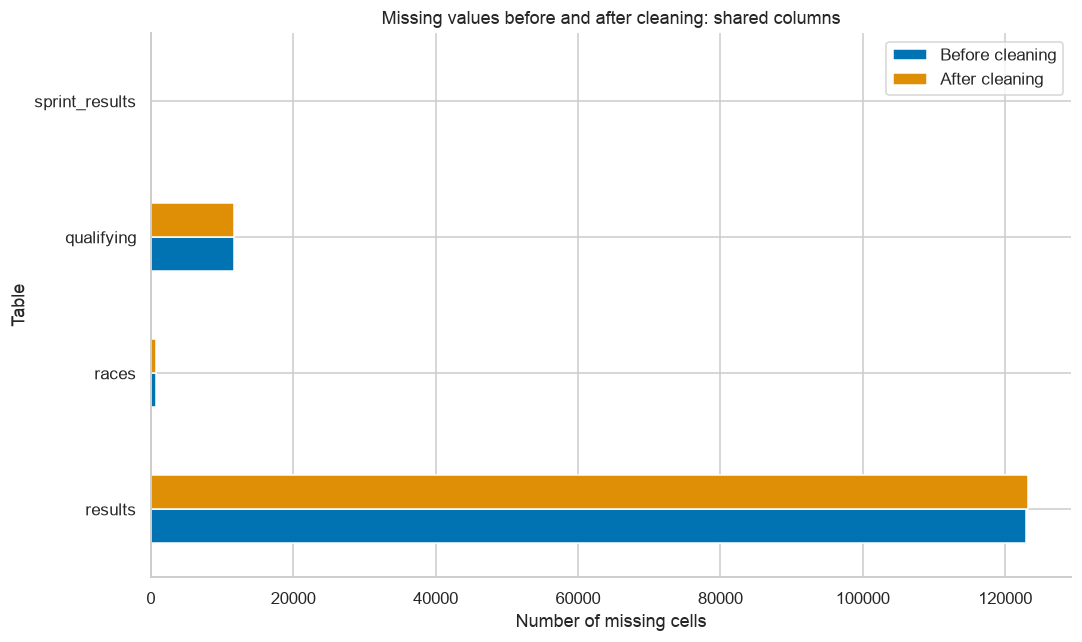

In [97]:
# Only display tables that contain missing values
tables_with_missing = missing_summary[
    (missing_summary > 0).any(axis=1)
]

tables_with_missing.plot.barh(figsize=(10, 6))

plt.title("Missing values before and after cleaning: shared columns")
plt.xlabel("Number of missing cells")
plt.ylabel("Table")
plt.tight_layout()
show_plot("cleaning_136")

Row counts are unchanged in all 14 cleaned tables. Columns decrease where fields were deliberately removed and increase where numeric durations or an analysis grid were added. Only the supported position and rank changes alter missingness in retained source columns.

In [98]:
primary_keys = {
    "results": ["resultId"], "drivers": ["driverId"],
    "constructors": ["constructorId"], "circuits": ["circuitId"],
    "races": ["raceId"], "status": ["statusId"], "seasons": ["year"],
    "qualifying": ["qualifyId"], "driver_standings": ["driverStandingsId"],
    "constructor_standings": ["constructorStandingsId"],
    "constructor_results": ["constructorResultsId"], "sprint_results": ["resultId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"]
}
references = {
    "raceId": races_clean["raceId"], "driverId": drivers_clean["driverId"],
    "constructorId": constructors_clean["constructorId"],
    "circuitId": circuits_clean["circuitId"], "statusId": status_clean["statusId"],
    "year": seasons_clean["year"]
}

audit_rows = []
for name, original, cleaned in table_pairs:
    keys = primary_keys[name]
    missing_keys = cleaned[keys].isna().any(axis=1).sum()
    repeated_keys = cleaned.duplicated(keys).sum()
    invalid_references = sum(
        (~cleaned[column].isin(valid_ids)).sum()
        for column, valid_ids in references.items() if column in cleaned
    )
    sentinel_count = cleaned.select_dtypes(include=["object", "string"]).eq(r"\N").sum().sum()
    audit_rows.append({
        "Table": name, "Missing keys": missing_keys, "Repeated keys": repeated_keys,
        "Invalid references": invalid_references, "Literal sentinel values": sentinel_count,
        "Result": "PASS" if missing_keys + repeated_keys + invalid_references + sentinel_count == 0 else "FAIL"
    })

audit_report = pd.DataFrame(audit_rows).set_index("Table")
display(audit_report)

,Missing keys,Repeated keys,Invalid references,Literal sentinel values,Result
Table,,,,,
results,0,0,0,0.0,PASS
drivers,0,0,0,0.0,PASS
constructors,0,0,0,0.0,PASS
circuits,0,0,0,0.0,PASS
races,0,0,0,0.0,PASS
status,0,0,0,0.0,PASS
seasons,0,0,0,0.0,PASS
qualifying,0,0,0,0.0,PASS
driver_standings,0,0,0,0.0,PASS


In [99]:
checks = {
    "Birth dates are datetime": pd.api.types.is_datetime64_any_dtype(drivers_clean["dob"]),
    "Race dates are datetime": pd.api.types.is_datetime64_any_dtype(races_clean["date"]),
    "Race clock times are typed": races_clean["time"].dropna().map(lambda x: isinstance(x, clock_time)).all(),
    "Pit clock times are typed": pit_stops_clean["time"].map(lambda x: isinstance(x, clock_time)).all(),
    "Unique driver–race outcomes": not driver_race_outcomes.duplicated(["raceId", "driverId"]).any(),
    "Complete outcome IDs and finishing orders": driver_race_outcomes[["raceId", "driverId", "positionOrder"]].notna().all().all(),
    "Analysis grids positive or missing": results_clean["grid_for_analysis"].dropna().gt(0).all(),
    "Every source row retained": all(len(before) == len(after) for _, before, after in table_pairs)
}
for name, _, cleaned in table_pairs:
    for column in cleaned:
        if column.endswith("_seconds"):
            checks[f"{name}: {column} is numeric"] = pd.api.types.is_numeric_dtype(cleaned[column])

display(pd.Series(checks, name="Result").map({True: "PASS", False: "FAIL"}).to_frame())
assert audit_report["Result"].eq("PASS").all(), "Review failed table checks."
assert all(checks.values()), "Review failed type or outcome checks."

,Result
Birth dates are datetime,PASS
Race dates are datetime,PASS
Race clock times are typed,PASS
Pit clock times are typed,PASS
Unique driver–race outcomes,PASS
Complete outcome IDs and finishing orders,PASS
Analysis grids positive or missing,PASS
Every source row retained,PASS
results: fastest_lap_seconds is numeric,PASS
results: reported_elapsed_seconds is numeric,PASS


## Stage 1 status
All 14 cleaned tables have before/after comparisons and implemented key, reference, sentinel
and semantic-type checks. The separate outcome table has one entry per driver-race.

Constructor selection follows the complete-row rule. Flagged lap/timing records remain unchanged
and their accuracy remains a limitation. A passing key audit does not validate suspect measurements.
Cleaned DataFrames and output files are recreated by Run All.

In [100]:
decision_audit = pd.DataFrame([
    ["Source-row selection", "PASS", "One original resultId and matching grid/constructor per driver-race"],
    ["Constructor conflicts", "RESOLVED BY RULE", "Best-finish source entry; historical ambiguity disclosed"],
    ["Flagged lap values", "RETAINED; ACCURACY UNRESOLVED", str(len(lap_review)) + " records"],
    ["Flagged timing values", "RETAINED; ACCURACY UNRESOLVED", str(len(timing_review)) + " records"],
    ["Prediction use of flagged fields", "EXCLUDED", "No current-race lap/timing inputs"]
], columns=["Item", "Status", "Treatment"])
display(decision_audit)
save_table(cleaning_summary, "cleaning_summary", index=True)
save_table(audit_report, "audit_report", index=True)
save_table(decision_audit, "cleaning_decisions")

,Item,Status,Treatment
0,Source-row selection,PASS,One original resultId and matching grid/constr...
1,Constructor conflicts,RESOLVED BY RULE,Best-finish source entry; historical ambiguity...
2,Flagged lap values,RETAINED; ACCURACY UNRESOLVED,12 records
3,Flagged timing values,RETAINED; ACCURACY UNRESOLVED,20 records
4,Prediction use of flagged fields,EXCLUDED,No current-race lap/timing inputs


# Stage 2 - Data-Engineering Questions
These questions describe completed races. Outcomes are measurements here, not prediction inputs.
All rates count driver-race appearances. Join cardinality is checked.

In [101]:
analysis = selected_results.merge(races_clean[['raceId','year','round','date','circuitId']],
    on='raceId',how='left',validate='many_to_one')
analysis = analysis.merge(status_clean,on='statusId',how='left',validate='many_to_one')
analysis = analysis.merge(constructors_clean[['constructorId','name']].rename(columns={'name':'constructor_name'}),
    on='constructorId',how='left',validate='many_to_one')
analysis = analysis.merge(circuits_clean[['circuitId','name','country']].rename(columns={'name':'circuit_name'}),
    on='circuitId',how='left',validate='many_to_one')
analysis['podium'] = analysis['positionOrder'].le(3).astype(int)
nonstart_codes = ['W','F']
nonstart_statuses = ['Withdrew','Did not qualify','Did not prequalify','107% Rule']
analysis['known_nonstart'] = analysis['laps'].eq(0) & (
    analysis['positionText'].isin(nonstart_codes) | analysis['status'].isin(nonstart_statuses))
assert not analysis.duplicated(['raceId','driverId']).any()
assert analysis[['year','date','circuit_name','constructor_name','status']].notna().all().all()
print('Unique appearances:',len(analysis),'| identifiable non-starts:',int(analysis['known_nonstart'].sum()))
save_table(analysis.loc[analysis['known_nonstart'],['raceId','driverId','year','positionText','status','laps']], 'known_nonstarts')

Unique appearances: 26668 | identifiable non-starts: 1697


## Question 1 - Front-row starts and podiums
Use grid 1-2 rather than qualifying rank. Exclude identifiable zero-lap withdrawals/non-qualifiers;
zero laps alone does not prove that a car never started. Compare the same circuits across periods
and show denominators so a perfect rate from two starts is not overinterpreted.

,raceId,driverId,qualifying_position,grid
8,18,10,9,18
9,18,20,10,9
10,18,22,11,10
11,18,4,12,11
12,18,18,13,12
13,18,6,14,13
14,18,17,15,14
15,18,8,16,15


Qualifying/grid mismatch: 2,422/10,407 positive-grid matches


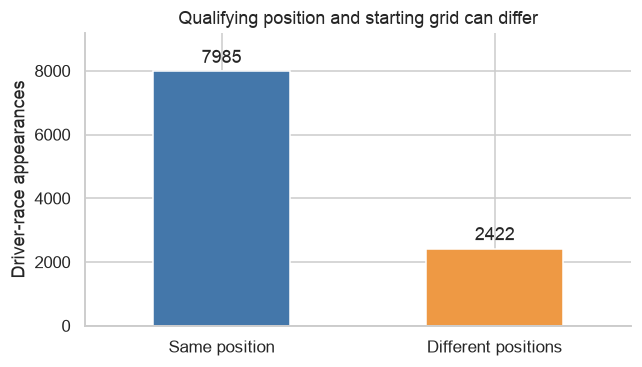

In [102]:
qual_grid = qualifying_clean[['raceId','driverId','position']].rename(columns={'position':'qualifying_position'}).merge(
    selected_results[['raceId','driverId','grid']],on=['raceId','driverId'],how='inner',validate='one_to_one')
positive_qual_grid = qual_grid.loc[qual_grid['grid'].gt(0)].copy()
qual_grid_mismatch = int(positive_qual_grid['grid'].ne(positive_qual_grid['qualifying_position']).sum())
display(positive_qual_grid.loc[positive_qual_grid['grid'].ne(positive_qual_grid['qualifying_position'])].head(8))
print(f'Qualifying/grid mismatch: {qual_grid_mismatch:,}/{len(positive_qual_grid):,} positive-grid matches')

counts = positive_qual_grid['qualifying_position'].eq(positive_qual_grid['grid']).value_counts().reindex([True, False], fill_value=0)
ax = counts.plot.bar(figsize=(6, 3.5), rot=0, color=['#4477AA', '#EE9944'])
ax.set(xticklabels=['Same position', 'Different positions'], ylabel='Driver-race appearances',
       title='Qualifying position and starting grid can differ')
ax.bar_label(ax.containers[0], fmt='%.0f', padding=3)
ax.margins(y=.15)
plt.tight_layout()
show_plot('q1_qualifying_vs_grid')

,circuitId,circuit_name,starts,podiums,rate_pct
75,79,Miami International Autodrome,6,6,100.00
71,75,Autódromo Internacional do Algarve,4,4,100.00
76,80,Las Vegas Strip Street Circuit,4,4,100.00
29,31,Donington Park,2,2,100.00
62,64,Ain Diab,2,2,100.00
63,65,Pescara Circuit,2,2,100.00
72,76,Autodromo Internazionale del Mugello,2,2,100.00
73,77,Jeddah Corniche Circuit,8,7,87.50
67,69,Circuit of the Americas,24,20,83.33
66,68,Buddh International Circuit,6,5,83.33


,circuitId,circuit_name,period,starts,podiums,rate_pct,rank_all
95,75,Autódromo Internacional do Algarve,2014–2024,4,4,100.00,1
96,76,Autodromo Internazionale del Mugello,2014–2024,2,2,100.00,1
99,79,Miami International Autodrome,2014–2024,6,6,100.00,1
100,80,Las Vegas Strip Street Circuit,2014–2024,4,4,100.00,1
10,6,Circuit de Monaco,2014–2024,19,17,89.47,5
38,22,Suzuka Circuit,2014–2024,18,16,88.89,6
58,39,Circuit Park Zandvoort,2014–2024,8,7,87.50,7
97,77,Jeddah Corniche Circuit,2014–2024,8,7,87.50,7
40,24,Yas Marina Circuit,2014–2024,22,19,86.36,9
2,2,Sepang International Circuit,2014–2024,7,6,85.71,10


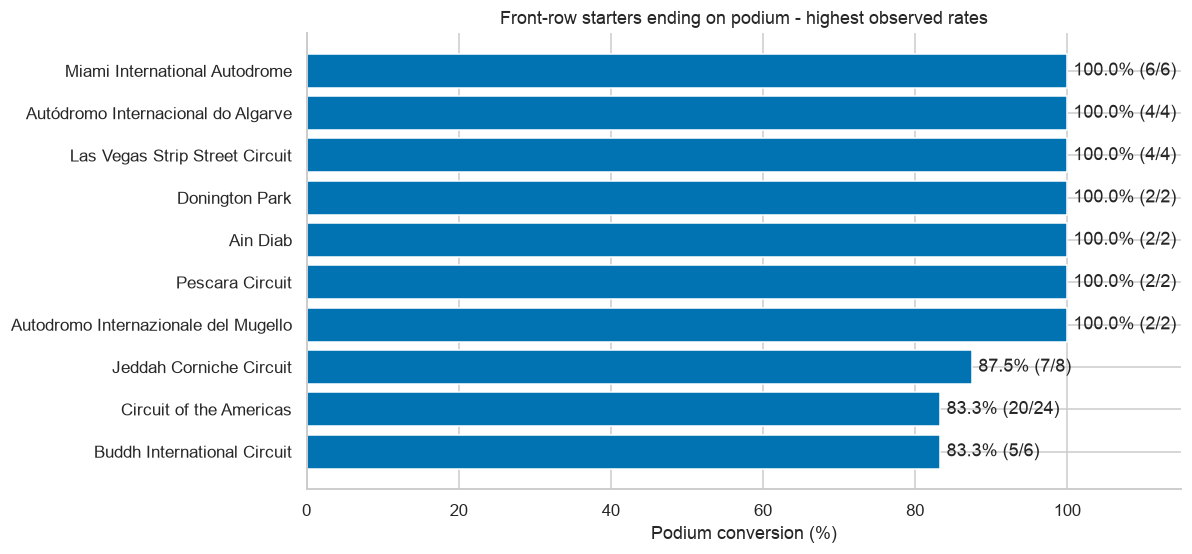

In [103]:
q1 = analysis.loc[~analysis['known_nonstart'] & analysis['grid_for_analysis'].isin([1,2])].copy()
q1['period'] = np.where(q1['year'].lt(2014),'Before 2014','2014–2024')
def conversion_table(frame, keys):
    t=frame.groupby(keys,as_index=False).agg(starts=('driverId','size'),podiums=('podium','sum'))
    t['rate_pct']=100*t['podiums']/t['starts']
    return t
q1_overall=conversion_table(q1,['circuitId','circuit_name']).sort_values(['rate_pct','starts'],ascending=[False,False])
q1_period=conversion_table(q1,['circuitId','circuit_name','period'])
q1_period['rank_all']=q1_period.groupby('period')['rate_pct'].rank(method='min',ascending=False).astype(int)
save_table(q1_overall,'q1_overall'); save_table(q1_period,'q1_period')
display(q1_overall.head(12).round(2))
display(q1_period.sort_values(['period','rank_all']).head(12).round(2))
top=q1_overall.head(10).iloc[::-1]
fig,ax=plt.subplots(figsize=(11,5.2)); bars=ax.barh(top['circuit_name'],top['rate_pct'])
ax.bar_label(bars,labels=[f'{a:.1f}% ({b}/{c})' for a,b,c in zip(top['rate_pct'],top['podiums'],top['starts'])],padding=4)
ax.set(xlim=(0,115),xlabel='Podium conversion (%)',title='Front-row starters ending on podium - highest observed rates')
plt.tight_layout(); show_plot('02_q1_overall')

In [104]:
# Show how the non-starter rule affects this question.
front_row_all = analysis.loc[analysis["grid_for_analysis"].isin([1, 2])]
q1_start_audit = pd.DataFrame({
    "Measure": ["Recorded front-row entries", "Identifiable non-starts excluded", "Estimated front-row starts"],
    "Count": [len(front_row_all), int(front_row_all["known_nonstart"].sum()), len(q1)]
})
display(q1_start_audit)
save_table(q1_start_audit, "q1_start_audit")

,Measure,Count
0,Recorded front-row entries,2243
1,Identifiable non-starts excluded,8
2,Estimated front-row starts,2235


### Ranking changes across the 2014 boundary
Compare only circuits represented in both periods. A smaller rank is better.
Starting counts show how much evidence supports each rate.

,Before 2014 rank,2014–2024 rank,Before 2014 rate (%),2014–2024 rate (%),Before 2014 starts,2014–2024 starts
circuit_name,,,,,,
Circuit de Monaco,23,1,49.17,89.47,120,19
Suzuka Circuit,3,2,70.00,88.89,50,18
Circuit Park Zandvoort,14,3,58.33,87.50,60,8
Yas Marina Circuit,10,4,60.00,86.36,10,22
Sepang International Circuit,3,5,70.00,85.71,30,7
Circuit de Barcelona-Catalunya,6,6,66.67,81.82,45,22
Circuit de Spa-Francorchamps,20,6,55.06,81.82,89,22
Circuit of the Americas,1,8,100.00,80.00,4,20
Autódromo José Carlos Pace,12,9,59.68,78.95,62,19


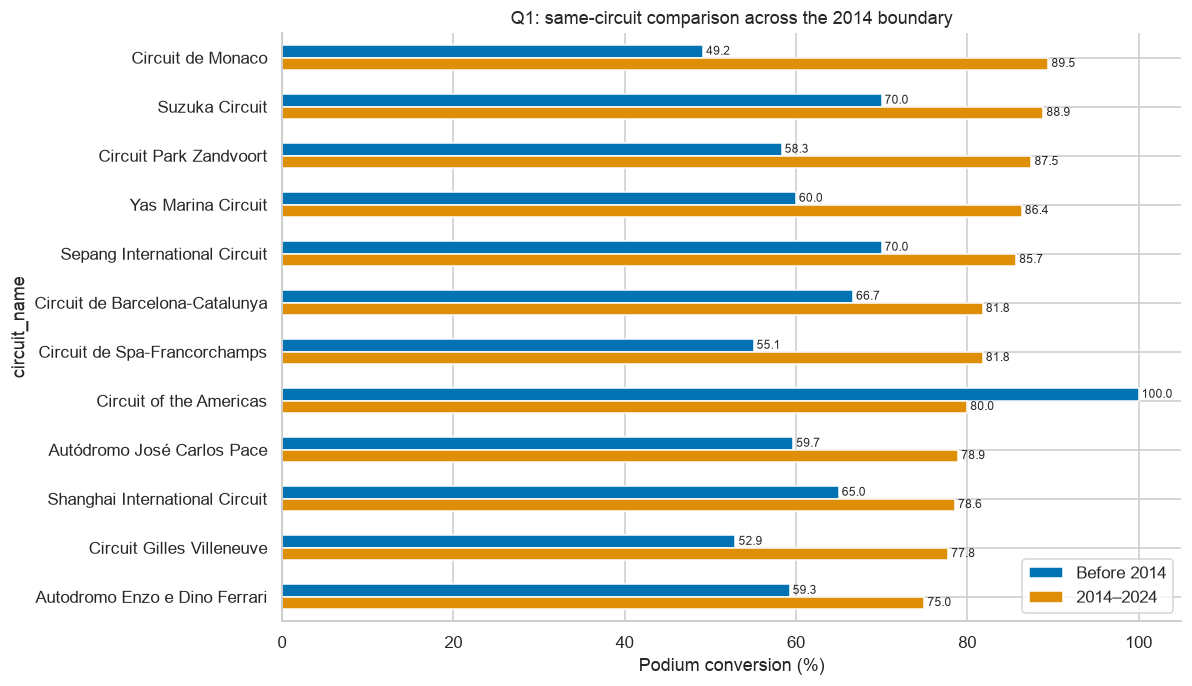

In [105]:
q1_common=q1_period.pivot(index=['circuitId','circuit_name'],columns='period',values=['rate_pct','starts']).dropna()
common_rank=q1_common['rate_pct'].rank(method='min',ascending=False).astype(int)
q1_common[('rank_common','Before 2014')]=common_rank['Before 2014']
q1_common[('rank_common','2014–2024')]=common_rank['2014–2024']
q1_common=q1_common.sort_values(('rate_pct','2014–2024'),ascending=False)
save_table(q1_common,'q1_common_circuits',index=True)

# Display the ranks that the written answer refers to.
q1_ranking_comparison = pd.DataFrame({
    "Before 2014 rank": q1_common[("rank_common", "Before 2014")],
    "2014–2024 rank": q1_common[("rank_common", "2014–2024")],
    "Before 2014 rate (%)": q1_common[("rate_pct", "Before 2014")],
    "2014–2024 rate (%)": q1_common[("rate_pct", "2014–2024")],
    "Before 2014 starts": q1_common[("starts", "Before 2014")].astype(int),
    "2014–2024 starts": q1_common[("starts", "2014–2024")].astype(int)
})
save_table(q1_ranking_comparison.reset_index(), "q1_ranking_comparison")
display(q1_ranking_comparison.droplevel("circuitId").round(2))
plot=q1_common['rate_pct'][['Before 2014','2014–2024']].head(12)
plot.index=plot.index.get_level_values('circuit_name')
ax=plot.plot.barh(figsize=(11,6.4)); ax.invert_yaxis()
ax.set(xlabel='Podium conversion (%)',xlim=(0,105),title='Q1: same-circuit comparison across the 2014 boundary')
ax.legend(loc='lower right');
for bars in ax.containers: ax.bar_label(bars, fmt='%.1f', fontsize=8, padding=2)
plt.tight_layout(); show_plot('02_q1_era_comparison')

In [106]:
entry_counts=results_clean.groupby(['raceId','driverId']).size().rename('source_entry_count')
q1_s=q1.join(entry_counts,on=['raceId','driverId'])
q1_single=conversion_table(q1_s.loc[q1_s['source_entry_count'].eq(1)],['circuitId','circuit_name','period'])
q1_sensitivity=q1_period.merge(q1_single,on=['circuitId','circuit_name','period'],how='left',suffixes=('_main','_single'))
q1_sensitivity['change_pp']=q1_sensitivity['rate_pct_single']-q1_sensitivity['rate_pct_main']
save_table(q1_sensitivity,'q1_duplicate_sensitivity')
display(q1_sensitivity.reindex(q1_sensitivity['change_pp'].abs().sort_values(ascending=False).index).head(8).round(2))
stable=q1_common[(q1_common[('starts','Before 2014')]>=10)&(q1_common[('starts','2014–2024')]>=10)]
# Use actual calculated ranks, rather than a generic statement about changes.
q1_rank_examples = "; ".join(
    f"{name} moves from rank {int(row[('rank_common', 'Before 2014')])} "
    f"to rank {int(row[('rank_common', '2014–2024')])}"
    for (_, name), row in stable.head(2).iterrows()
)
display(Markdown(
    '**Q1 answer.** Perfect overall rates occur at '
    + ', '.join(q1_overall.loc[q1_overall['rate_pct'].eq(100), 'circuit_name'])
    + '. These have small denominators. Among common circuits with at least 10 starts in each period, '
    + 'the largest recent rate is **' + stable.index[0][1]
    + f" ({stable.iloc[0][('rate_pct', '2014–2024')]:.2f}%)**. "
    + '**Yes, the ranking changes:** ' + q1_rank_examples + '. '
    + 'These ranks use the same circuits represented in both periods; the table above also shows sample sizes. '
    + 'This is an era association, not a causal effect of hybrid rules. '
    + 'Identifiable non-starts are removed; grid zero is unavailable for a grid-based comparison.'
))

,circuitId,circuit_name,period,starts_main,podiums_main,rate_pct_main,rank_all,starts_single,podiums_single,rate_pct_single,change_pp
86,66,Circuit Bremgarten,Before 2014,10,7,70.00,11,8,7,87.50,17.50
42,25,Autódromo Juan y Oscar Gálvez,Before 2014,39,20,51.28,41,37,18,48.65,-2.63
35,20,Nürburgring,Before 2014,80,45,56.25,34,78,45,57.69,1.44
33,19,Indianapolis Motor Speedway,Before 2014,37,19,51.35,40,36,19,52.78,1.43
66,46,Watkins Glen,Before 2014,41,21,51.22,42,40,21,52.50,1.28
11,6,Circuit de Monaco,Before 2014,120,59,49.17,55,119,59,49.58,0.41
25,14,Autodromo Nazionale di Monza,Before 2014,124,60,48.39,56,123,60,48.78,0.39
0,1,Albert Park Grand Prix Circuit,2014–2024,18,13,72.22,23,18,13,72.22,0.00


**Q1 answer.** Perfect overall rates occur at Miami International Autodrome, Autódromo Internacional do Algarve, Las Vegas Strip Street Circuit, Donington Park, Ain Diab, Pescara Circuit, Autodromo Internazionale del Mugello. These have small denominators. Among common circuits with at least 10 starts in each period, the largest recent rate is **Circuit de Monaco (89.47%)**. **Yes, the ranking changes:** Circuit de Monaco moves from rank 23 to rank 1; Suzuka Circuit moves from rank 3 to rank 2. These ranks use the same circuits represented in both periods; the table above also shows sample sizes. This is an era association, not a causal effect of hybrid rules. Identifiable non-starts are removed; grid zero is unavailable for a grid-based comparison.

## Question 2 - Home-country advantage
Keep our nationality/country mapping and compare Home and Away at the same grid.
Apply identical pooled grid weights to both groups. This adjusts starting position, not driver,
team or season. Resample whole races to describe uncertainty because entries within a race are related.

In [107]:
nationality_mapping = {
    "American": "United States",
    "Argentine": "Argentina",
    "Argentinian": "Argentina",
    "Australian": "Australia",
    "Austrian": "Austria",
    "Belgian": "Belgium",
    "Brazilian": "Brazil",
    "British": "United Kingdom",
    "Canadian": "Canada",
    "Chilean": "Chile",
    "Chinese": "China",
    "Colombian": "Colombia",
    "Czech": "Czech Republic",
    "Danish": "Denmark",
    "Dutch": "Netherlands",
    "Finnish": "Finland",
    "French": "France",
    "German": "Germany",
    "Hungarian": "Hungary",
    "Indian": "India",
    "Indonesian": "Indonesia",
    "Irish": "Ireland",
    "Italian": "Italy",
    "Japanese": "Japan",
    "Liechtensteiner": "Liechtenstein",
    "Malaysian": "Malaysia",
    "Mexican": "Mexico",
    "Monegasque": "Monaco",
    "New Zealander": "New Zealand",
    "Polish": "Poland",
    "Portuguese": "Portugal",
    "Russian": "Russia",
    "South African": "South Africa",
    "Spanish": "Spain",
    "Swedish": "Sweden",
    "Swiss": "Switzerland",
    "Thai": "Thailand",
    "Uruguayan": "Uruguay",
    "Venezuelan": "Venezuela"
}

home_country_mapping={nationality:[country] for nationality,country in nationality_mapping.items()}
home_country_mapping.update({'American-Italian':['United States','Italy'],
    'Argentine-Italian':['Argentina','Italy'],'East German':['Germany'],'Rhodesian':['Zimbabwe']})
country_mapping={'USA':'United States','UK':'United Kingdom','UAE':'United Arab Emirates'}
driver_home=drivers_clean[['driverId','nationality']].copy()
driver_home['home_countries']=driver_home['nationality'].str.strip().map(home_country_mapping)
assert driver_home['home_countries'].notna().all(), 'Extend the explicit mapping for any new nationality.'

,Grid-adjusted podium rate (%)
location,
Home,13.423
Away,13.671


location,Home,Away
grid_for_analysis,,
1,91,1028
2,87,1029
3,85,1037
4,85,1041
5,81,1037
6,94,1025
7,90,1035
8,89,1026
9,108,1022


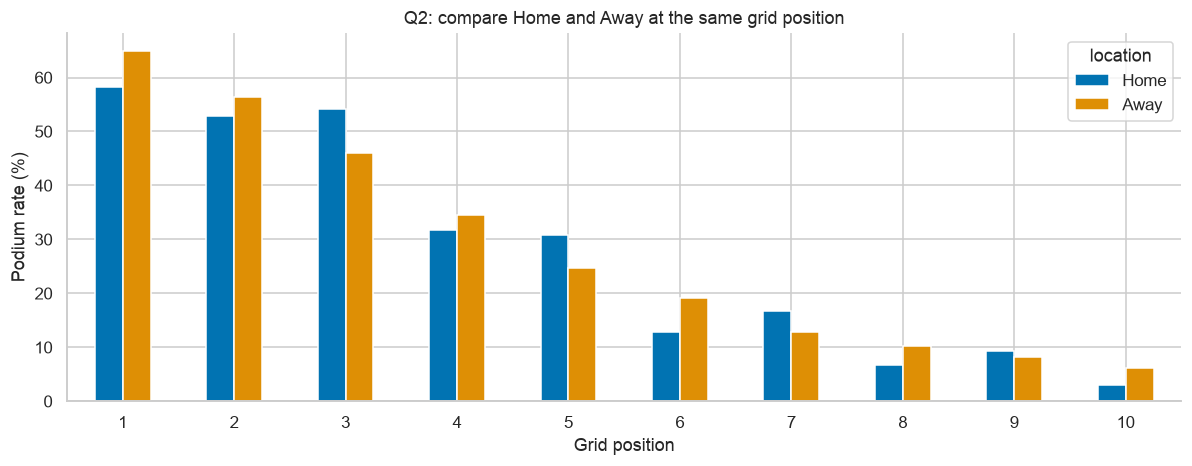

In [108]:
q2=analysis.merge(driver_home[['driverId','home_countries']],on='driverId',how='left',validate='many_to_one')
q2['standard_country']=q2['country'].str.strip().replace(country_mapping)
q2=q2.loc[~q2['known_nonstart'] & q2['grid_for_analysis'].notna()].copy()
q2['location']=['Home' if c in hs else 'Away' for c,hs in zip(q2['standard_country'],q2['home_countries'])]
q2_strata=q2.groupby(['grid_for_analysis','location'],as_index=False).agg(n=('driverId','size'),podiums=('podium','sum'))
q2_strata['rate_pct']=100*q2_strata['podiums']/q2_strata['n']
q2_counts=q2_strata.pivot(index='grid_for_analysis',columns='location',values='n').reindex(columns=['Home','Away'])
q2_rates=q2_strata.pivot(index='grid_for_analysis',columns='location',values='rate_pct').reindex(columns=['Home','Away'])
common=q2_rates.dropna().index
weights=q2_counts.loc[common].sum(axis=1); weights=weights/weights.sum()
q2_adjusted=q2_rates.loc[common].mul(weights,axis=0).sum()
q2_difference=float(q2_adjusted['Home']-q2_adjusted['Away'])
q2_n=int(q2_counts.loc[common].sum().sum())
save_table(q2_strata,'q2_grid_strata')
save_table(q2_adjusted.rename('grid_adjusted_rate_pct').reset_index(),'q2_adjusted')
display(q2_adjusted.round(3).to_frame('Grid-adjusted podium rate (%)'))
display(q2_counts.loc[common].astype(int).head(10))
ax=q2_rates.loc[common].head(10).plot.bar(figsize=(11,4.4),rot=0)
ax.set(title='Q2: compare Home and Away at the same grid position',xlabel='Grid position',ylabel='Podium rate (%)')
plt.tight_layout(); show_plot('02_q2_grid_control')

In [109]:
# Cluster bootstrap: resample whole races, recompute stratum rates, hold the original weights fixed.
common_grids=list(common)
boot_q2=q2.loc[q2['grid_for_analysis'].isin(common_grids)]
race_ids=boot_q2['raceId'].unique(); race_index={v:i for i,v in enumerate(race_ids)}
grid_index={v:i for i,v in enumerate(common_grids)}
counts=np.zeros((len(race_ids),len(common_grids),2)); podium_counts=np.zeros_like(counts)
for row in boot_q2.itertuples():
    i=race_index[row.raceId]; j=grid_index[row.grid_for_analysis]; k=int(row.location=='Away')
    counts[i,j,k]+=1; podium_counts[i,j,k]+=row.podium
rng=np.random.default_rng(SEED); bootstrap_diffs=[]
for _ in range(300):
    sampled=rng.integers(0,len(race_ids),size=len(race_ids))
    n=counts[sampled].sum(axis=0); y=podium_counts[sampled].sum(axis=0)
    valid=(n[:,0]>0)&(n[:,1]>0)
    w=weights.to_numpy()[valid]; w=w/w.sum()
    rates=y[valid]/n[valid]
    bootstrap_diffs.append(float(100*np.sum(w*(rates[:,0]-rates[:,1]))))
q2_ci=np.percentile(bootstrap_diffs,[2.5,97.5]).tolist()

,analysis,Home_pct,Away_pct,difference_pp,appearances
0,Main,13.423,13.671,-0.249,24871
1,Without Indianapolis 500 (1950–1960),13.601,13.728,-0.127,24501
2,Only single-entry pairs,13.274,13.636,-0.362,24790


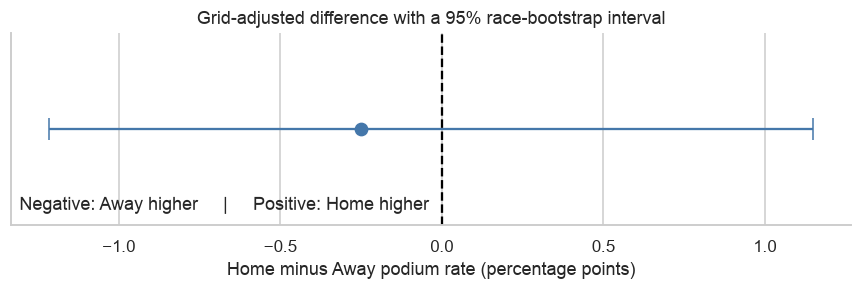

**Q2 answer.** Across **24,871** common-support appearances, adjusted Home = **13.42%**, Away = **13.67%**; difference = **-0.25 percentage points**. The descriptive race-bootstrap 95% interval is **[-1.21, +1.15] pp**. A small difference is not evidence of a causal home effect. Country mappings, team/driver composition, era, and starting-grid exclusions remain limitations.

In [110]:
# Indianapolis 500 and repeated-pair sensitivity: both can distort historical home-country comparisons.
def adjusted_home_difference(frame):
    t=frame.groupby(['grid_for_analysis','location']).agg(n=('podium','size'),p=('podium','sum'))
    n=t['n'].unstack().reindex(columns=['Home','Away']); r=(100*t['p']/t['n']).unstack().reindex(columns=['Home','Away'])
    eligible=r.dropna().index; w=n.loc[eligible].sum(axis=1); w=w/w.sum()
    rates=r.loc[eligible].mul(w,axis=0).sum()
    return {'Home_pct':rates['Home'],'Away_pct':rates['Away'],'difference_pp':rates['Home']-rates['Away'],
            'appearances':int(n.loc[eligible].sum().sum())}
q2_check=q2.join(entry_counts,on=['raceId','driverId'])
q2_sensitivity=pd.DataFrame([
    {'analysis':'Main',**adjusted_home_difference(q2)},
    {'analysis':'Without Indianapolis 500 (1950–1960)',**adjusted_home_difference(q2.loc[~(q2['circuitId'].eq(19)&q2['year'].between(1950,1960))])},
    {'analysis':'Only single-entry pairs',**adjusted_home_difference(q2_check.loc[q2_check['source_entry_count'].eq(1)])}])
save_table(q2_sensitivity,'q2_sensitivity'); display(q2_sensitivity.round(3))

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.errorbar(q2_difference, 0,
            xerr=[[q2_difference-q2_ci[0]], [q2_ci[1]-q2_difference]],
            fmt='o', color='#4477AA', capsize=7, markersize=8)
ax.axvline(0, color='black', linestyle='--')
ax.set(yticks=[], xlabel='Home minus Away podium rate (percentage points)',
       title='Grid-adjusted difference with a 95% race-bootstrap interval')
ax.text(.01, .08, 'Negative: Away higher     |     Positive: Home higher',
        transform=ax.transAxes)
plt.tight_layout()
show_plot('q2_adjusted_difference_uncertainty')
display(Markdown(f'**Q2 answer.** Across **{q2_n:,}** common-support appearances, adjusted Home = **{q2_adjusted["Home"]:.2f}%**, '
    f'Away = **{q2_adjusted["Away"]:.2f}%**; difference = **{q2_difference:+.2f} percentage points**. '
    f'The descriptive race-bootstrap 95% interval is **[{q2_ci[0]:+.2f}, {q2_ci[1]:+.2f}] pp**. '
    'A small difference is not evidence of a causal home effect. Country mappings, team/driver composition, era, and starting-grid exclusions remain limitations.'))

## Question 3 - Constructor mechanical retirements
Keep an explicit list of identified mechanical labels. Exclude crash/driver/regulation outcomes
from the numerator and identifiable non-starts from estimated starts. Unclear causes remain
separate. Additional classification policies show how uncertain labels can change the rankings;
they are assumptions, not externally verified causes. Constructor IDs remain distinct across renames.

In [111]:
mechanical_statuses = ['Engine','Gearbox','Transmission','Clutch','Hydraulics','Electrical','Radiator',
 'Brakes','Differential','Overheating','Mechanical','Driveshaft','Fuel pressure','Water pressure',
 'Throttle','Steering','Electronics','Exhaust','Oil leak','Water leak','Fuel pump','Oil pressure',
 'Fuel system','Power loss','Drivetrain','Battery','Fuel leak','Turbo','Water pump','Spark plugs',
 'Power Unit','ERS','Cooling system','Pneumatics','Ignition','Alternator','Oil pump','Injection',
 'Distributor','Fuel pipe','Oil pipe','Water pipe','Magneto','Supercharger','Crankshaft','Halfshaft',
 'CV joint','Engine fire','Engine misfire','Heat shield fire','Oil line']
ambiguous_components=['Suspension','Wheel','Wheel nut','Brake duct','Seat','Driver Seat','Technical',
 'Tyre','Front wing','Rear wing','Broken wing','Undertray','Vibrations','Wheel rim','Wheel bearing',
 'Track rod','Chassis','Axle','Fuel','Fire','Handling']
non_mechanical=['Accident','Collision','Collision damage','Spun off','Disqualified','Excluded',
 'Out of fuel','Illness','Debris','Injured','Injury','Driver unwell','Fatal accident','Eye injury',
 'Physical','Underweight','Safety concerns','Safety','107% Rule','Did not qualify','Did not prequalify']
status_policy=status_clean.copy()
status_policy['category']='Ambiguous or unspecified'
status_policy.loc[status_policy['status'].isin(ambiguous_components),'category']='Ambiguous component'
status_policy.loc[status_policy['status'].isin(non_mechanical),'category']='Crash/driver/regulation/other exclusion'
status_policy.loc[status_policy['status'].isin(mechanical_statuses),'category']='Identified mechanical'
status_policy.loc[status_policy['status'].eq('Finished')|status_policy['status'].str.match(r'^\+\d+ Laps?$'),'category']='Finished/lapped'
save_table(status_policy,'status_policy_all_labels')

display(status_policy.groupby('category').size().rename('Status labels').to_frame())

,Status labels
category,
Ambiguous component,21
Ambiguous or unspecified,12
Crash/driver/regulation/other exclusion,21
Finished/lapped,34
Identified mechanical,51


In [112]:
q3=analysis.loc[analysis['year'].between(2014,2024)&~analysis['known_nonstart']].copy()
q3['period']=np.where(q3['year'].le(2021),'2014–2021','2022–2024')
q3=q3.merge(status_policy[['statusId','category']],on='statusId',validate='many_to_one')
q3['strict_mechanical']=q3['category'].eq('Identified mechanical')
q3['suspension_policy']=q3['strict_mechanical']|q3['status'].eq('Suspension')
q3['expanded_policy']=q3['strict_mechanical']|q3['category'].eq('Ambiguous component')
q3['uncertain']=q3['category'].isin(['Ambiguous component','Ambiguous or unspecified'])
q3_rates=q3.groupby(['constructorId','constructor_name','period'],as_index=False).agg(
    starts=('resultId','size'),mechanical=('strict_mechanical','sum'),uncertain=('uncertain','sum'),
    suspension_policy=('suspension_policy','sum'),expanded_policy=('expanded_policy','sum'))
for numerator,label in [('mechanical','rate_pct'),('suspension_policy','suspension_rate_pct'),('expanded_policy','expanded_rate_pct')]:
    q3_rates[label]=100*q3_rates[numerator]/q3_rates['starts']
q3_rates['rank']=q3_rates.groupby('period')['rate_pct'].rank(method='min',ascending=False).astype(int)
q3_rates['uncertainty_upper_pct']=100*(q3_rates['mechanical']+q3_rates['uncertain'])/q3_rates['starts']
save_table(q3_rates,'q3_constructor_rates')
q3_unresolved=q3.loc[q3['uncertain']].groupby(['period','status','category'],as_index=False).size()
save_table(q3_unresolved,'q3_ambiguous_causes')
display(q3_rates.sort_values(['period','rank']).round(2))
display(q3_unresolved)

,constructorId,constructor_name,period,starts,mechanical,uncertain,suspension_policy,expanded_policy,rate_pct,suspension_rate_pct,expanded_rate_pct,rank,uncertainty_upper_pct
21,208,Lotus F1,2014–2021,75,13,5,13,15,17.33,17.33,20.00,1,24.00
20,207,Caterham,2014–2021,33,5,5,7,7,15.15,21.21,21.21,2,30.30
5,5,Toro Rosso,2014–2021,242,35,9,39,39,14.46,16.12,16.12,3,18.18
4,4,Renault,2014–2021,199,24,7,26,28,12.06,13.07,14.07,4,15.58
0,1,McLaren,2014–2021,316,38,11,40,43,12.03,12.66,13.61,5,15.51
11,15,Sauber,2014–2021,199,20,6,21,22,10.05,10.55,11.06,6,13.07
8,9,Red Bull,2014–2021,318,31,6,33,34,9.75,10.38,10.69,7,11.64
23,210,Haas F1 Team,2014–2021,241,17,13,18,23,7.05,7.47,9.54,8,12.45
28,214,Alpine F1 Team,2014–2021,44,3,1,3,4,6.82,6.82,9.09,9,9.09
25,211,Racing Point,2014–2021,75,5,2,6,6,6.67,8.00,8.00,10,9.33


,period,status,category,size
0,2014–2021,Brake duct,Ambiguous component,1
1,2014–2021,Damage,Ambiguous or unspecified,2
2,2014–2021,Front wing,Ambiguous component,2
3,2014–2021,Puncture,Ambiguous or unspecified,7
4,2014–2021,Rear wing,Ambiguous component,2
5,2014–2021,Retired,Ambiguous or unspecified,37
6,2014–2021,Seat,Ambiguous component,1
7,2014–2021,Suspension,Ambiguous component,24
8,2014–2021,Technical,Ambiguous component,1
9,2014–2021,Tyre,Ambiguous component,4


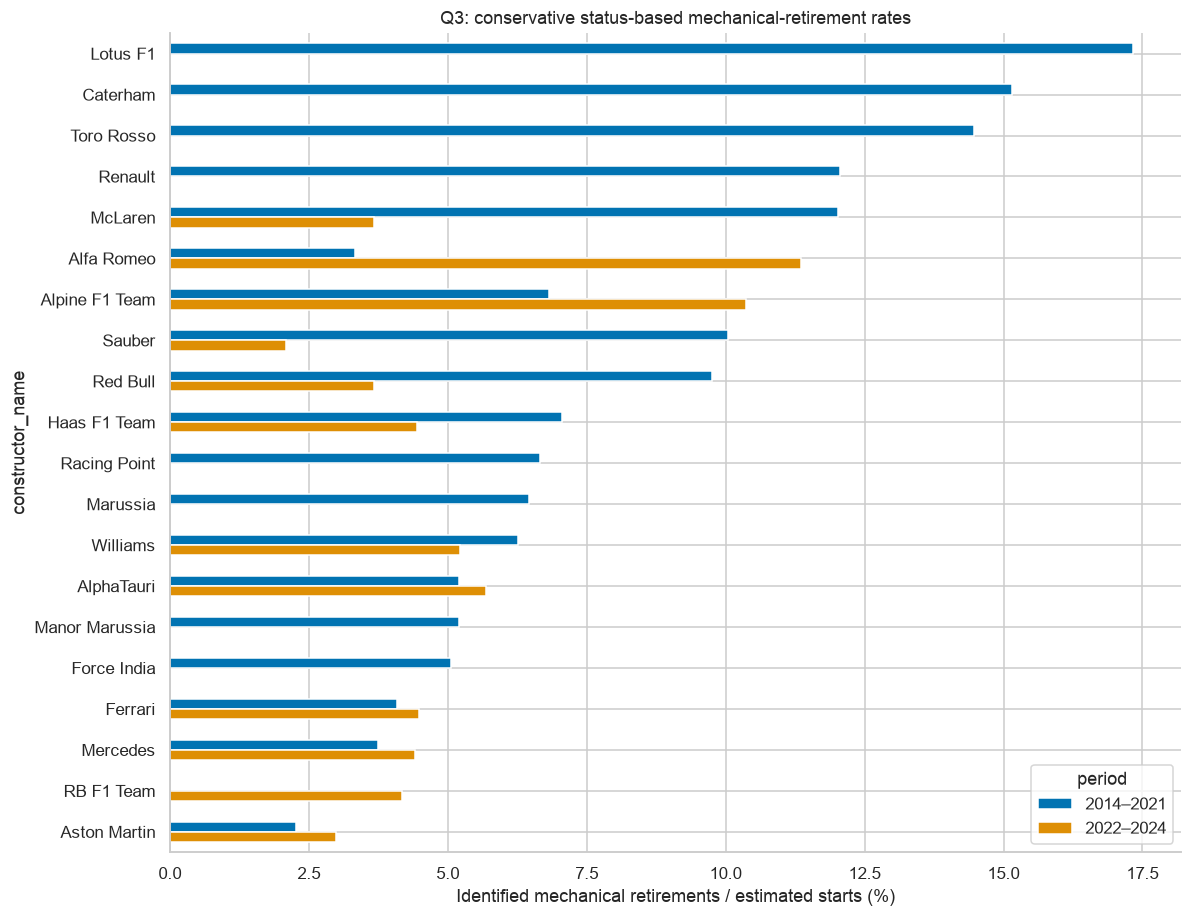

In [113]:
plot=q3_rates.pivot(index='constructor_name',columns='period',values='rate_pct')
plot=plot.loc[plot.max(axis=1).sort_values(ascending=False).index]
ax=plot.plot.barh(figsize=(11,8.5)); ax.invert_yaxis()
ax.set(xlabel='Identified mechanical retirements / estimated starts (%)',title='Q3: conservative status-based mechanical-retirement rates')
plt.tight_layout(); show_plot('02_q3_constructor_rates')

,period,policy,highest_constructor,rate_pct
0,2014–2021,Conservative,Lotus F1,17.33
1,2014–2021,Add Suspension,Caterham,21.21
2,2014–2021,Expanded component labels,Caterham,21.21
3,2022–2024,Conservative,Alfa Romeo,11.36
4,2022–2024,Add Suspension,Alfa Romeo,11.36
5,2022–2024,Expanded component labels,Alfa Romeo,12.50


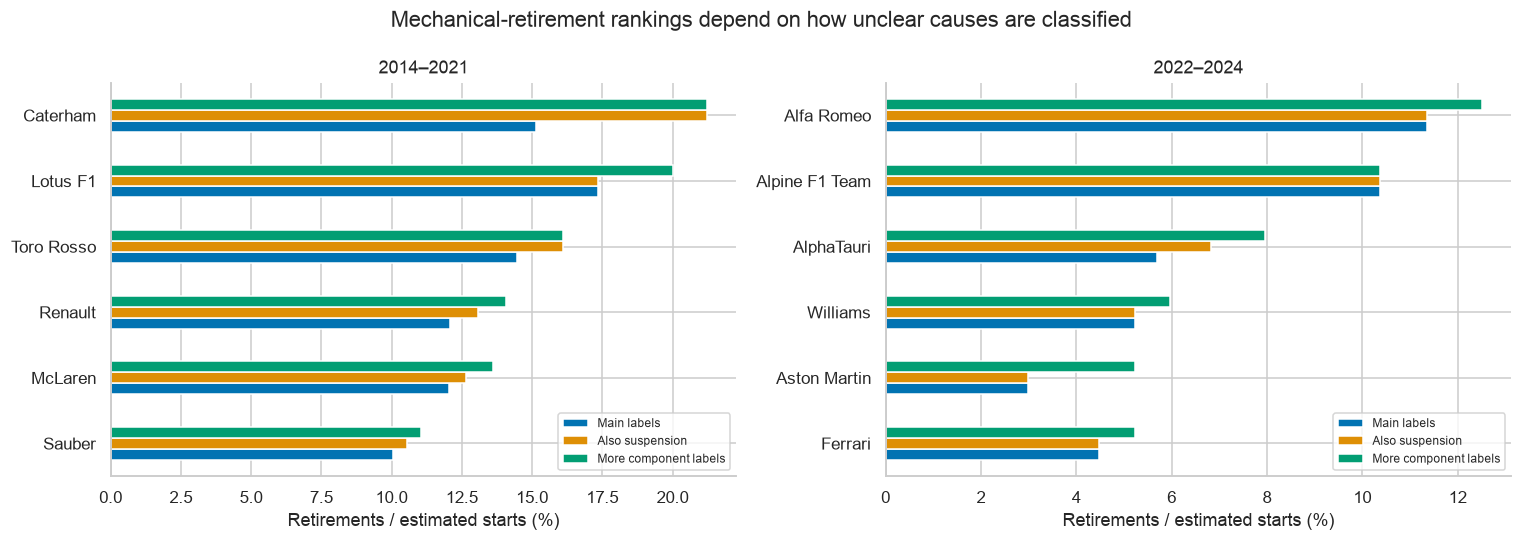

**Q3 answer under the conservative policy.** 2014–2021: **Lotus F1**, 13/75 = **17.33%**; 2022–2024: **Alfa Romeo**, 10/88 = **11.36%**. The sensitivity table is part of the answer: ambiguous suspension/component labels can change the winner. These are identified-status estimates, not proven underlying component-failure rates. A nonzero-lap withdrawal is an ambiguous cause, not a non-start.

In [114]:
q3_policy_rows=[]
for era,g in q3_rates.groupby('period'):
    for policy,col in [('Conservative','rate_pct'),('Add Suspension','suspension_rate_pct'),('Expanded component labels','expanded_rate_pct')]:
        winner=g.sort_values([col,'starts'],ascending=[False,False]).iloc[0]
        q3_policy_rows.append({'period':era,'policy':policy,'highest_constructor':winner['constructor_name'],'rate_pct':winner[col]})
q3_policy_comparison=pd.DataFrame(q3_policy_rows)
save_table(q3_policy_comparison,'q3_policy_sensitivity'); display(q3_policy_comparison.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, era in zip(axes, ['2014–2021', '2022–2024']):
    t = q3_rates.loc[q3_rates['period'].eq(era)].sort_values('expanded_rate_pct').tail(6)
    t.set_index('constructor_name')[['rate_pct', 'suspension_rate_pct', 'expanded_rate_pct']].plot.barh(ax=ax)
    ax.set(title=era, xlabel='Retirements / estimated starts (%)', ylabel='')
    ax.legend(['Main labels', 'Also suspension', 'More component labels'], fontsize=8)
plt.suptitle('Mechanical-retirement rankings depend on how unclear causes are classified')
plt.tight_layout()
show_plot('q3_classification_sensitivity')
answers=[]
for era,g in q3_rates.groupby('period'):
    winner=g.sort_values(['rate_pct','starts'],ascending=[False,False]).iloc[0]
    answers.append(f'{era}: **{winner["constructor_name"]}**, {int(winner["mechanical"])}/{int(winner["starts"])} = **{winner["rate_pct"]:.2f}%**')
display(Markdown('**Q3 answer under the conservative policy.** '+'; '.join(answers)+
    '. The sensitivity table is part of the answer: ambiguous suspension/component labels can change the winner. '
    'These are identified-status estimates, not proven underlying component-failure rates. A nonzero-lap withdrawal is an ambiguous cause, not a non-start.'))

# Stage 3 - Feature Selection and Engineering
Keep the original feature choices as the baseline. Investigate constructor form and relative Q1
pace as candidates, not guaranteed improvements. All historical inputs use completed earlier races.

In [115]:
# Add the year to each driver–race appearance
coverage_data = driver_race_outcomes.merge(
    races_clean[["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Add qualifying information
coverage_data = coverage_data.merge(
    qualifying_clean[
        ["raceId", "driverId", "position", "q1_seconds"]
    ].rename(columns={"position": "qualifying_position"}),
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

# Identify which information is available
coverage_data["has_grid"] = (
    coverage_data["grid_for_analysis"].gt(0).fillna(False)
)

coverage_data["has_qualifying"] = (
    coverage_data["qualifying_position"].notna()
)

coverage_data["has_q1"] = coverage_data["q1_seconds"].notna()

In [116]:
# Count races and appearances, then calculate availability
yearly_coverage = coverage_data.groupby("year").agg(
    races=("raceId", "nunique"),
    driver_entries=("driverId", "size"),
    grid_coverage=("has_grid", "mean"),
    qualifying_coverage=("has_qualifying", "mean"),
    q1_coverage=("has_q1", "mean")
)

# Convert availability from proportions into percentages
coverage_columns = [
    "grid_coverage",
    "qualifying_coverage",
    "q1_coverage"
]

yearly_coverage[coverage_columns] = (
    yearly_coverage[coverage_columns] * 100
)

# Show every year
with pd.option_context("display.max_rows", None):
    display(yearly_coverage.round(2))

,races,driver_entries,grid_coverage,qualifying_coverage,q1_coverage
year,,,,,
1950,7,156,100.0,0.00,0.00
1951,8,175,100.0,0.00,0.00
1952,8,212,94.34,0.00,0.00
1953,9,230,100.0,0.00,0.00
1954,9,213,98.59,0.00,0.00
1955,7,162,95.68,0.00,0.00
1956,8,178,95.51,0.00,0.00
1957,8,163,96.93,0.00,0.00
1958,11,238,93.28,0.00,0.00


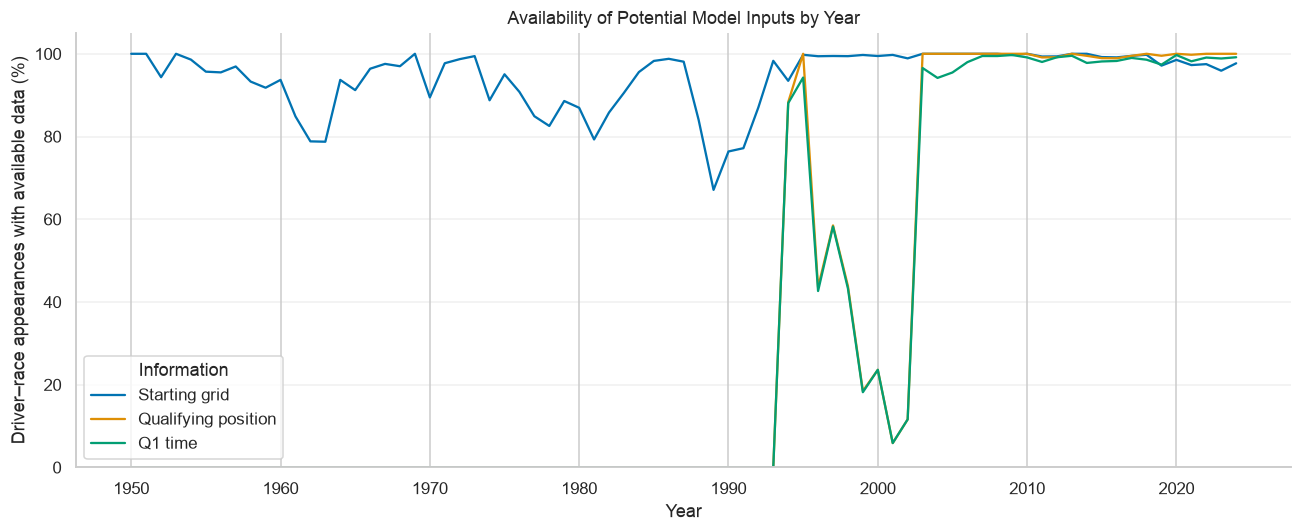

In [117]:
# Use readable labels for the chart
chart_data = yearly_coverage[coverage_columns].rename(
    columns={
        "grid_coverage": "Starting grid",
        "qualifying_coverage": "Qualifying position",
        "q1_coverage": "Q1 time"
    }
)

chart_data.plot(figsize=(12, 5))

plt.title("Availability of Potential Model Inputs by Year")
plt.xlabel("Year")
plt.ylabel("Driver–race appearances with available data (%)")
plt.ylim(0, 105)
plt.legend(title="Information")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
show_plot("features_173")

## Modeling window and split
Keep 2003-2024, with training through 2018, validation in 2019-2021, and test in 2022-2024.

In [118]:
# Add race information to the unique driver–race outcomes
model_base = driver_race_outcomes.merge(
    races_clean[
        ["raceId", "year", "round", "date", "circuitId"]
    ],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Keep the selected modeling years
model_base = model_base[
    model_base["year"].between(2003, 2024)
].copy()

# Confirm that each appearance has a recorded outcome
assert model_base["positionOrder"].notna().all()

# Create the answer that the models will learn to predict
model_base["podium"] = (
    model_base["positionOrder"].between(1, 3)
).astype(int)

# Put appearances in chronological order
model_base = model_base.sort_values(
    ["date", "raceId", "driverId"]
).reset_index(drop=True)

model_base.head()

,resultId,raceId,driverId,constructorId,positionOrder,grid_for_analysis,year,round,date,circuitId,podium
0,1889,108,2,15,15,7,2003,1,2003-03-09,1,0
1,1881,108,4,4,7,10,2003,1,2003-03-09,1,0
2,1877,108,8,1,3,15,2003,1,2003-03-09,1,1
3,1875,108,14,1,1,11,2003,1,2003-03-09,1,1
4,1879,108,15,4,5,12,2003,1,2003-03-09,1,0


In [119]:
# Assign earlier years to training
model_base["split"] = "Training"

# Use the next period for validation
model_base.loc[
    model_base["year"].between(2019, 2021),
    "split"
] = "Validation"

# Reserve the latest period for final testing
model_base.loc[
    model_base["year"].between(2022, 2024),
    "split"
] = "Test"

# Show the size and years of each dataset
split_summary = model_base.groupby("split").agg(
    first_year=("year", "min"),
    last_year=("year", "max"),
    races=("raceId", "nunique"),
    driver_appearances=("driverId", "size")
)

display(
    split_summary.reindex(["Training", "Validation", "Test"])
)

,first_year,last_year,races,driver_appearances
split,,,,
Training,2003,2018,300,6411
Validation,2019,2021,60,1200
Test,2022,2024,68,1359


In [120]:
# Each driver must appear once per race
assert not model_base.duplicated(["raceId", "driverId"]).any()

# All drivers in a race must belong to the same split
assert model_base.groupby("raceId")["split"].nunique().eq(1).all()

# Check that the periods follow chronological order
training_dates = model_base.loc[
    model_base["split"] == "Training", "date"
]

validation_dates = model_base.loc[
    model_base["split"] == "Validation", "date"
]

test_dates = model_base.loc[
    model_base["split"] == "Test", "date"
]

assert training_dates.max() < validation_dates.min()
assert validation_dates.max() < test_dates.min()

print("Passed: unique driver–race rows and separate chronological periods.")

Passed: unique driver–race rows and separate chronological periods.


### Dataset Split

We use a chronological split: 2003–2018 for training,
2019–2021 for validation, and 2022–2024 for testing.

This reflects the task of predicting future races from past information.
All driver entries from the same race remain in the same split.

Training data is used to learn preprocessing and model parameters.
Validation data supports model selection and tuning.
The test set is reserved for final evaluation.

Historical features use only information available before each race.
Changes across seasons are a limitation considered when interpreting
validation and test performance.

In [121]:
# Select qualifying positions and give the column a clear name
qualifying_positions = qualifying_clean[
    ["raceId", "driverId", "position"]
].rename(columns={"position": "qualifying_position"})

# Add qualifying position to a separate modeling table
model_features = model_base.merge(
    qualifying_positions,
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

# Positions are whole numbers, but missing values are allowed
model_features["qualifying_position"] = (
    model_features["qualifying_position"].astype("Int64")
)

# Check that the join did not add or remove appearances
assert len(model_features) == len(model_base)

model_features[
    ["raceId", "driverId", "grid_for_analysis",
     "qualifying_position", "podium", "split"]
].head()

,raceId,driverId,grid_for_analysis,qualifying_position,podium,split
0,108,2,7,7,0,Training
1,108,4,10,10,0,Training
2,108,8,15,15,1,Training
3,108,14,11,11,1,Training
4,108,15,12,12,0,Training


In [122]:
# Use training appearances for feature investigation
training_data = model_features[
    model_features["split"] == "Training"
].copy()

candidate_features = [
    "grid_for_analysis",
    "qualifying_position"
]

feature_missing = pd.DataFrame({
    "Missing count": training_data[candidate_features].isna().sum(),
    "Missing percentage": (
        training_data[candidate_features].isna().mean() * 100
    ).round(2)
})

display(feature_missing)

,Missing count,Missing percentage
grid_for_analysis,17,0.27
qualifying_position,21,0.33


Starting grid


,appearances,podium_rate
grid_for_analysis,,
1,300,79.33
2,299,62.21
3,300,50.00
4,300,31.33
5,300,21.67
6,300,16.00
7,300,10.33
8,300,5.33
9,300,4.33


Qualifying position


,appearances,podium_rate
qualifying_position,,
1,300,78.00
2,300,62.33
3,300,49.00
4,300,31.67
5,300,25.33
6,300,16.67
7,300,9.67
8,300,4.67
9,300,4.33


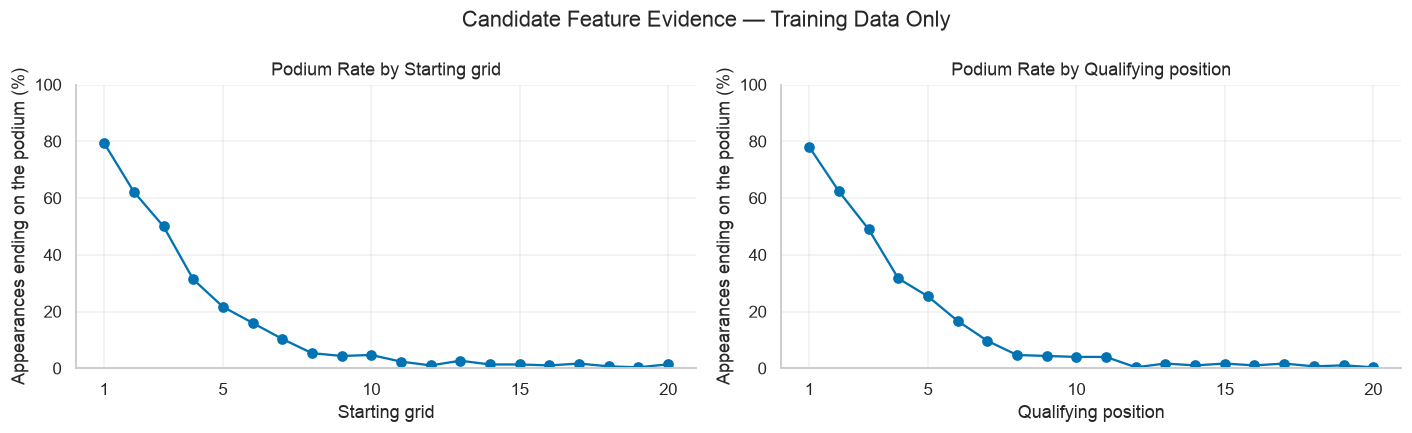

In [123]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, feature, label in zip(
    axes,
    candidate_features,
    ["Starting grid", "Qualifying position"]
):
    # Show positions 1–20 to keep the charts readable
    selected = training_data[
        training_data[feature].between(1, 20)
    ]

    # Calculate podium percentage and supporting appearance count
    position_summary = selected.groupby(feature).agg(
        appearances=("podium", "size"),
        podium_rate=("podium", "mean")
    )

    position_summary["podium_rate"] *= 100

    ax.plot(
        position_summary.index,
        position_summary["podium_rate"],
        marker="o"
    )

    ax.set_title(f"Podium Rate by {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Appearances ending on the podium (%)")
    ax.set_ylim(0, 100)
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.grid(alpha=0.3)

    print(label)
    display(position_summary.round(2))

plt.suptitle("Candidate Feature Evidence — Training Data Only")
plt.tight_layout()
show_plot("features_181")

## Driver and constructor history
        Driver form uses the previous five appearances. Constructor form first combines its cars
        within a race, then uses its previous five races. This excludes current teammate outcomes.
        Form can cross seasons; championship standings reset each season.

In [124]:
def historical_form(entries):
    history = entries[["raceId", "driverId", "constructorId", "positionOrder"]].merge(
        races_clean[["raceId", "date"]], on="raceId", validate="many_to_one")
    history["podium"] = history["positionOrder"].le(3).astype(int)
    history = history.sort_values(["driverId", "date", "raceId"])
    drivers_group = history.groupby("driverId", sort=False)
    history["recent_podium_rate"] = drivers_group["podium"].transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).mean()) * 100
    history["recent_avg_finish"] = drivers_group["positionOrder"].transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    history["past_races_used"] = drivers_group.cumcount().clip(upper=5)
    history["previous_race_date"] = drivers_group["date"].shift(1)

    # One constructor-race row BEFORE shifting, so current teammate results cannot enter history.
    teams = history.groupby(["constructorId", "raceId", "date"], as_index=False).agg(
        podium_rate=("podium", "mean"), average_finish=("positionOrder", "mean"))
    teams = teams.sort_values(["constructorId", "date", "raceId"])
    team_group = teams.groupby("constructorId", sort=False)
    teams["constructor_recent_podium_rate"] = team_group["podium_rate"].transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).mean()) * 100
    teams["constructor_recent_avg_finish"] = team_group["average_finish"].transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    teams["constructor_past_races_used"] = team_group.cumcount().clip(upper=5)
    teams["constructor_history_date"] = team_group["date"].shift(1)
    team_columns = ["constructor_recent_podium_rate", "constructor_recent_avg_finish",
                    "constructor_past_races_used", "constructor_history_date"]
    return history.merge(
        teams[["constructorId", "raceId"] + team_columns],
        on=["constructorId", "raceId"], validate="many_to_one")

driver_history = historical_form(selected_results)

In [125]:
form_features = ["recent_podium_rate", "recent_avg_finish", "past_races_used"]
constructor_form_features = ["constructor_recent_podium_rate", "constructor_recent_avg_finish",
                             "constructor_past_races_used"]
history_columns = form_features + constructor_form_features + [
    "previous_race_date", "constructor_history_date"]
model_features = model_features.merge(
    driver_history[["raceId", "driverId"] + history_columns],
    on=["raceId", "driverId"], how="left", validate="one_to_one")
for date_column in ["previous_race_date", "constructor_history_date"]:
    assert (model_features[date_column].isna()
            | model_features[date_column].lt(model_features["date"])).all()
display(model_features[["driverId", "date"] + form_features].head(12))

,driverId,date,recent_podium_rate,recent_avg_finish,past_races_used
0,2,2003-03-09,0.0,9.0,5
1,4,2003-03-09,0.0,17.0,5
2,8,2003-03-09,20.0,11.0,5
3,14,2003-03-09,20.0,7.4,5
4,15,2003-03-09,0.0,9.6,5
5,17,2003-03-09,0.0,16.2,5
6,18,2003-03-09,0.0,11.2,5
7,21,2003-03-09,0.0,9.4,5
8,22,2003-03-09,100.0,1.4,5
9,23,2003-03-09,20.0,11.0,5


,appearances,current_podium_rate
recent_podium_rate,,
0.0,4075,3.19
20.0,763,19.79
40.0,470,39.79
60.0,385,46.75
80.0,246,65.85
100.0,121,68.60


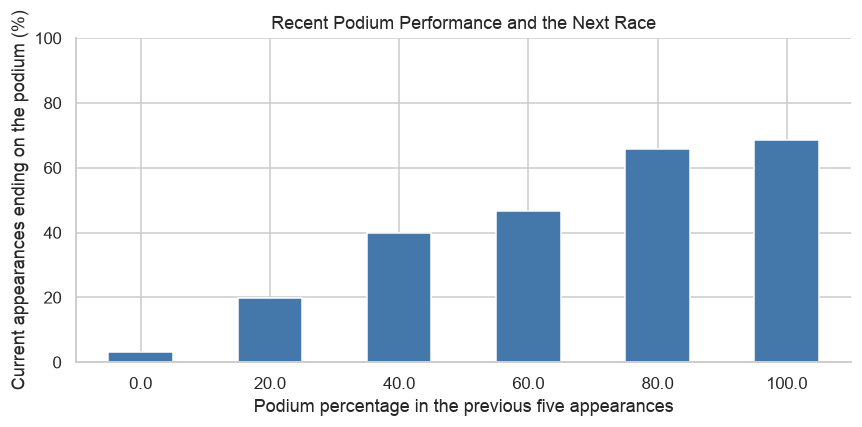

,count,mean,median
podium,,,
No podium,5167,11.87,12.2
Podium,893,6.12,5.8


In [126]:
training_form = model_features[
    (model_features["split"] == "Training")
    & (model_features["past_races_used"] == 5)
].copy()

# Compare recent podium performance with the current race outcome
form_summary = training_form.groupby(
    "recent_podium_rate"
).agg(
    appearances=("podium", "size"),
    current_podium_rate=("podium", "mean")
)

form_summary["current_podium_rate"] *= 100

display(form_summary.round(2))

ax = form_summary["current_podium_rate"].plot.bar(
    figsize=(8, 4),
    color="#4477AA"
)

ax.set_title("Recent Podium Performance and the Next Race")
ax.set_xlabel("Podium percentage in the previous five appearances")
ax.set_ylabel("Current appearances ending on the podium (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
show_plot("features_185")

# Compare previous average finishing orders by current outcome
display(
    training_form.groupby("podium")["recent_avg_finish"]
    .agg(["count", "mean", "median"])
    .rename(index={0: "No podium", 1: "Podium"})
    .round(2)
)

In [127]:
# Keep races that have recorded results
race_order = races_clean.loc[
    races_clean["raceId"].isin(results_clean["raceId"]),
    ["raceId", "year", "round"]
].sort_values(["year", "round"]).copy()

# Find the previous race, restarting at each new season
race_order["previous_raceId"] = (
    race_order.groupby("year")["raceId"]
    .shift(1)
    .astype("Int64")
)

race_order.head()

,raceId,year,round,previous_raceId
832,833,1950,1,<NA>
833,834,1950,2,833
834,835,1950,3,834
835,836,1950,4,835
836,837,1950,5,836


In [128]:
# Select and clearly name the standings information
previous_standings = driver_standings_clean[
    ["raceId", "driverId", "points", "position"]
].rename(columns={
    "raceId": "previous_raceId",
    "points": "driver_points_before_race",
    "position": "driver_standing_before_race"
})

standings_features = [
    "driver_points_before_race",
    "driver_standing_before_race"
]

# Allow this cell to be rerun without duplicating columns
model_features = model_features.drop(
    columns=standings_features + ["previous_raceId"],
    errors="ignore"
)

# Identify the previous race for each modeling appearance
model_features = model_features.merge(
    race_order[["raceId", "previous_raceId"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Match each driver to their standings after that previous race
model_features = model_features.merge(
    previous_standings,
    on=["previous_raceId", "driverId"],
    how="left",
    validate="many_to_one"
)

# Championship points begin at zero for the first race of the season
first_race = model_features["previous_raceId"].isna()

model_features.loc[
    first_race, "driver_points_before_race"
] = 0

display(
    model_features[
        ["driverId", "year", "round", "previous_raceId"]
        + standings_features
    ].sort_values(["driverId", "year", "round"]).head(12)
)

,driverId,year,round,previous_raceId,driver_points_before_race,driver_standing_before_race
1452,1,2007,1,<NA>,0.0,NaN
1474,1,2007,2,36,6.0,3.0
1496,1,2007,3,37,14.0,3.0
1518,1,2007,4,38,22.0,3.0
1540,1,2007,5,39,30.0,1.0
1562,1,2007,6,40,38.0,2.0
1584,1,2007,7,41,48.0,1.0
1606,1,2007,8,42,58.0,1.0
1628,1,2007,9,43,64.0,1.0
1650,1,2007,10,44,70.0,1.0


,appearances,podium_rate
driver_standing_before_race,,
1.0,284,66.55
2.0,284,56.34
3.0,283,42.05
4.0,281,34.88
5.0,284,34.15
6.0,280,20.36
7.0,278,10.43
8.0,277,10.47
9.0,278,3.60


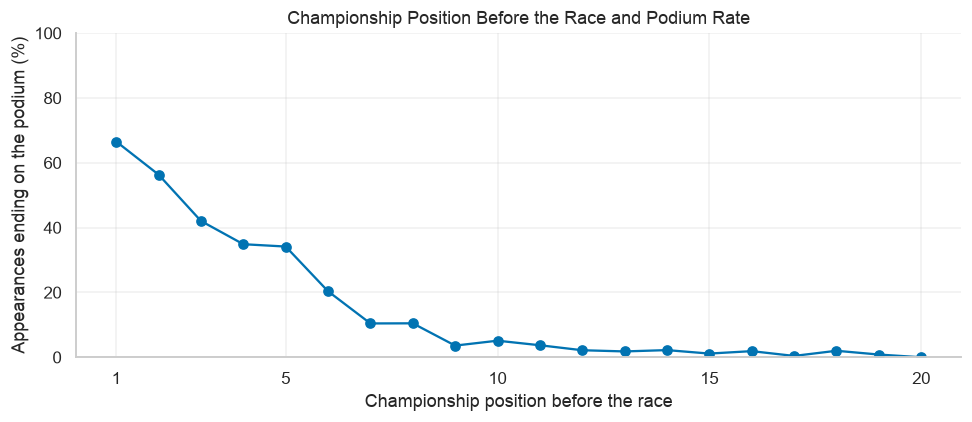

In [129]:
training_standings = model_features[
    model_features["split"] == "Training"
].copy()

# Examine championship positions 1–20
selected = training_standings[
    training_standings["driver_standing_before_race"].between(1, 20)
]

standing_summary = selected.groupby(
    "driver_standing_before_race"
).agg(
    appearances=("podium", "size"),
    podium_rate=("podium", "mean")
)

standing_summary["podium_rate"] *= 100

display(standing_summary.round(2))

ax = standing_summary["podium_rate"].plot(
    marker="o",
    figsize=(9, 4)
)

ax.set_title("Championship Position Before the Race and Podium Rate")
ax.set_xlabel("Championship position before the race")
ax.set_ylabel("Appearances ending on the podium (%)")
ax.set_ylim(0, 100)
ax.set_xticks([1, 5, 10, 15, 20])
ax.grid(alpha=0.3)

plt.tight_layout()
show_plot("features_188")

In [130]:
# Select constructor information for our modeling races
constructor_lookup = results_clean.loc[
    results_clean["raceId"].isin(model_features["raceId"]),
    ["raceId", "driverId", "constructorId"]
].copy()

# Confirm that no constructor-selection rule is needed
assert not constructor_lookup.duplicated(
    ["raceId", "driverId"]
).any()

constructor_features = [
    "constructor_points_before_race",
    "constructor_standing_before_race"
]

# Allow this cell to be rerun
model_features = model_features.drop(
    columns=["constructorId"] + constructor_features,
    errors="ignore"
)

# Add the constructor for each driver–race appearance
model_features = model_features.merge(
    constructor_lookup,
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

assert model_features["constructorId"].notna().all()

In [131]:
# Select standings recorded after the previous race
previous_constructor_standings = constructor_standings_clean[
    ["raceId", "constructorId", "points", "position"]
].rename(columns={
    "raceId": "previous_raceId",
    "points": "constructor_points_before_race",
    "position": "constructor_standing_before_race"
})

model_features = model_features.merge(
    previous_constructor_standings,
    on=["previous_raceId", "constructorId"],
    how="left",
    validate="many_to_one"
)

# Each season begins with zero championship points
first_race = model_features["previous_raceId"].isna()

model_features.loc[
    first_race, "constructor_points_before_race"
] = 0

display(
    model_features[
        ["driverId", "constructorId", "year", "round"]
        + constructor_features
    ].head(12)
)

,driverId,constructorId,year,round,constructor_points_before_race,constructor_standing_before_race
0,2,15,2003,1,0.0,NaN
1,4,4,2003,1,0.0,NaN
2,8,1,2003,1,0.0,NaN
3,14,1,2003,1,0.0,NaN
4,15,4,2003,1,0.0,NaN
5,17,19,2003,1,0.0,NaN
6,18,16,2003,1,0.0,NaN
7,21,17,2003,1,0.0,NaN
8,22,6,2003,1,0.0,NaN
9,23,3,2003,1,0.0,NaN


,appearances,podium_rate
constructor_standing_before_race,,
1.0,568,57.57
2.0,568,39.26
3.0,568,26.58
4.0,568,11.09
5.0,568,4.58
6.0,568,2.64
7.0,566,2.12
8.0,564,1.24
9.0,557,0.72


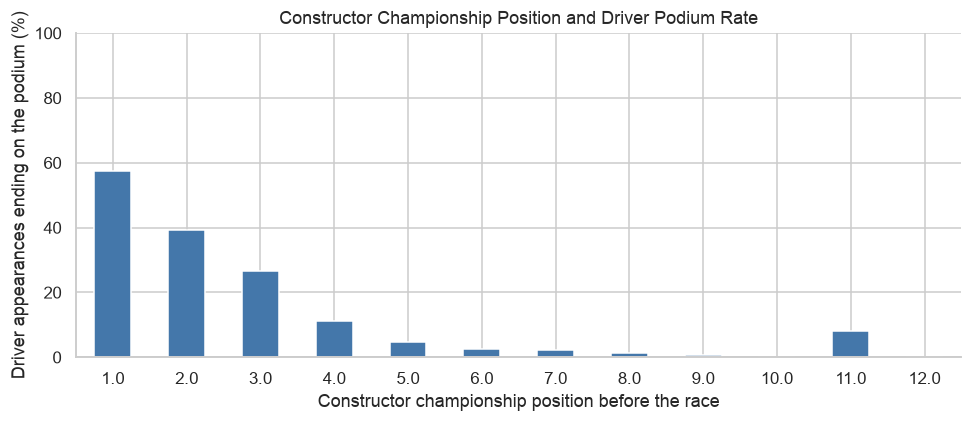

,count,mean,median
podium,,,
No podium,5479,47.35,15.0
Podium,900,169.89,117.5


In [132]:
# Investigate using training appearances only
training_constructor = model_features[
    model_features["split"] == "Training"
].copy()

constructor_summary = training_constructor.groupby(
    "constructor_standing_before_race"
).agg(
    appearances=("podium", "size"),
    podium_rate=("podium", "mean")
)

constructor_summary["podium_rate"] *= 100

display(constructor_summary.round(2))

ax = constructor_summary["podium_rate"].plot.bar(
    figsize=(9, 4),
    color="#4477AA"
)

ax.set_title("Constructor Championship Position and Driver Podium Rate")
ax.set_xlabel("Constructor championship position before the race")
ax.set_ylabel("Driver appearances ending on the podium (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
show_plot("features_191")

# Examine pre-race constructor points alongside podium outcomes
display(
    training_constructor.groupby("podium")[
        "constructor_points_before_race"
    ].agg(["count", "mean", "median"])
    .rename(index={0: "No podium", 1: "Podium"})
    .round(2)
)

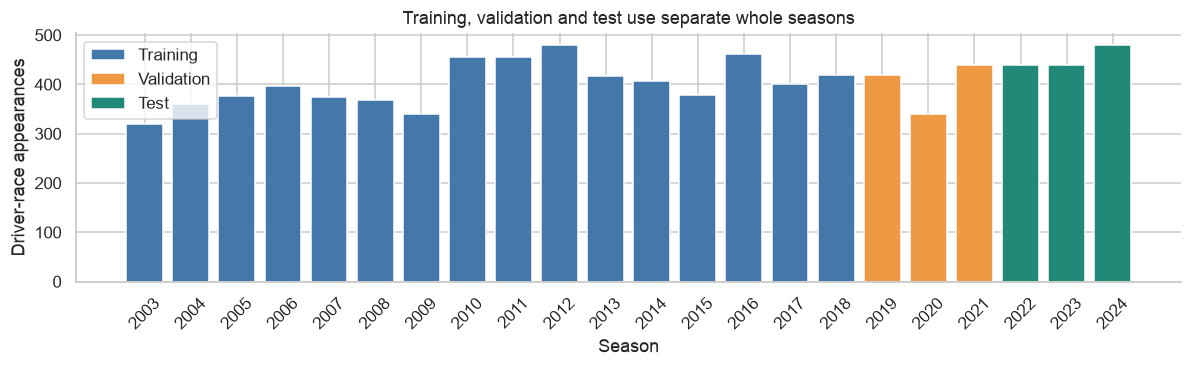

In [133]:
# Show the same chronological split as seasons, not a random mixture of rows.
year_counts = model_features.groupby(["year", "split"]).size().reset_index(name="appearances")
colors = {"Training": "#4477AA", "Validation": "#EE9944", "Test": "#228877"}
fig, ax = plt.subplots(figsize=(11, 3.5))
for label in ["Training", "Validation", "Test"]:
    subset = year_counts[year_counts["split"].eq(label)]
    ax.bar(subset["year"], subset["appearances"], label=label, color=colors[label])
ax.set(xlabel="Season", ylabel="Driver-race appearances",
       title="Training, validation and test use separate whole seasons")
ax.set_xticks(year_counts["year"].unique())
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout()
show_plot("features_chronological_split")

## Candidate features and their evidence
Relative Q1 pace is the percentage above the fastest recorded Q1 time in that race.
It compares drivers in the same session. Missing times stay missing. Constructor form measures
recent team performance, with a count showing how much earlier history supports it.

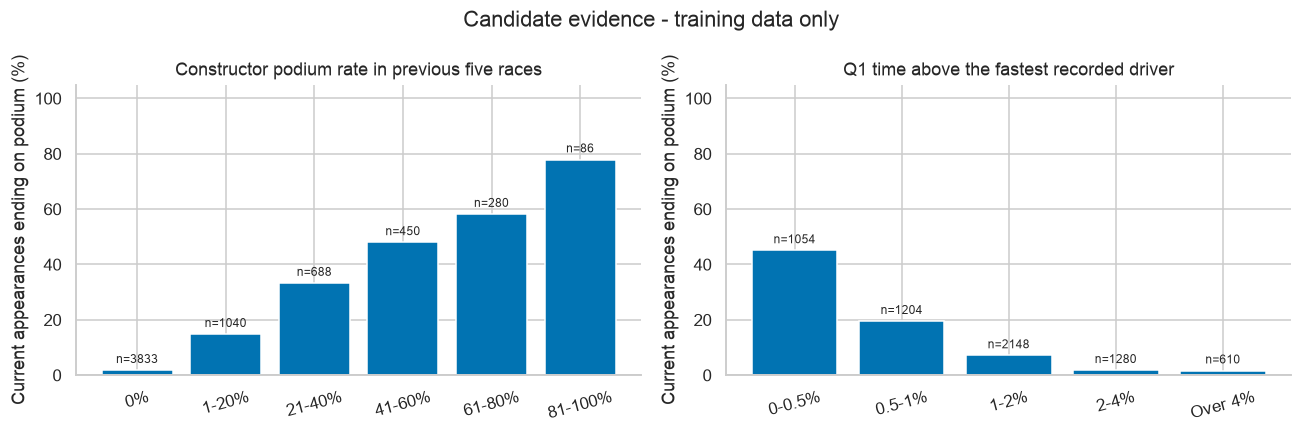

In [134]:
q1_pace = qualifying_clean[["raceId", "driverId", "q1_seconds"]].copy()
fastest_q1 = q1_pace.groupby("raceId")["q1_seconds"].transform("min")
q1_pace["q1_relative_pct"] = (q1_pace["q1_seconds"] / fastest_q1 - 1) * 100
model_features = model_features.merge(
    q1_pace[["raceId", "driverId", "q1_relative_pct"]],
    on=["raceId", "driverId"], how="left", validate="one_to_one")
training_data = model_features[model_features["split"].eq("Training")].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
specs = [
    ("constructor_recent_podium_rate", [-.01, 0, 20, 40, 60, 80, 100],
     ["0%", "1-20%", "21-40%", "41-60%", "61-80%", "81-100%"],
     "Constructor podium rate in previous five races"),
    ("q1_relative_pct", [-.01, .5, 1, 2, 4, np.inf],
     ["0-0.5%", "0.5-1%", "1-2%", "2-4%", "Over 4%"],
     "Q1 time above the fastest recorded driver")
]
for ax, (feature, edges, labels, title) in zip(axes, specs):
    groups = pd.cut(training_data[feature], edges, labels=labels)
    evidence = training_data.groupby(groups, observed=True)["podium"].agg(["mean", "size"])
    bars = ax.bar(evidence.index.astype(str), evidence["mean"] * 100)
    ax.bar_label(bars, labels=["n=" + str(n) for n in evidence["size"]], fontsize=8, padding=3)
    ax.set(title=title, ylabel="Current appearances ending on podium (%)", ylim=(0, 105))
    ax.tick_params(axis="x", rotation=15)
plt.suptitle("Candidate evidence - training data only")
plt.tight_layout()
show_plot("features_candidate_evidence")

## Leakage checks
Temporarily change outcomes in one race and in future races. Earlier history must stay unchanged.
Standings are joined from the previous recorded race within the same season. Season-opening points
are zero; other unavailable standings remain missing for training-only imputation.

Later test races may use history from earlier completed test races. This is a rolling pre-race
simulation; model parameters and preprocessing never learn from test labels.

In [135]:
history_fields = form_features + constructor_form_features
probe_race = int(model_features.loc[model_features["year"].eq(2020), "raceId"].iloc[0])
probe_date = races_clean.set_index("raceId").loc[probe_race, "date"]
changed_entries = selected_results.copy()
current = changed_entries["raceId"].eq(probe_race)
changed_entries.loc[current, "positionOrder"] = np.arange(current.sum())[::-1] + 1
changed_history = historical_form(changed_entries)
before = driver_history.loc[driver_history["raceId"].eq(probe_race)].sort_values("driverId")
after = changed_history.loc[changed_history["raceId"].eq(probe_race)].sort_values("driverId")
np.testing.assert_allclose(before[history_fields], after[history_fields], equal_nan=True)

future_races = races_clean.loc[races_clean["date"].gt(probe_date), "raceId"]
changed_entries = selected_results.copy()
changed_entries.loc[changed_entries["raceId"].isin(future_races), "positionOrder"] = 99
changed_history = historical_form(changed_entries)
before = driver_history.loc[driver_history["date"].le(probe_date)].sort_values(["raceId", "driverId"])
after = changed_history.loc[changed_history["date"].le(probe_date)].sort_values(["raceId", "driverId"])
np.testing.assert_allclose(before[history_fields], after[history_fields], equal_nan=True)
previous_dates = races_clean.set_index("raceId")["date"]
standings_source_date = model_features["previous_raceId"].map(previous_dates)
assert (standings_source_date.isna() | standings_source_date.lt(model_features["date"])).all()
print("PASS: current-race/teammate and future-outcome changes do not alter pre-race history.")
print("PASS: standings sources are earlier than the prediction date.")

PASS: current-race/teammate and future-outcome changes do not alter pre-race history.
PASS: standings sources are earlier than the prediction date.


## Preprocessing
The baseline keeps the original nine numeric features and constructor identity.
Numeric gaps receive training medians; numeric values are standardized.
Missing indicators and constructor categories remain separate from scaling.

The same fitted transformer is applied to validation and test rows. This pipeline also makes
saved-model inference repeat the exact training transformations.

In [136]:
numeric_features = [
    "grid_for_analysis", "qualifying_position", "recent_podium_rate", "recent_avg_finish",
    "past_races_used", "driver_points_before_race", "driver_standing_before_race",
    "constructor_points_before_race", "constructor_standing_before_race"
]
candidate_features = constructor_form_features + ["q1_relative_pct"]
all_numeric_features = numeric_features + candidate_features

train_mask = model_features["split"].eq("Training")
validation_mask = model_features["split"].eq("Validation")
test_mask = model_features["split"].eq("Test")
y_train = model_features.loc[train_mask, "podium"].astype(int)
y_validation = model_features.loc[validation_mask, "podium"].astype(int)
y_test = model_features.loc[test_mask, "podium"].astype(int)

def raw_inputs(frame, numeric_columns, include_constructor):
    inputs = frame[numeric_columns].astype(float).copy()
    if include_constructor:
        inputs["constructorId"] = frame["constructorId"].astype(str)
    return inputs

def make_preprocessor(numeric_columns, include_constructor, order="Fill then scale"):
    steps = [("fill", SimpleImputer(strategy="median", keep_empty_features=True)),
             ("scale", StandardScaler())]
    if order == "Scale then fill":
        steps.reverse()
    parts = [
        ("numeric", Pipeline(steps), numeric_columns),
        ("missing", MissingIndicator(features="missing-only", error_on_new=False), numeric_columns)
    ]
    if include_constructor:
        parts.append(("constructor", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                      ["constructorId"]))
    return ColumnTransformer(parts, verbose_feature_names_out=False).set_output(transform="pandas")

baseline_raw = raw_inputs(model_features, numeric_features, True)
baseline_preprocessor = make_preprocessor(numeric_features, True)
X_train = baseline_preprocessor.fit_transform(baseline_raw.loc[train_mask])
X_validation = baseline_preprocessor.transform(baseline_raw.loc[validation_mask])
assert X_train.index.equals(y_train.index)
assert np.isfinite(X_train.to_numpy(dtype=float)).all()
assert np.isfinite(X_validation.to_numpy(dtype=float)).all()
print("Initial baseline inputs:", X_train.shape[1])

Initial baseline inputs: 46


,Stored dtype,Missing count,Missing percentage,Distinct values
grid_for_analysis,Int64,17,0.27,24
qualifying_position,Int64,21,0.33,24
recent_podium_rate,float64,72,1.12,9
recent_avg_finish,float64,72,1.12,164
past_races_used,int64,0,0.00,6
driver_points_before_race,float64,132,2.06,306
driver_standing_before_race,float64,474,7.39,27
constructor_points_before_race,float64,32,0.50,409
constructor_standing_before_race,float64,374,5.83,12
constructor_recent_podium_rate,float64,34,0.53,18


,grid_for_analysis,qualifying_position,recent_podium_rate,recent_avg_finish,past_races_used,driver_points_before_race,driver_standing_before_race,constructor_points_before_race,constructor_standing_before_race,constructor_recent_podium_rate,constructor_recent_avg_finish,constructor_past_races_used,q1_relative_pct
count,6394.0,6390.0,6339.00,6339.00,6411.00,6279.00,5937.00,6379.00,6037.00,6377.00,6377.00,6411.00,6296.00
mean,11.22,11.21,14.14,11.18,4.83,32.60,11.33,64.64,5.85,14.19,11.22,4.92,1.82
std,6.25,6.25,25.18,4.53,0.76,54.38,6.50,104.68,3.12,22.84,4.23,0.53,1.86
min,1.0,1.0,0.00,1.00,0.00,0.00,1.00,0.00,1.00,0.00,1.50,0.00,0.00
25%,6.0,6.0,0.00,7.80,5.00,0.00,6.00,2.00,3.00,0.00,8.10,5.00,0.72
50%,11.0,11.0,0.00,11.60,5.00,10.00,11.00,21.00,6.00,0.00,11.50,5.00,1.36
75%,16.75,16.0,20.00,14.60,5.00,39.00,17.00,76.00,8.00,20.00,14.30,5.00,2.27
max,24.0,24.0,100.00,24.00,5.00,383.00,27.00,722.00,12.00,100.00,22.10,5.00,33.29


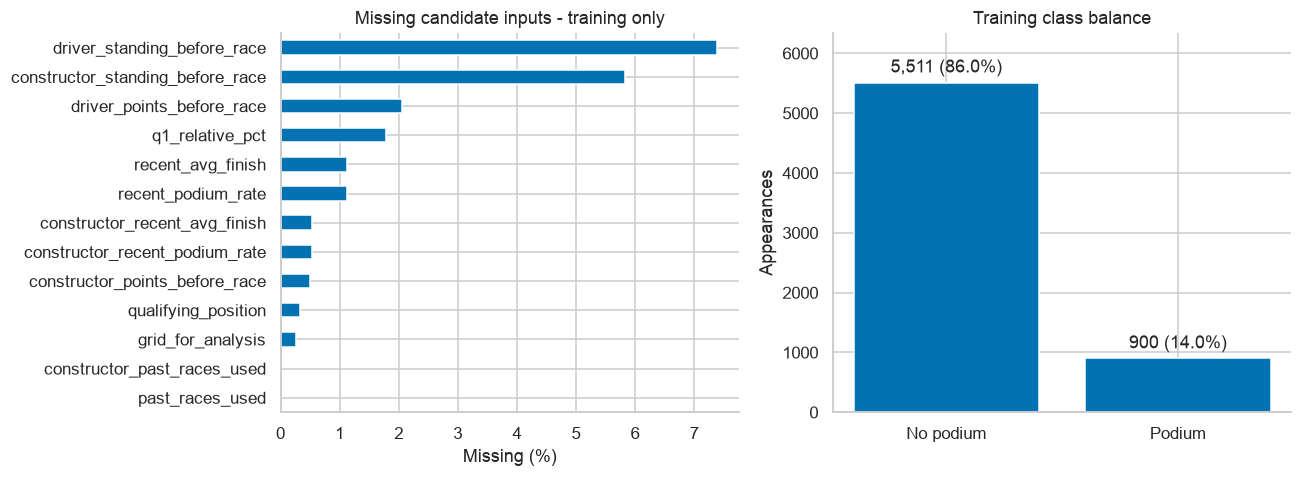

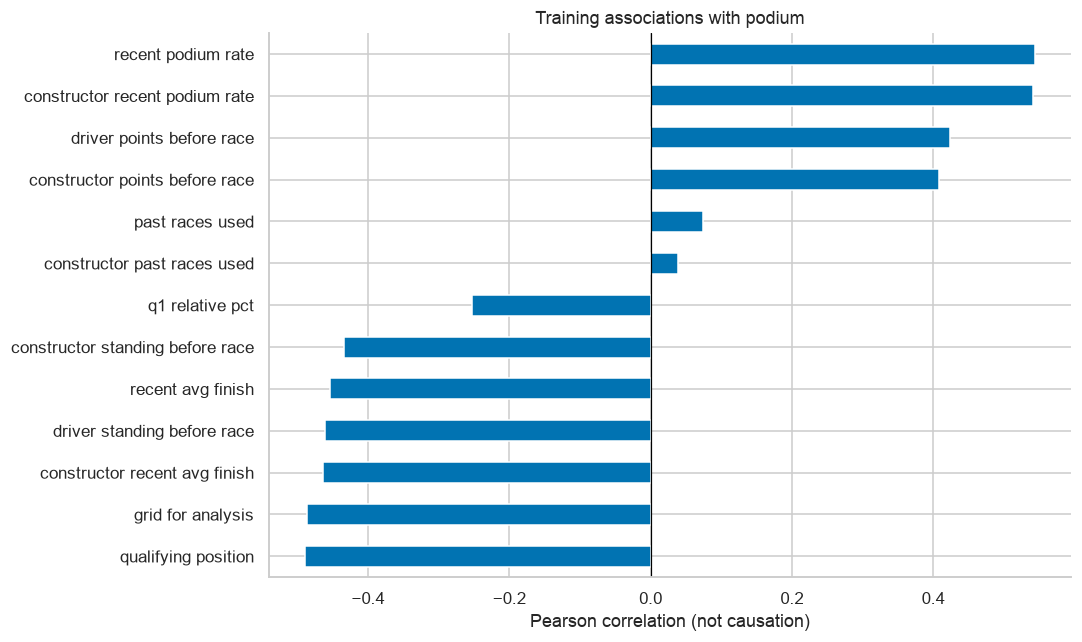

In [137]:
feature_review = pd.DataFrame({
    "Stored dtype": training_data[all_numeric_features].dtypes.astype(str),
    "Missing count": training_data[all_numeric_features].isna().sum(),
    "Missing percentage": training_data[all_numeric_features].isna().mean().mul(100).round(2),
    "Distinct values": training_data[all_numeric_features].nunique()
})
display(feature_review)
display(training_data[all_numeric_features].describe().round(2))
save_table(feature_review, "feature_review", index=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
feature_review["Missing percentage"].sort_values().plot.barh(ax=axes[0])
axes[0].set(title="Missing candidate inputs - training only", xlabel="Missing (%)", ylabel="")
counts = y_train.value_counts().reindex([0, 1])
bars = axes[1].bar(["No podium", "Podium"], counts)
axes[1].bar_label(bars, labels=[f"{n:,} ({n/len(y_train):.1%})" for n in counts], padding=4)
axes[1].set(title="Training class balance", ylabel="Appearances")
axes[1].margins(y=.15)
plt.tight_layout()
show_plot("features_missingness_and_class_balance")

correlations = training_data[all_numeric_features].astype(float).corrwith(training_data["podium"]).sort_values()
ax = correlations.rename(index=lambda s: s.replace("_", " ")).plot.barh(figsize=(10, 6))
ax.axvline(0, color="black", linewidth=.8)
ax.set(title="Training associations with podium", xlabel="Pearson correlation (not causation)", ylabel="")
plt.tight_layout()
show_plot("features_correlations")
save_table(correlations.rename("Correlation").to_frame(), "feature_correlations", index=True)

,Missing before,Missing after,Mean before,Mean after
grid_for_analysis,17,0,11.224,11.223
qualifying_position,21,0,11.209,11.209
recent_podium_rate,72,0,14.136,13.977
recent_avg_finish,72,0,11.184,11.189
past_races_used,0,0,4.835,4.835
driver_points_before_race,132,0,32.603,32.137
driver_standing_before_race,474,0,11.331,11.307
constructor_points_before_race,32,0,64.639,64.421
constructor_standing_before_race,374,0,5.855,5.863


,Mean before,Mean after,Standard deviation before,Standard deviation after
grid_for_analysis,11.223,-0.0,6.246,1.0
qualifying_position,11.209,0.0,6.235,1.0
recent_podium_rate,13.977,0.0,25.076,1.0
recent_avg_finish,11.189,0.0,4.509,1.0
past_races_used,4.835,0.0,0.762,1.0
driver_points_before_race,32.137,0.0,53.912,1.0
driver_standing_before_race,11.307,0.0,6.252,1.0
constructor_points_before_race,64.421,-0.0,104.457,1.0
constructor_standing_before_race,5.863,-0.0,3.030,1.0


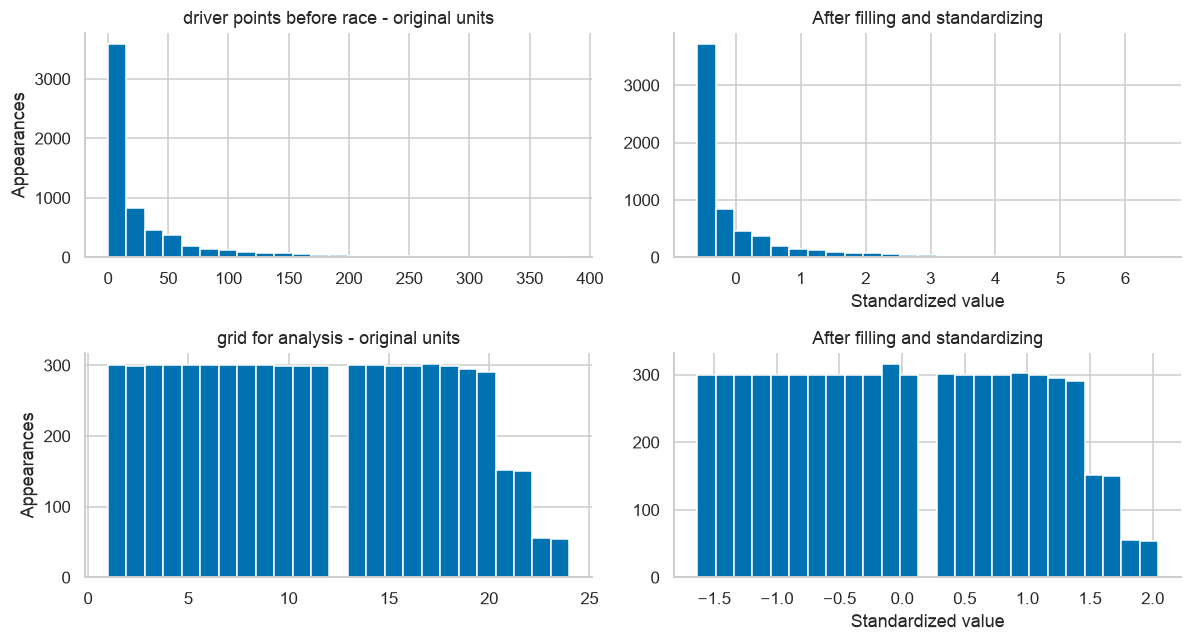

In [138]:
scaler = baseline_preprocessor.named_transformers_["numeric"].named_steps["scale"]
filled_training = pd.DataFrame(
    baseline_preprocessor.named_transformers_["numeric"].named_steps["fill"].transform(
        baseline_raw.loc[train_mask, numeric_features]),
    columns=numeric_features, index=y_train.index)
imputation_comparison = pd.DataFrame({
    "Missing before": baseline_raw.loc[train_mask, numeric_features].isna().sum(),
    "Missing after": filled_training.isna().sum(),
    "Mean before": baseline_raw.loc[train_mask, numeric_features].mean(),
    "Mean after": filled_training.mean()
})
scaling_comparison = pd.DataFrame({
    "Mean before": filled_training.mean(), "Mean after": X_train[numeric_features].mean(),
    "Standard deviation before": filled_training.std(ddof=0),
    "Standard deviation after": X_train[numeric_features].std(ddof=0)
})
display(imputation_comparison.round(3))
display(scaling_comparison.round(3))
save_table(imputation_comparison, "imputation_comparison", index=True)
save_table(scaling_comparison, "scaling_comparison", index=True)

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for row, feature in enumerate(["driver_points_before_race", "grid_for_analysis"]):
    axes[row, 0].hist(training_data[feature].dropna(), bins=25)
    axes[row, 0].set(title=feature.replace("_", " ") + " - original units", ylabel="Appearances")
    axes[row, 1].hist(X_train[feature], bins=25)
    axes[row, 1].set(title="After filling and standardizing", xlabel="Standardized value")
plt.tight_layout()
show_plot("features_before_after_preprocessing")

The histograms show changed units/ranges, not recovered true missing values.
Filling can add observations near the training median. Standardization centers and rescales
numeric inputs; it does not make the data more accurate or guarantee a normal distribution.

In [139]:
feature_catalog = pd.DataFrame([
    ["Starting grid / qualifying position", "Recorded positive grid and qualifying rank", "Available after qualifying"],
    ["Recent driver form", "Previous five driver appearances", "Shift before rolling; count retained"],
    ["Driver and constructor standings", "Immediately previous recorded race in the season", "No current-race standings"],
    ["Constructor identity", "Nominal constructor category", "Candidate; compared with removal in Stage 5"],
    ["Candidate constructor form", "Previous five constructor-race aggregates", "Aggregate both cars before shifting"],
    ["Candidate Q1 relative pace", "Recorded Q1 time relative to race Q1 minimum", "Same completed qualifying session"]
], columns=["Group", "Source", "Cutoff justification"])
display(feature_catalog)
save_table(feature_catalog, "feature_catalog")
FORBIDDEN = {"positionOrder", "position", "points", "status", "statusId", "laps", "time",
             "milliseconds", "fastestLap", "fastestLapTime", "podium", "resultId"}
assert not FORBIDDEN.intersection(all_numeric_features + ["constructorId"])
assert not model_features.duplicated(["raceId", "driverId"]).any()
assert model_features.groupby("raceId")["split"].nunique().eq(1).all()
save_table(model_features[["raceId", "driverId", "year", "round", "date", "split", "podium",
                           "constructorId"] + all_numeric_features], "modeling_table")

,Group,Source,Cutoff justification
0,Starting grid / qualifying position,Recorded positive grid and qualifying rank,Available after qualifying
1,Recent driver form,Previous five driver appearances,Shift before rolling; count retained
2,Driver and constructor standings,Immediately previous recorded race in the season,No current-race standings
3,Constructor identity,Nominal constructor category,Candidate; compared with removal in Stage 5
4,Candidate constructor form,Previous five constructor-race aggregates,Aggregate both cars before shifting
5,Candidate Q1 relative pace,Recorded Q1 time relative to race Q1 minimum,Same completed qualifying session


# Stage 4 - Predictive Modeling
Logistic regression is the statistical baseline. Random forest tests nonlinear tree interactions;
a shallow neural network tests learned nonlinear combinations. All use the same prepared baseline
rows and columns. Compare eight visible configurations, including our original three.

PR-AUC is primary because podiums are relatively uncommon; F1 is secondary for the precision/recall
tradeoff. Report ROC-AUC, precision and recall too. Trapezoidal PR-AUC and average precision are
different quantities; AP and log loss are supplementary. Validation selects settings and thresholds.

In [140]:
def evaluate_probabilities(target, probabilities, threshold=.5):
    precision, recall, _ = precision_recall_curve(target, probabilities)
    predicted = np.asarray(probabilities) >= threshold
    return {
        "ROC-AUC": roc_auc_score(target, probabilities),
        "PR-AUC": auc(recall, precision),
        "F1": f1_score(target, predicted, zero_division=0),
        "Precision": precision_score(target, predicted, zero_division=0),
        "Recall": recall_score(target, predicted, zero_division=0),
        "Average precision": average_precision_score(target, probabilities),
        "Log loss": log_loss(target, probabilities, labels=[0, 1])
    }

def select_threshold(target, probabilities):
    trials = pd.DataFrame({
        "Threshold": np.round(np.linspace(.05, .95, 91), 2)
    })
    trials["F1"] = [f1_score(target, probabilities >= t, zero_division=0)
                    for t in trials["Threshold"]]
    trials["Distance from 0.50"] = (trials["Threshold"] - .5).abs()
    best = trials.sort_values(["F1", "Distance from 0.50"], ascending=[False, True]).iloc[0]
    return float(best["Threshold"]), trials

# Fixed-duration copies keep ablation/feature comparisons on the same training budget.
def train_copy(base_model, inputs, target, epochs):
    fitted = clone(base_model)
    if isinstance(fitted, MLPClassifier):
        for _ in range(epochs):
            fitted.partial_fit(inputs, target, classes=[0, 1])
    else:
        fitted.fit(inputs, target)
    return fitted

In [141]:
attempt_rows, model_objects, attempt_epochs, neural_histories = [], {}, {}, {}

def run_attempt(name, family, estimator, original_configuration=False):
    start = time.monotonic()
    history, best_epoch = [], 0
    if isinstance(estimator, MLPClassifier):
        best_score, stale, best_model = -np.inf, 0, None
        for epoch in range(1, 201):
            estimator.partial_fit(X_train, y_train, classes=[0, 1])
            p_train = estimator.predict_proba(X_train)[:, 1]
            p_val = estimator.predict_proba(X_validation)[:, 1]
            score = evaluate_probabilities(y_validation, p_val)["PR-AUC"]
            history.append({
                "Epoch": epoch, "Training PR-AUC": evaluate_probabilities(y_train, p_train)["PR-AUC"],
                "Validation PR-AUC": score, "Training loss": log_loss(y_train, p_train),
                "Validation loss": log_loss(y_validation, p_val)
            })
            if score > best_score:
                best_score, best_epoch, stale = score, epoch, 0
                best_model = deepcopy(estimator)
            else:
                stale += 1
            if stale >= 20:
                break
        estimator = best_model
        neural_histories[name] = pd.DataFrame(history)
        print(name, "- restored epoch", best_epoch, "after", len(history), "epochs")
    else:
        estimator.fit(X_train, y_train)
    probabilities = estimator.predict_proba(X_validation)[:, 1]
    threshold, _ = select_threshold(y_validation, probabilities)
    attempt_rows.append({
        "Attempt": name, "Model": family, "Original configuration": original_configuration,
        "Threshold": threshold, "Best epoch": best_epoch,
        **evaluate_probabilities(y_validation, probabilities, threshold),
        "Seconds": time.monotonic() - start
    })
    model_objects[name] = estimator
    attempt_epochs[name] = best_epoch
    display(pd.DataFrame([attempt_rows[-1]]).round(4))

## Original baseline configurations
These reproduce the three model configurations used before the added hyperparameter comparisons.

In [142]:
run_attempt("Logistic C=1", "Logistic regression",
            LogisticRegression(C=1, max_iter=1000, random_state=SEED), True)

,Attempt,Model,Original configuration,Threshold,Best epoch,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss,Seconds
0,Logistic C=1,Logistic regression,True,0.38,0,0.9293,0.7246,0.7241,0.6651,0.7944,0.7264,0.2243,0.0835


In [143]:
run_attempt("Forest depth=8", "Random forest",
            RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                   random_state=SEED, n_jobs=1), True)

,Attempt,Model,Original configuration,Threshold,Best epoch,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss,Seconds
0,Forest depth=8,Random forest,True,0.44,0,0.9387,0.7443,0.7273,0.7213,0.7333,0.7457,0.2143,0.4835


In [144]:
run_attempt("Neural 32-16", "Neural network",
            MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu", solver="adam",
                          alpha=.01, batch_size=128, learning_rate_init=.001,
                          random_state=SEED), True)

Neural 32-16 - restored epoch 31 after 51 epochs


,Attempt,Model,Original configuration,Threshold,Best epoch,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss,Seconds
0,Neural 32-16,Neural network,True,0.43,31,0.9309,0.7461,0.7179,0.6667,0.7778,0.7469,0.225,1.1163


## Additional configurations
Smaller/larger logistic C changes regularization. Forest variants change depth and leaf size.
The second network has one hidden layer. Keep rows, features and seed fixed.

In [145]:
run_attempt("Logistic C=0.1", "Logistic regression",
            LogisticRegression(C=.1, max_iter=1000, random_state=SEED))

,Attempt,Model,Original configuration,Threshold,Best epoch,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss,Seconds
0,Logistic C=0.1,Logistic regression,False,0.39,0,0.9293,0.7211,0.7231,0.6714,0.7833,0.7229,0.224,0.0738


In [146]:
run_attempt("Logistic C=10", "Logistic regression",
            LogisticRegression(C=10, max_iter=1000, random_state=SEED))

,Attempt,Model,Original configuration,Threshold,Best epoch,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss,Seconds
0,Logistic C=10,Logistic regression,False,0.32,0,0.9294,0.7247,0.7241,0.6504,0.8167,0.7264,0.2247,0.0827


In [147]:
run_attempt("Forest depth=5", "Random forest",
            RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=10,
                                   random_state=SEED, n_jobs=1))

,Attempt,Model,Original configuration,Threshold,Best epoch,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss,Seconds
0,Forest depth=5,Random forest,False,0.44,0,0.9382,0.7366,0.7333,0.7333,0.7333,0.7382,0.2182,0.3913


In [148]:
run_attempt("Forest unrestricted", "Random forest",
            RandomForestClassifier(n_estimators=300, max_depth=None, min_samples_leaf=3,
                                   random_state=SEED, n_jobs=1))

,Attempt,Model,Original configuration,Threshold,Best epoch,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss,Seconds
0,Forest unrestricted,Random forest,False,0.39,0,0.9367,0.7447,0.724,0.6814,0.7722,0.7464,0.2158,0.6521


In [149]:
run_attempt("Neural 16", "Neural network",
            MLPClassifier(hidden_layer_sizes=(16,), activation="relu", solver="adam",
                          alpha=.01, batch_size=128, learning_rate_init=.001,
                          random_state=SEED))

Neural 16 - restored epoch 79 after 99 epochs


,Attempt,Model,Original configuration,Threshold,Best epoch,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss,Seconds
0,Neural 16,Neural network,False,0.47,79,0.9319,0.7389,0.7243,0.7053,0.7444,0.74,0.2223,1.8679


,Attempt,Model,Original configuration,Threshold,Best epoch,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss,Seconds
0,Logistic C=1,Logistic regression,True,0.38,0,0.9293,0.7246,0.7241,0.6651,0.7944,0.7264,0.2243,0.0835
1,Forest depth=8,Random forest,True,0.44,0,0.9387,0.7443,0.7273,0.7213,0.7333,0.7457,0.2143,0.4835
2,Neural 32-16,Neural network,True,0.43,31,0.9309,0.7461,0.7179,0.6667,0.7778,0.7469,0.2250,1.1163
3,Logistic C=0.1,Logistic regression,False,0.39,0,0.9293,0.7211,0.7231,0.6714,0.7833,0.7229,0.2240,0.0738
4,Logistic C=10,Logistic regression,False,0.32,0,0.9294,0.7247,0.7241,0.6504,0.8167,0.7264,0.2247,0.0827
5,Forest depth=5,Random forest,False,0.44,0,0.9382,0.7366,0.7333,0.7333,0.7333,0.7382,0.2182,0.3913
6,Forest unrestricted,Random forest,False,0.39,0,0.9367,0.7447,0.7240,0.6814,0.7722,0.7464,0.2158,0.6521
7,Neural 16,Neural network,False,0.47,79,0.9319,0.7389,0.7243,0.7053,0.7444,0.7400,0.2223,1.8679


,Model,Dataset,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
0,Neural network,Training,0.43,0.9411,0.7159,0.6689,0.6591,0.6789,0.7163,0.2053
1,Neural network,Validation,0.43,0.9309,0.7461,0.7179,0.6667,0.7778,0.7469,0.2250
2,Random forest,Training,0.39,0.9784,0.8857,0.7827,0.7515,0.8167,0.8857,0.1509
3,Random forest,Validation,0.39,0.9367,0.7447,0.7240,0.6814,0.7722,0.7464,0.2158
4,Logistic regression,Training,0.32,0.9306,0.6831,0.6593,0.5815,0.7611,0.6836,0.2196
5,Logistic regression,Validation,0.32,0.9294,0.7247,0.7241,0.6504,0.8167,0.7264,0.2247


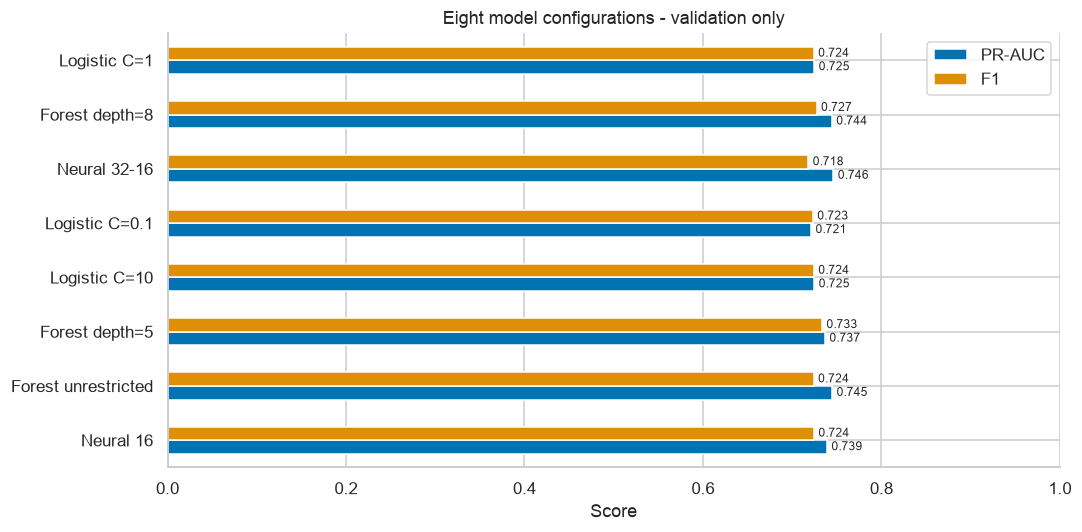

In [150]:
model_attempts = pd.DataFrame(attempt_rows)
display(model_attempts.round(4))
save_table(model_attempts, "model_attempts_validation")
best_attempts = (model_attempts.sort_values(["PR-AUC", "F1"], ascending=[False, False])
                 .drop_duplicates("Model").set_index("Model"))
models = {name: model_objects[row["Attempt"]] for name, row in best_attempts.iterrows()}
model_epochs = {name: attempt_epochs[row["Attempt"]] for name, row in best_attempts.iterrows()}
initial_rows = []
for name, fitted in models.items():
    threshold = float(best_attempts.loc[name, "Threshold"])
    for dataset, inputs, target in [
        ("Training", X_train, y_train), ("Validation", X_validation, y_validation)
    ]:
        initial_rows.append({"Model": name, "Dataset": dataset, "Threshold": threshold,
                             **evaluate_probabilities(target, fitted.predict_proba(inputs)[:, 1], threshold)})
initial_modeling_report = pd.DataFrame(initial_rows)
display(initial_modeling_report.round(4))
save_table(initial_modeling_report, "initial_training_validation")

ax = model_attempts.set_index("Attempt")[["PR-AUC", "F1"]].iloc[::-1].plot.barh(figsize=(10, 5))
ax.set(title="Eight model configurations - validation only", xlabel="Score", ylabel="", xlim=(0, 1))
for bars in ax.containers: ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
plt.tight_layout()
show_plot("models_eight_attempts")

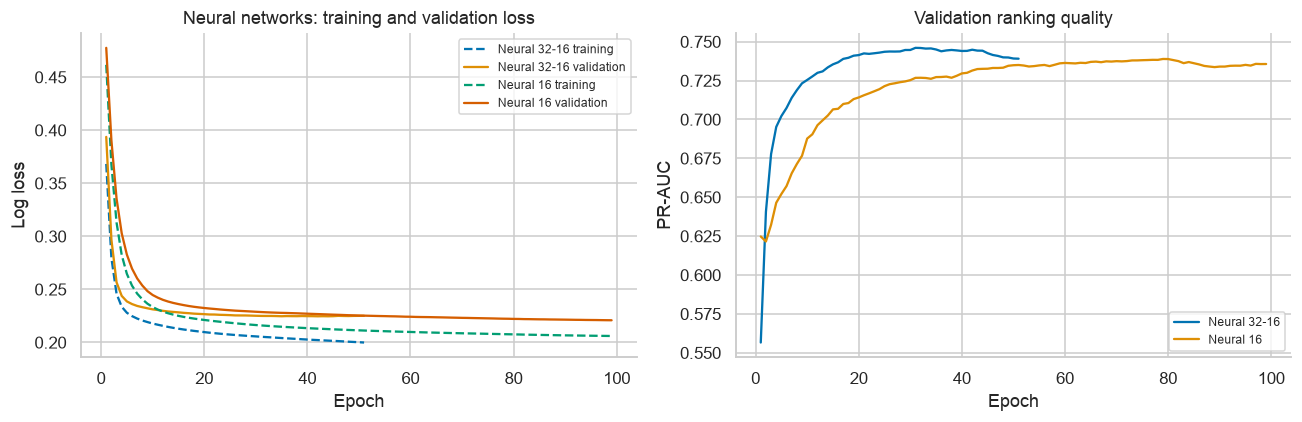

In [151]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in neural_histories.items():
    axes[0].plot(history["Epoch"], history["Training loss"], linestyle="--", label=name+" training")
    axes[0].plot(history["Epoch"], history["Validation loss"], label=name+" validation")
    axes[1].plot(history["Epoch"], history["Validation PR-AUC"], label=name)
axes[0].set(title="Neural networks: training and validation loss", xlabel="Epoch", ylabel="Log loss")
axes[1].set(title="Validation ranking quality", xlabel="Epoch", ylabel="PR-AUC")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout()
show_plot("models_neural_learning_curves")
for name, history in neural_histories.items():
    save_table(history, "history_" + name.replace(" ", "_"))

Logistic regression can miss nonlinear relationships. Forests can overfit historical categories;
networks depend on scaling, training duration and initialization. Training/validation comparisons
show transfer within these periods, not proof of future performance. Test evaluation waits until Stage 5.

# Stage 5 - Experiments
First preserve the original full-versus-reduced feature investigation. Then test the two candidate
feature additions with the selected configurations. All choices use validation; tests stay out of selection.

## Baseline group ablation
Use the original two-layer neural configuration as the fixed anchor. Remove each whole group,
including missing indicators and constructor encoding. Keep its selected epoch budget and threshold.
Positive PR-AUC drop means removal hurt; negative means removal helped.

In [152]:
raw_feature_groups = {
    "Grid": ["grid_for_analysis"],
    "Qualifying": ["qualifying_position", "q1_relative_pct"],
    "Recent driver form": form_features,
    "Driver standings": ["driver_points_before_race", "driver_standing_before_race"],
    "Constructor standings": ["constructor_points_before_race", "constructor_standing_before_race"],
    "Constructor identity": ["constructorId"],
    "Constructor form": constructor_form_features
}
def encoded_group_columns(columns, raw_group):
    selected = []
    for column in columns:
        raw = column.removeprefix("missingindicator_")
        if raw in raw_group or ("constructorId" in raw_group and column.startswith("constructorId_")):
            selected.append(column)
    return selected

reference_model = model_objects["Neural 32-16"]
reference_threshold = float(model_attempts.set_index("Attempt").loc["Neural 32-16", "Threshold"])
reference_epochs = attempt_epochs["Neural 32-16"]
baseline_score = evaluate_probabilities(
    y_validation, reference_model.predict_proba(X_validation)[:, 1], reference_threshold)
ablation_rows = [{"Removed group": "None (all features)", "Inputs": X_train.shape[1],
                  "PR-AUC drop": 0., **baseline_score}]
for group, raw_columns in raw_feature_groups.items():
    removed = encoded_group_columns(X_train.columns, raw_columns)
    if not removed: continue
    reduced_train = X_train.drop(columns=removed)
    reduced_val = X_validation.drop(columns=removed)
    fitted = train_copy(reference_model, reduced_train, y_train, reference_epochs)
    scores = evaluate_probabilities(y_validation, fitted.predict_proba(reduced_val)[:, 1], reference_threshold)
    ablation_rows.append({"Removed group": group, "Inputs": reduced_train.shape[1],
                          "PR-AUC drop": baseline_score["PR-AUC"]-scores["PR-AUC"], **scores})
ablation_results = pd.DataFrame(ablation_rows).set_index("Removed group")
display(ablation_results.round(4))
save_table(ablation_results, "baseline_group_ablation", index=True)

,Inputs,PR-AUC drop,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
Removed group,,,,,,,,,
None (all features),46,0.0000,0.9309,0.7461,0.7179,0.6667,0.7778,0.7469,0.2250
Grid,44,0.0151,0.9280,0.7310,0.7077,0.6571,0.7667,0.7324,0.2267
Qualifying,44,-0.0069,0.9310,0.7529,0.7147,0.6651,0.7722,0.7538,0.2240
Recent driver form,41,0.0049,0.9369,0.7411,0.7296,0.6745,0.7944,0.7423,0.2208
Driver standings,42,0.0027,0.9313,0.7434,0.7287,0.6812,0.7833,0.7444,0.2248
Constructor standings,42,-0.0071,0.9316,0.7532,0.7311,0.6897,0.7778,0.7540,0.2225
Constructor identity,17,-0.0177,0.9376,0.7638,0.7335,0.6985,0.7722,0.7646,0.2119


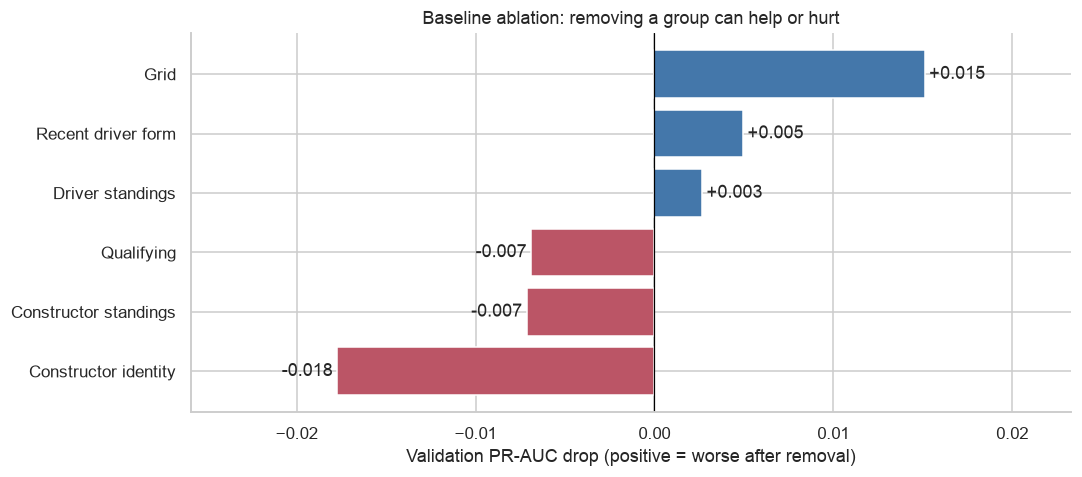

In [153]:
plot_data = ablation_results.drop(index="None (all features)").sort_values("PR-AUC drop")
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(plot_data.index, plot_data["PR-AUC drop"],
               color=np.where(plot_data["PR-AUC drop"].ge(0), "#4477AA", "#BB5566"))
ax.bar_label(bars, fmt="%+.3f", padding=3)
ax.axvline(0, color="black", linewidth=.8)
ax.set(title="Baseline ablation: removing a group can help or hurt",
       xlabel="Validation PR-AUC drop (positive = worse after removal)")
ax.margins(x=.25)
plt.tight_layout()
show_plot("experiments_baseline_ablation")

## Preprocessing order
Compare fill-then-scale and scale-then-fill with the same baseline features and fixed neural
configuration, duration and threshold. Missing indicators and categorical encoding stay the same.
Both settings learn from training only. These are two reported order results.

In [154]:
# Reuse the same model, epoch budget and threshold for a fair comparison.
def evaluate_preprocessing_order(label, inputs_train, inputs_val):
    assert X_train.columns.equals(inputs_train.columns)
    assert inputs_train.columns.equals(inputs_val.columns)
    fitted = train_copy(reference_model, inputs_train, y_train, reference_epochs)
    probabilities = fitted.predict_proba(inputs_val)[:, 1]
    return {
        "Order": label,
        "Training numeric SD": inputs_train[numeric_features].std(ddof=0).mean(),
        **evaluate_probabilities(y_validation, probabilities, reference_threshold)
    }

### Order 1 - Fill then scale
Fill missing numeric values with training medians, then standardize.
This is the baseline preprocessing order.

In [155]:
fill_then_scale_result = evaluate_preprocessing_order(
    "Fill then scale", X_train, X_validation)
display(pd.DataFrame([fill_then_scale_result]).set_index("Order").round(4))

,Training numeric SD,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
Order,,,,,,,,
Fill then scale,1.0,0.9309,0.7461,0.7179,0.6667,0.7778,0.7469,0.225


### Order 2 - Scale then fill
Learn scaling from observed training values, then fill the scaled gaps.
Keep the same features, missing indicators, model settings and threshold.

In [156]:
alternative_preprocessor = make_preprocessor(numeric_features, True, "Scale then fill")
alternative_train = alternative_preprocessor.fit_transform(baseline_raw.loc[train_mask])
alternative_val = alternative_preprocessor.transform(baseline_raw.loc[validation_mask])
scale_then_fill_result = evaluate_preprocessing_order(
    "Scale then fill", alternative_train, alternative_val)
display(pd.DataFrame([scale_then_fill_result]).set_index("Order").round(4))

,Training numeric SD,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
Order,,,,,,,,
Scale then fill,0.99,0.9309,0.7418,0.7194,0.6651,0.7833,0.7427,0.2258


### Compare the two orders
Choose using validation PR-AUC. Test data does not take part in this choice.

,Training numeric SD,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
Order,,,,,,,,
Fill then scale,1.00,0.9309,0.7461,0.7179,0.6667,0.7778,0.7469,0.2250
Scale then fill,0.99,0.9309,0.7418,0.7194,0.6651,0.7833,0.7427,0.2258


Preferred preprocessing order: Fill then scale


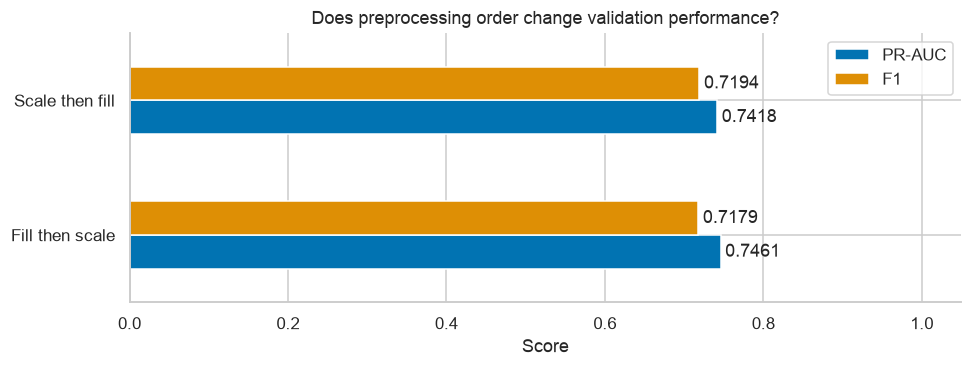

In [157]:
order_objects = {
    "Fill then scale": (baseline_preprocessor, X_train, X_validation),
    "Scale then fill": (alternative_preprocessor, alternative_train, alternative_val)
}
order_rows = [fill_then_scale_result, scale_then_fill_result]
preprocessing_results = pd.DataFrame(order_rows).set_index("Order")
preferred_order = preprocessing_results["PR-AUC"].idxmax()
display(preprocessing_results.round(4))
print("Preferred preprocessing order:", preferred_order)
save_table(preprocessing_results, "preprocessing_results", index=True)
ax = preprocessing_results[["PR-AUC", "F1"]].plot.barh(figsize=(9, 3.5), xlim=(0, 1.05))
ax.set(title="Does preprocessing order change validation performance?", xlabel="Score", ylabel="")
for bars in ax.containers: ax.bar_label(bars, fmt="%.4f", padding=3)
plt.tight_layout()
show_plot("experiments_preprocessing_order")

## Confirm the feature set across all three model families
Keep the original full set and original reduced set. Compare adding constructor form, Q1 pace,
or both to the reduced set. Each configuration keeps its fixed neural epoch budget; compare all eight configurations per version.
These five planned versions are a controlled comparison, not an exhaustive search.

In [158]:
feature_versions = {
    "Original full set": (numeric_features, True),
    "Original reduced set": (numeric_features, False),
    "Reduced + constructor form": (numeric_features + constructor_form_features, False),
    "Reduced + Q1 pace": (numeric_features + ["q1_relative_pct"], False),
    "Reduced + both candidates": (all_numeric_features, False)
}
version_preprocessors, version_models, feature_version_results = {}, {}, {}

def evaluate_feature_version(version):
    numeric_columns, include_constructor = feature_versions[version]
    raw = raw_inputs(model_features, numeric_columns, include_constructor)
    prep = make_preprocessor(numeric_columns, include_constructor, preferred_order)
    inputs_train = prep.fit_transform(raw.loc[train_mask])
    inputs_val = prep.transform(raw.loc[validation_mask])
    version_preprocessors[version] = prep
    rows = []
    # The eight configurations are defined separately in Stage 4.
    for attempt, base_model in model_objects.items():
        family = model_attempts.set_index("Attempt").loc[attempt, "Model"]
        fitted = train_copy(base_model, inputs_train, y_train, attempt_epochs[attempt])
        version_models[(version, attempt)] = fitted
        probabilities = fitted.predict_proba(inputs_val)[:, 1]
        threshold, _ = select_threshold(y_validation, probabilities)
        rows.append({
            "Feature set": version, "Model": family, "Attempt": attempt,
            "Inputs": inputs_train.shape[1], "Threshold": threshold,
            **evaluate_probabilities(y_validation, probabilities, threshold)
        })
    return pd.DataFrame(rows)

### Feature trial 1 - Original full set
Original numeric fields plus constructor identity. This is the full-input baseline.
Compare the same eight configurations using validation only.

In [159]:
feature_version_results["Original full set"] = evaluate_feature_version("Original full set")
display(feature_version_results["Original full set"].drop(columns="Feature set").round(4))

,Model,Attempt,Inputs,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
0,Logistic regression,Logistic C=1,46,0.38,0.9293,0.7246,0.7241,0.6651,0.7944,0.7264,0.2243
1,Random forest,Forest depth=8,46,0.44,0.9387,0.7443,0.7273,0.7213,0.7333,0.7457,0.2143
2,Neural network,Neural 32-16,46,0.43,0.9309,0.7461,0.7179,0.6667,0.7778,0.7469,0.2250
3,Logistic regression,Logistic C=0.1,46,0.39,0.9293,0.7211,0.7231,0.6714,0.7833,0.7229,0.2240
4,Logistic regression,Logistic C=10,46,0.32,0.9294,0.7247,0.7241,0.6504,0.8167,0.7264,0.2247
5,Random forest,Forest depth=5,46,0.44,0.9382,0.7366,0.7333,0.7333,0.7333,0.7382,0.2182
6,Random forest,Forest unrestricted,46,0.39,0.9367,0.7447,0.7240,0.6814,0.7722,0.7464,0.2158
7,Neural network,Neural 16,46,0.47,0.9319,0.7389,0.7243,0.7053,0.7444,0.7400,0.2223


### Feature trial 2 - Original reduced set
Remove constructor identity. Compare against the full baseline to test whether identity helps.
Compare the same eight configurations using validation only.

In [160]:
feature_version_results["Original reduced set"] = evaluate_feature_version("Original reduced set")
display(feature_version_results["Original reduced set"].drop(columns="Feature set").round(4))

,Model,Attempt,Inputs,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
0,Logistic regression,Logistic C=1,17,0.40,0.9295,0.7226,0.7202,0.6748,0.7722,0.7242,0.2225
1,Random forest,Forest depth=8,17,0.48,0.9391,0.7440,0.7207,0.7247,0.7167,0.7456,0.2105
2,Neural network,Neural 32-16,17,0.43,0.9376,0.7638,0.7335,0.6985,0.7722,0.7646,0.2119
3,Logistic regression,Logistic C=0.1,17,0.38,0.9292,0.7213,0.7198,0.6699,0.7778,0.7229,0.2230
4,Logistic regression,Logistic C=10,17,0.40,0.9297,0.7225,0.7202,0.6748,0.7722,0.7241,0.2224
5,Random forest,Forest depth=5,17,0.38,0.9384,0.7410,0.7316,0.6950,0.7722,0.7427,0.2124
6,Random forest,Forest unrestricted,17,0.34,0.9360,0.7370,0.7136,0.6514,0.7889,0.7387,0.2160
7,Neural network,Neural 16,17,0.39,0.9350,0.7334,0.7268,0.6779,0.7833,0.7346,0.2147


### Feature trial 3 - Reduced + constructor form
Add prior constructor performance to the reduced set. Test whether team history adds useful information.
Compare the same eight configurations using validation only.

In [161]:
feature_version_results["Reduced + constructor form"] = evaluate_feature_version("Reduced + constructor form")
display(feature_version_results["Reduced + constructor form"].drop(columns="Feature set").round(4))

,Model,Attempt,Inputs,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
0,Logistic regression,Logistic C=1,22,0.38,0.9307,0.7288,0.7194,0.6651,0.7833,0.7304,0.2212
1,Random forest,Forest depth=8,22,0.41,0.9393,0.7364,0.7317,0.7143,0.7500,0.7385,0.2115
2,Neural network,Neural 32-16,22,0.36,0.9365,0.7562,0.7226,0.6667,0.7889,0.7572,0.2137
3,Logistic regression,Logistic C=0.1,22,0.39,0.9303,0.7264,0.7249,0.6746,0.7833,0.7279,0.2218
4,Logistic regression,Logistic C=10,22,0.37,0.9308,0.7282,0.7208,0.6636,0.7889,0.7298,0.2212
5,Random forest,Forest depth=5,22,0.44,0.9393,0.7365,0.7298,0.7318,0.7278,0.7385,0.2134
6,Random forest,Forest unrestricted,22,0.27,0.9380,0.7266,0.7112,0.6234,0.8278,0.7305,0.2138
7,Neural network,Neural 16,22,0.40,0.9332,0.7321,0.7202,0.6748,0.7722,0.7336,0.2172


### Feature trial 4 - Reduced + Q1 pace
Add relative Q1 pace to the reduced set. Test whether recorded pace adds information beyond qualifying rank.
Compare the same eight configurations using validation only.

In [162]:
feature_version_results["Reduced + Q1 pace"] = evaluate_feature_version("Reduced + Q1 pace")
display(feature_version_results["Reduced + Q1 pace"].drop(columns="Feature set").round(4))

,Model,Attempt,Inputs,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
0,Logistic regression,Logistic C=1,19,0.31,0.9342,0.7254,0.7196,0.6502,0.8056,0.7270,0.2179
1,Random forest,Forest depth=8,19,0.38,0.9373,0.7410,0.7183,0.6715,0.7722,0.7428,0.2130
2,Neural network,Neural 32-16,19,0.42,0.9367,0.7537,0.7244,0.6866,0.7667,0.7545,0.2126
3,Logistic regression,Logistic C=0.1,19,0.37,0.9300,0.7211,0.7194,0.6651,0.7833,0.7227,0.2222
4,Logistic regression,Logistic C=10,19,0.32,0.9366,0.7277,0.7196,0.6502,0.8056,0.7293,0.2153
5,Random forest,Forest depth=5,19,0.41,0.9375,0.7438,0.7209,0.7037,0.7389,0.7453,0.2139
6,Random forest,Forest unrestricted,19,0.39,0.9349,0.7397,0.7150,0.6699,0.7667,0.7410,0.2176
7,Neural network,Neural 16,19,0.38,0.9351,0.7324,0.7259,0.6682,0.7944,0.7340,0.2162


### Feature trial 5 - Reduced + both candidates
Add both candidate groups. Check whether their combined information improves the reduced baseline.
Compare the same eight configurations using validation only.

In [163]:
feature_version_results["Reduced + both candidates"] = evaluate_feature_version("Reduced + both candidates")
display(feature_version_results["Reduced + both candidates"].drop(columns="Feature set").round(4))

,Model,Attempt,Inputs,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
0,Logistic regression,Logistic C=1,24,0.38,0.9353,0.7302,0.7212,0.6682,0.7833,0.7318,0.2167
1,Random forest,Forest depth=8,24,0.38,0.9392,0.7366,0.7240,0.6814,0.7722,0.7386,0.2123
2,Neural network,Neural 32-16,24,0.42,0.9358,0.7624,0.7253,0.6974,0.7556,0.7632,0.2140
3,Logistic regression,Logistic C=0.1,24,0.39,0.9311,0.7262,0.7231,0.6714,0.7833,0.7277,0.2210
4,Logistic regression,Logistic C=10,24,0.37,0.9375,0.7320,0.7208,0.6636,0.7889,0.7336,0.2142
5,Random forest,Forest depth=5,24,0.43,0.9391,0.7377,0.7273,0.7213,0.7333,0.7393,0.2151
6,Random forest,Forest unrestricted,24,0.41,0.9382,0.7384,0.7162,0.6853,0.7500,0.7406,0.2135
7,Neural network,Neural 16,24,0.39,0.9359,0.7485,0.7216,0.6731,0.7778,0.7495,0.2147


### Compare the feature trials
All 40 results are saved. The plot compares the best configuration in each family for each version;
the original three configurations also retain their explicit full-versus-reduced comparison.

**Original configurations: full versus reduced inputs**

,Feature set,Model,Attempt,Inputs,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
0,Original full set,Logistic regression,Logistic C=1,46,0.38,0.9293,0.7246,0.7241,0.6651,0.7944,0.7264,0.2243
1,Original full set,Random forest,Forest depth=8,46,0.44,0.9387,0.7443,0.7273,0.7213,0.7333,0.7457,0.2143
2,Original full set,Neural network,Neural 32-16,46,0.43,0.9309,0.7461,0.7179,0.6667,0.7778,0.7469,0.2250
8,Original reduced set,Logistic regression,Logistic C=1,17,0.40,0.9295,0.7226,0.7202,0.6748,0.7722,0.7242,0.2225
9,Original reduced set,Random forest,Forest depth=8,17,0.48,0.9391,0.7440,0.7207,0.7247,0.7167,0.7456,0.2105
10,Original reduced set,Neural network,Neural 32-16,17,0.43,0.9376,0.7638,0.7335,0.6985,0.7722,0.7646,0.2119


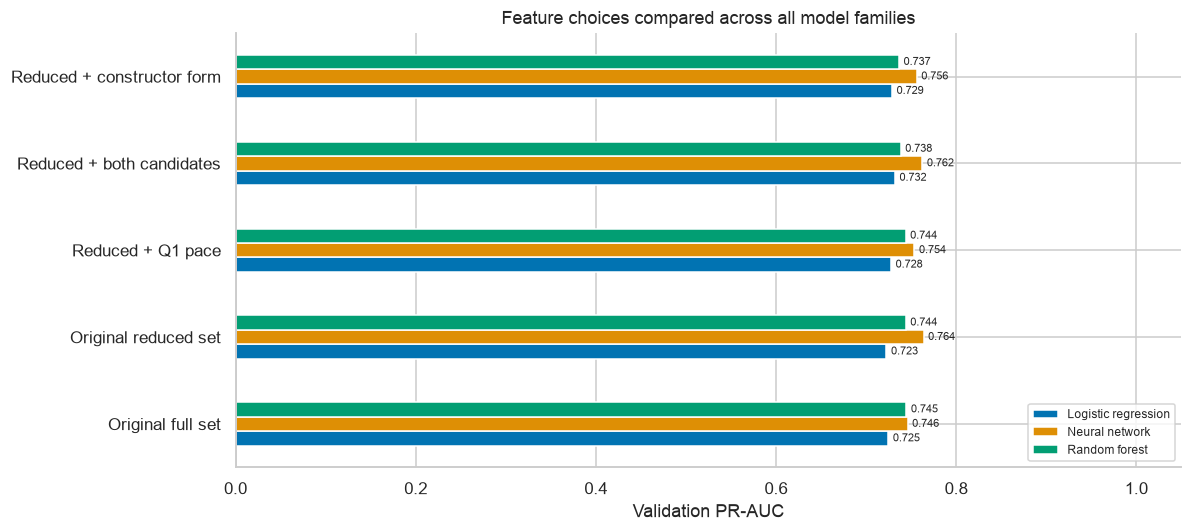

In [164]:
feature_confirmation = pd.concat(feature_version_results.values(), ignore_index=True)
confirmation_rows = feature_confirmation.to_dict("records")
assert len(feature_confirmation) == 40
assert feature_confirmation.groupby("Feature set")["Attempt"].nunique().eq(8).all()
save_table(feature_confirmation, "feature_confirmation")
# Preserve the original three configurations' full-versus-reduced comparison explicitly.
original_attempts = model_attempts.loc[model_attempts["Original configuration"], "Attempt"]
baseline_confirmation = feature_confirmation.loc[
    feature_confirmation["Attempt"].isin(original_attempts)
    & feature_confirmation["Feature set"].isin(["Original full set", "Original reduced set"])]
display(Markdown("**Original configurations: full versus reduced inputs**"))
display(baseline_confirmation.round(4))
save_table(baseline_confirmation, "original_feature_confirmation")
feature_family_comparison = (feature_confirmation.sort_values(["PR-AUC", "F1"], ascending=[False, False])
                            .drop_duplicates(["Feature set", "Model"]))
save_table(feature_family_comparison, "best_feature_family_comparison")
ax = feature_family_comparison.pivot(index="Feature set", columns="Model", values="PR-AUC").plot.barh(
    figsize=(11, 5), xlim=(0, 1.05))
ax.set(title="Feature choices compared across all model families", xlabel="Validation PR-AUC", ylabel="")
for bars in ax.containers: ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=7)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
show_plot("experiments_feature_confirmation")

In [165]:
# Choose among the planned versions by validation PR-AUC, then F1 and fewer inputs.
winning_row = feature_confirmation.sort_values(
    ["PR-AUC", "F1", "Inputs"], ascending=[False, False, True]).iloc[0]
chosen_feature_set = winning_row["Feature set"]
final_model_name = winning_row["Model"]
final_numeric_features, final_include_constructor = feature_versions[chosen_feature_set]
final_preprocessor = version_preprocessors[chosen_feature_set]
final_raw = raw_inputs(model_features, final_numeric_features, final_include_constructor)
X_train_final = final_preprocessor.transform(final_raw.loc[train_mask])
X_validation_final = final_preprocessor.transform(final_raw.loc[validation_mask])
final_feature_columns = X_train_final.columns.tolist()
selected_rows = feature_family_comparison.loc[
    feature_family_comparison["Feature set"].eq(chosen_feature_set)].set_index("Model")
final_models = {name: version_models[(chosen_feature_set, row["Attempt"])]
                for name, row in selected_rows.iterrows()}
model_epochs = {name: attempt_epochs[row["Attempt"]] for name, row in selected_rows.iterrows()}
final_thresholds = selected_rows["Threshold"]
final_model = final_models[final_model_name]
final_threshold = float(final_thresholds.loc[final_model_name])
final_pipeline = Pipeline([("preprocess", final_preprocessor), ("model", final_model)])
print("Selected feature set:", chosen_feature_set)
print("Selected model:", final_model_name, "| Threshold:", final_threshold)
print("Final encoded input count:", len(final_feature_columns))
best_by_version = feature_family_comparison.groupby("Feature set")["PR-AUC"].max()
display(Markdown(
    "**Feature evidence:** best validation PR-AUC by planned version: "
    + "; ".join(f"{name}: {value:.4f}" for name, value in best_by_version.items())
    + ". Keep the winning planned version; individual additions are not assumed to improve every family."))

Selected feature set: Original reduced set
Selected model: Neural network | Threshold: 0.43
Final encoded input count: 17


**Feature evidence:** best validation PR-AUC by planned version: Original full set: 0.7461; Original reduced set: 0.7638; Reduced + Q1 pace: 0.7537; Reduced + both candidates: 0.7624; Reduced + constructor form: 0.7562. Keep the winning planned version; individual additions are not assumed to improve every family.

## Contribution of groups in the selected setup
Recheck groups in the selected input representation. Keep settings, threshold and epoch budget fixed.
This describes conditional contribution: correlated groups may substitute for each other. These
diagnostics do not trigger an unplanned search or any selection using test performance.

In [166]:
selected_base = evaluate_probabilities(
    y_validation, final_model.predict_proba(X_validation_final)[:, 1], final_threshold)
final_ablation_rows = [{"Removed group": "None", "PR-AUC drop": 0., **selected_base}]
for group, raw_columns in raw_feature_groups.items():
    removed = encoded_group_columns(final_feature_columns, raw_columns)
    if not removed: continue
    fitted = train_copy(final_model, X_train_final.drop(columns=removed), y_train,
                        model_epochs[final_model_name])
    scores = evaluate_probabilities(
        y_validation, fitted.predict_proba(X_validation_final.drop(columns=removed))[:, 1],
        final_threshold)
    final_ablation_rows.append({
        "Removed group": group, "PR-AUC drop": selected_base["PR-AUC"]-scores["PR-AUC"], **scores})
final_ablation = pd.DataFrame(final_ablation_rows).set_index("Removed group")
display(final_ablation.round(4))
save_table(final_ablation, "final_group_ablation", index=True)

,PR-AUC drop,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
Removed group,,,,,,,,
None,0.0000,0.9376,0.7638,0.7335,0.6985,0.7722,0.7646,0.2119
Grid,0.0388,0.9308,0.7250,0.7062,0.6587,0.7611,0.7262,0.2212
Qualifying,0.0266,0.9333,0.7372,0.7098,0.6650,0.7611,0.7384,0.2173
Recent driver form,0.0012,0.9403,0.7626,0.7326,0.7062,0.7611,0.7635,0.2099
Driver standings,0.0370,0.9357,0.7268,0.7204,0.6979,0.7444,0.7305,0.2130
Constructor standings,0.0164,0.9362,0.7473,0.7200,0.6923,0.7500,0.7484,0.2128


In [167]:
final_training_validation_rows = []
for name, fitted in final_models.items():
    threshold = float(final_thresholds.loc[name])
    for dataset, inputs, target in [
        ("Training", X_train_final, y_train), ("Validation", X_validation_final, y_validation)
    ]:
        final_training_validation_rows.append({
            "Model": name, "Dataset": dataset, "Threshold": threshold,
            **evaluate_probabilities(target, fitted.predict_proba(inputs)[:, 1], threshold)})
final_modeling_report = pd.DataFrame(final_training_validation_rows)
display(final_modeling_report.round(4))
assert X_train_final.columns.equals(X_validation_final.columns)
assert np.isfinite(X_train_final.to_numpy(dtype=float)).all()
assert np.isfinite(X_validation_final.to_numpy(dtype=float)).all()
assert X_train_final.index.equals(y_train.index)
assert X_validation_final.index.equals(y_validation.index)
for fitted in final_models.values():
    assert list(fitted.feature_names_in_) == final_feature_columns

selection = {
    "seed": SEED, "feature_set": chosen_feature_set, "model": final_model_name,
    "numeric_features": final_numeric_features, "include_constructor": final_include_constructor,
    "input_columns": final_feature_columns, "preprocessing_order": preferred_order,
    "thresholds": final_thresholds.to_dict(),
    "primary_metric": "trapezoidal PR-AUC", "secondary_metric": "F1",
    "training": "2003-2018", "validation": "2019-2021", "test": "2022-2024",
    "test_used_for_selection": False, "test_previously_evaluated_in_earlier_notebook": True,
    "selected_configurations": selected_rows["Attempt"].to_dict(),
    "neural_epoch_budgets": model_epochs, "versions": versions
}
selection_path = output_folder / "frozen_selection.json"
selection_path.write_text(json.dumps(selection, indent=2))
selection_hash = hashlib.sha256(selection_path.read_bytes()).hexdigest()
display(Markdown(
    f"**Experiment decision:** {chosen_feature_set}; {preferred_order}; "
    f"{final_model_name}. Its validation PR-AUC is {winning_row['PR-AUC']:.4f}. "
    "These choices are fixed before the evaluation below. Candidate features are not assumed useful "
    "unless supported by these comparisons. Negative ablation drops are retained honestly."))

,Model,Dataset,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
0,Neural network,Training,0.43,0.9339,0.6980,0.6569,0.6393,0.6756,0.6987,0.2149
1,Neural network,Validation,0.43,0.9376,0.7638,0.7335,0.6985,0.7722,0.7646,0.2119
2,Random forest,Training,0.48,0.9558,0.7975,0.6961,0.7391,0.6578,0.7977,0.1846
3,Random forest,Validation,0.48,0.9391,0.7440,0.7207,0.7247,0.7167,0.7456,0.2105
4,Logistic regression,Training,0.40,0.9262,0.6754,0.6494,0.6301,0.6700,0.6760,0.2241
5,Logistic regression,Validation,0.40,0.9295,0.7226,0.7202,0.6748,0.7722,0.7242,0.2225


**Experiment decision:** Original reduced set; Fill then scale; Neural network. Its validation PR-AUC is 0.7638. These choices are fixed before the evaluation below. Candidate features are not assumed useful unless supported by these comparisons. Negative ablation drops are retained honestly.

## Final test evaluation - fixed choices
Complete model evaluation after the Stage 5 choices are fixed. The 2022-2024 period is held out
from fitting, but its scores were already viewed in the earlier notebook. It is **not a newly
untouched test set**; this limits the independence of the final performance estimate.

No test score selects features, configurations, epochs, preprocessing or thresholds in this revision.
Year-by-year results and error counts are diagnostics only. Rerunning these years cannot restore
their first-use status; a genuinely untouched evaluation would require additional unseen data.

In [168]:
X_test_final = final_preprocessor.transform(final_raw.loc[test_mask])
assert X_train_final.columns.equals(X_test_final.columns)
assert np.isfinite(X_test_final.to_numpy(dtype=float)).all()
test_rows, test_probabilities = [], {}
for name, fitted in final_models.items():
    probabilities = fitted.predict_proba(X_test_final)[:, 1]
    test_probabilities[name] = probabilities
    threshold = float(final_thresholds.loc[name])
    test_rows.append({"Model": name, "Dataset": "Test", "Threshold": threshold,
                      **evaluate_probabilities(y_test, probabilities, threshold)})
test_results = pd.DataFrame(test_rows)
complete_modeling_report = pd.concat([final_modeling_report, test_results], ignore_index=True)
display(complete_modeling_report.round(4))
save_table(complete_modeling_report, "complete_modeling_report")
assert hashlib.sha256(selection_path.read_bytes()).hexdigest() == selection_hash
test_predictions = test_probabilities[final_model_name] >= final_threshold

,Model,Dataset,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
0,Neural network,Training,0.43,0.9339,0.6980,0.6569,0.6393,0.6756,0.6987,0.2149
1,Neural network,Validation,0.43,0.9376,0.7638,0.7335,0.6985,0.7722,0.7646,0.2119
2,Random forest,Training,0.48,0.9558,0.7975,0.6961,0.7391,0.6578,0.7977,0.1846
3,Random forest,Validation,0.48,0.9391,0.7440,0.7207,0.7247,0.7167,0.7456,0.2105
4,Logistic regression,Training,0.40,0.9262,0.6754,0.6494,0.6301,0.6700,0.6760,0.2241
5,Logistic regression,Validation,0.40,0.9295,0.7226,0.7202,0.6748,0.7722,0.7242,0.2225
6,Neural network,Test,0.43,0.9375,0.7078,0.6730,0.6514,0.6961,0.7091,0.2186
7,Random forest,Test,0.48,0.9376,0.7114,0.6564,0.6882,0.6275,0.7127,0.2194
8,Logistic regression,Test,0.40,0.9345,0.7050,0.6523,0.6385,0.6667,0.7061,0.2233


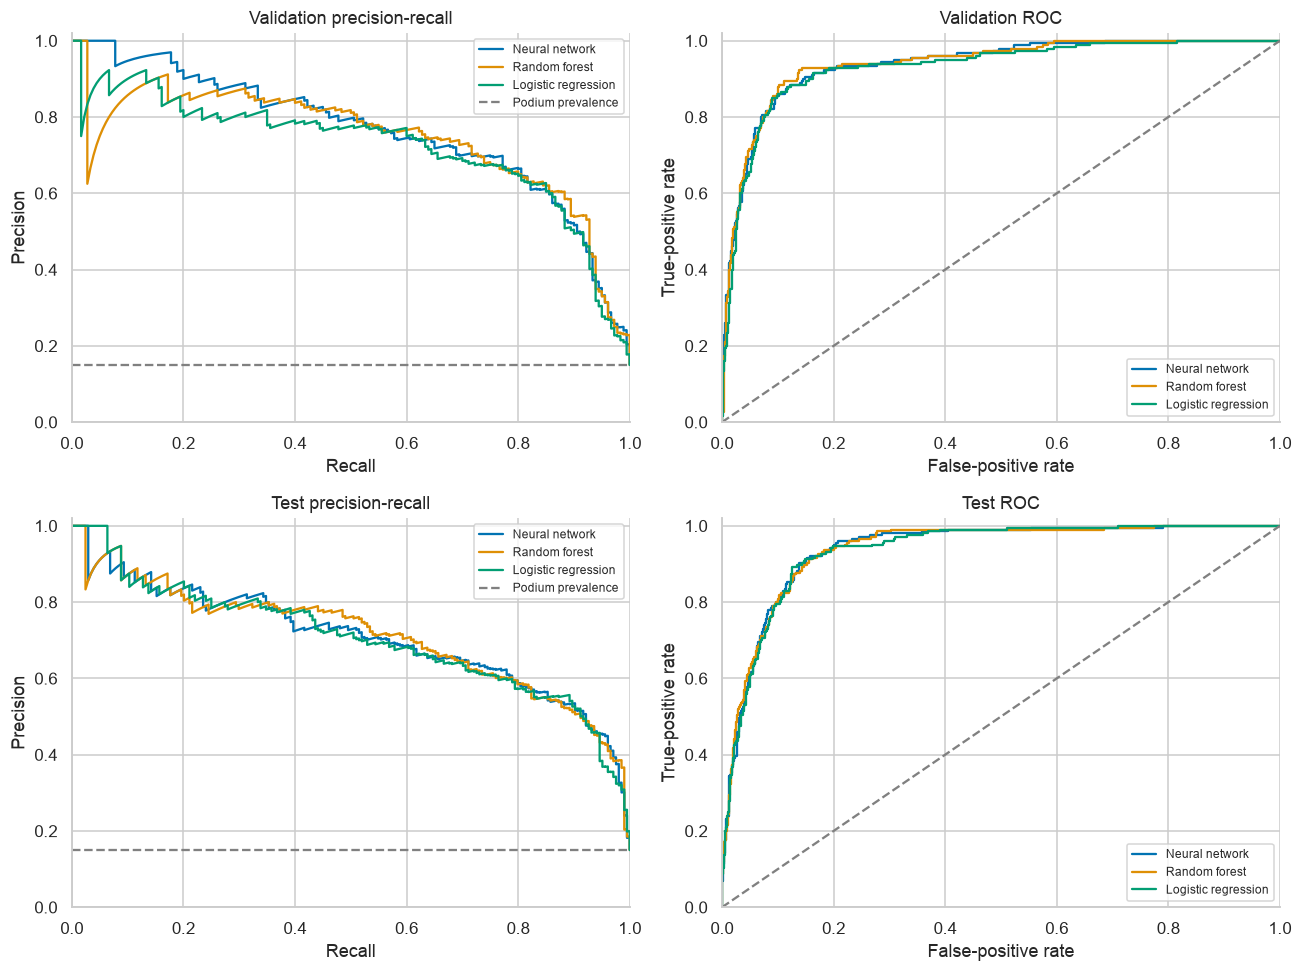

In [169]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, (label, inputs, target) in enumerate([
    ("Validation", X_validation_final, y_validation), ("Test", X_test_final, y_test)
]):
    for name, fitted in final_models.items():
        probability = fitted.predict_proba(inputs)[:, 1]
        precision, recall, _ = precision_recall_curve(target, probability)
        fpr, tpr, _ = roc_curve(target, probability)
        axes[row, 0].plot(recall, precision, label=name)
        axes[row, 1].plot(fpr, tpr, label=name)
    axes[row, 0].axhline(target.mean(), color="grey", linestyle="--", label="Podium prevalence")
    axes[row, 1].plot([0, 1], [0, 1], color="grey", linestyle="--")
    axes[row, 0].set(title=label+" precision-recall", xlabel="Recall", ylabel="Precision")
    axes[row, 1].set(title=label+" ROC", xlabel="False-positive rate", ylabel="True-positive rate")
    for ax in axes[row]:
        ax.set(xlim=(0, 1), ylim=(0, 1.02))
        ax.legend(fontsize=8)
plt.tight_layout()
show_plot("evaluation_validation_test_curves")

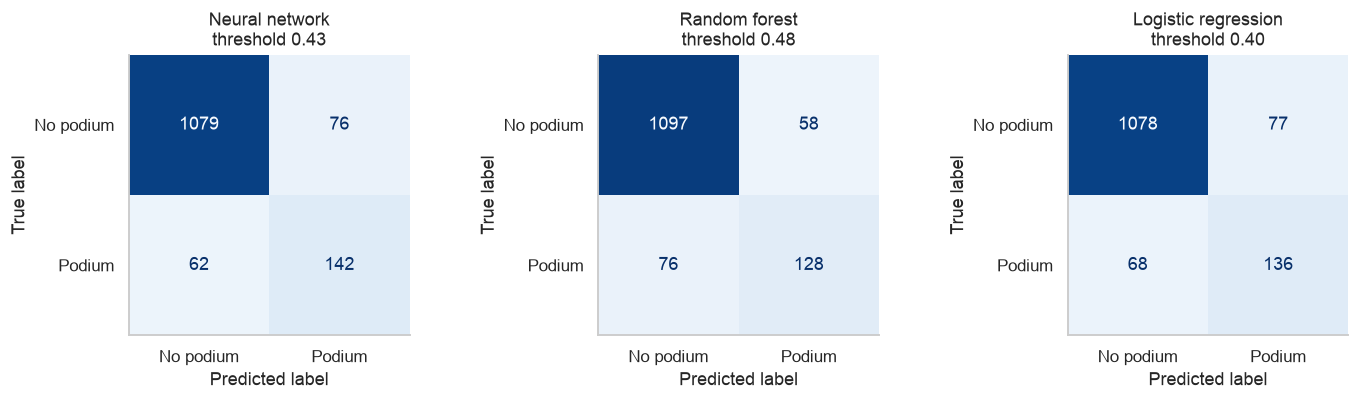

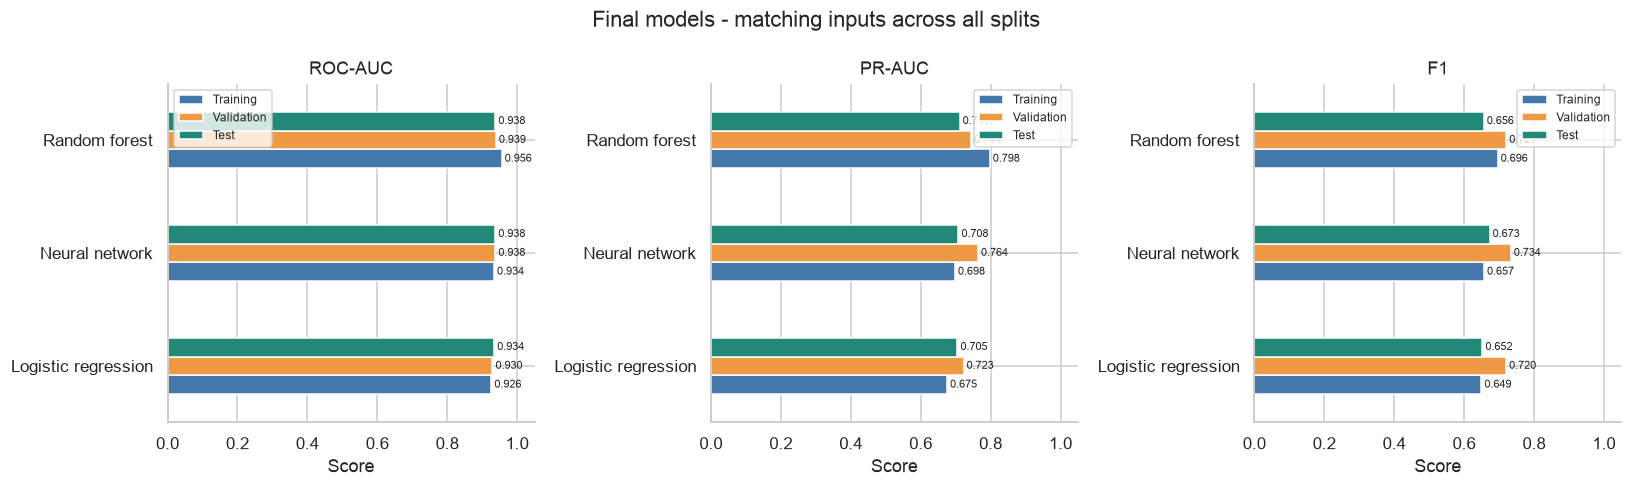

In [170]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, fitted) in zip(axes, final_models.items()):
    threshold = float(final_thresholds.loc[name])
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_probabilities[name] >= threshold, ax=ax, colorbar=False,
        display_labels=["No podium", "Podium"], cmap="Blues",
        im_kw={"vmin": 0, "vmax": len(y_test[y_test.eq(0)])})
    ax.set_title(name + f"\nthreshold {threshold:.2f}")
    ax.grid(False)
plt.tight_layout()
show_plot("evaluation_final_confusion_matrices")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, metric in zip(axes, ["ROC-AUC", "PR-AUC", "F1"]):
    chart = complete_modeling_report.pivot(index="Model", columns="Dataset", values=metric)
    chart[["Training", "Validation", "Test"]].plot.barh(
        ax=ax, color=["#4477AA", "#EE9944", "#228877"])
    ax.set(title=metric, xlabel="Score", ylabel="", xlim=(0, 1.05))
    for bars in ax.containers: ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=7)
    ax.legend(fontsize=8)
plt.suptitle("Final models - matching inputs across all splits")
plt.tight_layout()
show_plot("evaluation_final_model_comparison")

,Appearances,ROC-AUC,PR-AUC,F1,Precision,Recall,Average precision,Log loss
Year,,,,,,,,
2022,440,0.9436,0.6659,0.6528,0.6026,0.7121,0.6706,0.2097
2023,440,0.9342,0.7852,0.7213,0.7857,0.6667,0.7865,0.2162
2024,479,0.9294,0.6398,0.6538,0.6071,0.7083,0.6496,0.2288


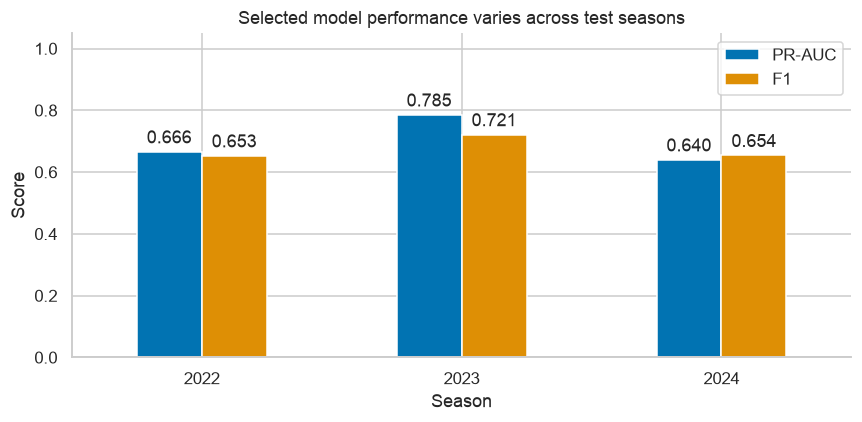

**Final result:** validation selected Neural network. Its test PR-AUC is 0.7078 and F1 is 0.6730. We retain that model even if another family scores higher on test. These are independent driver predictions; they need not produce exactly three podium labels per race. Temporal drift and unobserved race incidents limit generalization.

In [171]:
test_seasons = model_features.loc[test_mask, ["year", "raceId", "driverId", "podium"]].copy()
test_seasons["probability"] = test_probabilities[final_model_name]
year_rows = []
for year, group in test_seasons.groupby("year"):
    year_rows.append({"Year": int(year), "Appearances": len(group),
                     **evaluate_probabilities(group["podium"], group["probability"], final_threshold)})
test_year_results = pd.DataFrame(year_rows).set_index("Year")
display(test_year_results.round(4))
save_table(test_year_results, "test_metrics_by_year", index=True)
ax = test_year_results[["PR-AUC", "F1"]].plot.bar(figsize=(8, 4), rot=0, ylim=(0, 1.05))
ax.set(title="Selected model performance varies across test seasons", ylabel="Score", xlabel="Season")
for bars in ax.containers: ax.bar_label(bars, fmt="%.3f", padding=3)
plt.tight_layout()
show_plot("evaluation_test_seasons")
selected_test = test_results.set_index("Model").loc[final_model_name]
display(Markdown(
    f"**Final result:** validation selected {final_model_name}. Its test PR-AUC is "
    f"{selected_test['PR-AUC']:.4f} and F1 is {selected_test['F1']:.4f}. "
    "We retain that model even if another family scores higher on test. "
    "These are independent driver predictions; they need not produce exactly three podium labels per race. "
    "Temporal drift and unobserved race incidents limit generalization."))
save_table(test_seasons, "selected_test_predictions")

## Inference and saved fitted model
Accept engineered pre-race inputs in their original units. Missing fields use the fitted training
pipeline. Return the probability, fixed threshold, decision and unavailable inputs. No fitting occurs.
The saved bundle includes preprocessing, feature order and the selected model.

In [172]:
bundle = {
    "pipeline": final_pipeline, "numeric_features": final_numeric_features,
    "include_constructor": final_include_constructor, "threshold": final_threshold,
    "model_name": final_model_name, "feature_set": chosen_feature_set, "selection": selection
}
bundle_path = model_folder / "podium_companion.joblib"
joblib.dump(bundle, bundle_path, compress=3)

def predict_podium(record, fitted_bundle=None):
    fitted = bundle if fitted_bundle is None else fitted_bundle
    if not isinstance(record, dict):
        raise TypeError("Provide a dictionary of pre-race features.")
    numeric = fitted["numeric_features"]
    columns = numeric + (["constructorId"] if fitted["include_constructor"] else [])
    unexpected = set(record) - set(columns)
    if unexpected:
        raise ValueError("Unexpected or post-race fields: " + ", ".join(sorted(unexpected)))
    values = {}
    for feature in numeric:
        value = record.get(feature, np.nan)
        if isinstance(value, (list, tuple, dict, np.ndarray)):
            raise ValueError(feature + " must be a scalar.")
        if value is None or (isinstance(value, str) and value in ["", r"\N"]):
            value = np.nan
        try:
            value = float(value) if not pd.isna(value) else np.nan
        except (TypeError, ValueError):
            raise ValueError(feature + " must be numeric or missing.")
        if np.isinf(value):
            raise ValueError(feature + " cannot be infinite.")
        values[feature] = value
    if pd.notna(values["grid_for_analysis"]) and values["grid_for_analysis"] <= 0:
        values["grid_for_analysis"] = np.nan
    for feature in ["recent_podium_rate", "constructor_recent_podium_rate"]:
        if feature in values and pd.notna(values[feature]) and not 0 <= values[feature] <= 100:
            raise ValueError(feature + " must be a percentage in [0, 100].")
    for feature in ["past_races_used", "constructor_past_races_used"]:
        if feature in values and pd.notna(values[feature]) and not 0 <= values[feature] <= 5:
            raise ValueError(feature + " must be in [0, 5].")
    if fitted["include_constructor"]:
        category = record.get("constructorId")
        if category is None or pd.isna(category) or str(category) in ["", r"\N"]:
            category = "Unknown"
        elif isinstance(category, (int, float, np.integer, np.floating)):
            category = str(int(category)) if float(category).is_integer() else str(category)
        values["constructorId"] = str(category)
    missing = [feature for feature in numeric if pd.isna(values[feature])]
    if fitted["include_constructor"] and values["constructorId"] == "Unknown":
        missing.append("constructorId")
    inputs = pd.DataFrame([values], columns=columns)
    probability = float(fitted["pipeline"].predict_proba(inputs)[0, 1])
    return {
        "podium_probability": probability,
        "prediction": "Podium" if probability >= fitted["threshold"] else "No podium",
        "threshold": float(fitted["threshold"]),
        "filled_features": ", ".join(missing) or "None"
    }

In [173]:
# A complete validation example, selected without using its outcome.
complete_examples = final_raw.loc[validation_mask].dropna()
example_index = complete_examples.index[0]
complete_record = complete_examples.iloc[0].to_dict()
partial_record = complete_record.copy()
partial_record.pop("qualifying_position")
partial_record.pop("recent_avg_finish")
inference_examples = pd.DataFrame({
    "Complete record": predict_podium(complete_record),
    "Partially missing record": predict_podium(partial_record)
}).T
display(pd.DataFrame({"Complete": complete_record, "Partially missing": partial_record}))
display(inference_examples)
save_table(inference_examples, "inference_examples", index=True)

restored_bundle = joblib.load(bundle_path)
np.testing.assert_allclose(
    predict_podium(complete_record, restored_bundle)["podium_probability"],
    final_model.predict_proba(X_validation_final.loc[[example_index]])[0, 1])
assert predict_podium({**complete_record, "grid_for_analysis": 0}) == predict_podium(
    {**complete_record, "grid_for_analysis": None})
for marker in [None, np.nan, pd.NA, "", r"\N"]:
    assert np.isfinite(predict_podium({**complete_record, "qualifying_position": marker})["podium_probability"])
if final_include_constructor:
    unseen_record = {**complete_record, "constructorId": "Unseen example constructor"}
    assert np.isfinite(predict_podium(unseen_record)["podium_probability"])
try:
    predict_podium({**complete_record, "positionOrder": 1})
except ValueError:
    print("PASS: outcome fields rejected.")
else:
    raise AssertionError("Inference accepted a post-race outcome.")
print("PASS: saved-model reload, complete/partial inputs, missing markers and zero-grid handling.")

,Complete,Partially missing
grid_for_analysis,3.0,3.0
qualifying_position,3.0,NaN
recent_podium_rate,80.0,80.0
recent_avg_finish,2.2,NaN
past_races_used,5.0,5.0
driver_points_before_race,18.0,18.0
driver_standing_before_race,2.0,2.0
constructor_points_before_race,44.0,44.0
constructor_standing_before_race,1.0,1.0


,podium_probability,prediction,threshold,filled_features
Complete record,0.685997,Podium,0.43,None
Partially missing record,0.133267,No podium,0.43,"qualifying_position, recent_avg_finish"


PASS: outcome fields rejected.
PASS: saved-model reload, complete/partial inputs, missing markers and zero-grid handling.


Filling permits a prediction; it does not recover unknown true values. These examples check the
interface, not accuracy on new data. For a new race, callers must supply history computed strictly
before that race. The function does not fetch live data.

# Stage 6 - Model Explainability
Explain the selected final model. Permutation importance measures validation ranking changes.
SHAP describes contributions to predicted podium probability. LIME fits a local approximation.

Keep the lab's SHAP summary/force and LIME display, and add grouped importance and a waterfall.
Explanations show model reliance, not causal effects. Correlated inputs can share importance.

,Feature,PR-AUC decrease,Variation
1,qualifying_position,0.1531,0.0216
0,grid_for_analysis,0.1320,0.0237
2,recent_podium_rate,0.0853,0.0293
6,driver_standing_before_race,0.0390,0.0167
7,constructor_points_before_race,0.0355,0.0118
5,driver_points_before_race,0.0345,0.0049
3,recent_avg_finish,0.0219,0.0057
4,past_races_used,0.0182,0.0169
8,constructor_standing_before_race,0.0170,0.0101


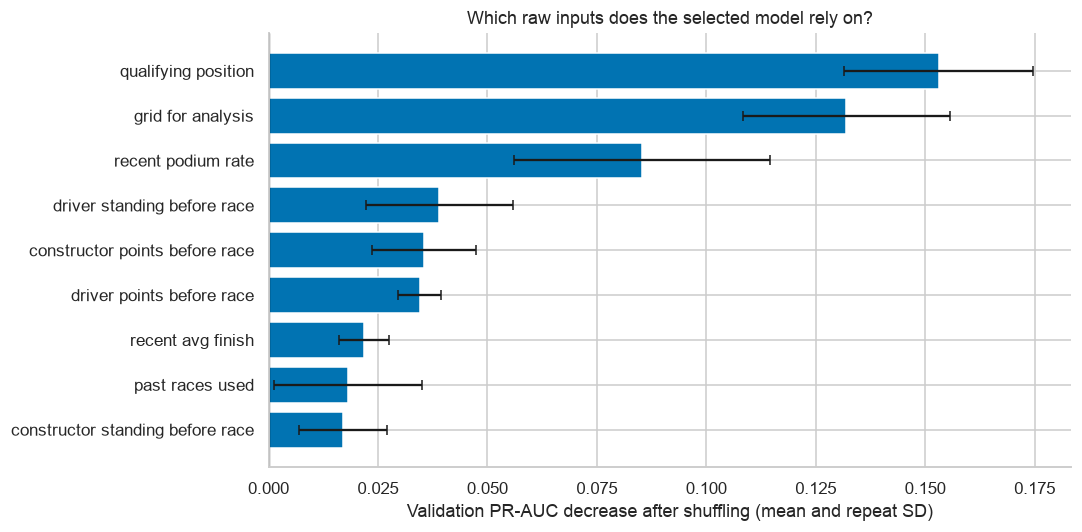

In [174]:
def permutation_score(estimator, inputs, target):
    return evaluate_probabilities(target, estimator.predict_proba(inputs)[:, 1])["PR-AUC"]

permutation_result = permutation_importance(
    final_pipeline, final_raw.loc[validation_mask], y_validation,
    scoring=permutation_score, n_repeats=10, random_state=SEED, n_jobs=1)
permutation_summary = pd.DataFrame({
    "Feature": final_raw.columns, "PR-AUC decrease": permutation_result.importances_mean,
    "Variation": permutation_result.importances_std
}).sort_values("PR-AUC decrease", ascending=False)
display(permutation_summary.round(4))
save_table(permutation_summary, "permutation_summary")
top = permutation_summary.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top["Feature"].str.replace("_", " "), top["PR-AUC decrease"],
        xerr=top["Variation"], capsize=3)
ax.axvline(0, color="black", linewidth=.8)
ax.set(title="Which raw inputs does the selected model rely on?",
       xlabel="Validation PR-AUC decrease after shuffling (mean and repeat SD)")
plt.tight_layout()
show_plot("xai_permutation_importance")

In [175]:
# Restore numeric units for labels, while the prediction wrapper restores model scaling.
final_scaler = final_preprocessor.named_transformers_["numeric"].named_steps["scale"]
X_train_xai = X_train_final.astype(float).copy()
X_validation_xai = X_validation_final.astype(float).copy()
X_train_xai[final_numeric_features] = final_scaler.inverse_transform(X_train_final[final_numeric_features])
X_validation_xai[final_numeric_features] = final_scaler.inverse_transform(X_validation_final[final_numeric_features])

def predict_for_xai(values):
    inputs = pd.DataFrame(values, columns=final_feature_columns).copy()
    inputs[final_numeric_features] = final_scaler.transform(inputs[final_numeric_features])
    return final_model.predict_proba(inputs)

np.testing.assert_allclose(predict_for_xai(X_validation_xai),
                           final_model.predict_proba(X_validation_final), rtol=1e-10, atol=1e-12)
raw_validation = final_raw.loc[validation_mask]
probability_series = pd.Series(final_model.predict_proba(X_validation_final)[:, 1],
                               index=X_validation_final.index)
complete_indices = raw_validation.dropna().index
positive_index = probability_series.loc[complete_indices].idxmax()
# Retain the original sample's first appearance, rather than hiding its previous weak local fit.
legacy_index = X_validation_xai.sample(n=min(100, len(X_validation_xai)), random_state=SEED).index[0]
random_indices = X_validation_xai.sample(n=min(100, len(X_validation_xai)), random_state=SEED).index.tolist()
explanation_indices = list(dict.fromkeys([positive_index, legacy_index] + random_indices))[:100]
explain_data = X_validation_xai.loc[explanation_indices]
background = X_train_xai.sample(n=min(50, len(X_train_xai)), random_state=SEED)
np.random.seed(SEED)
shap_explainer = shap.KernelExplainer(lambda values: predict_for_xai(values)[:, 1],
                                     background, link="identity")
shap_values = np.asarray(shap_explainer.shap_values(explain_data, nsamples=300, l1_reg=0.0, silent=True))
shap_base = float(shap_explainer.expected_value)
np.testing.assert_allclose(shap_base + shap_values.sum(axis=1),
                           predict_for_xai(explain_data)[:, 1], atol=1e-6)
print("PASS: readable inputs preserve predictions and SHAP contributions reconstruct probabilities.")

PASS: readable inputs preserve predictions and SHAP contributions reconstruct probabilities.


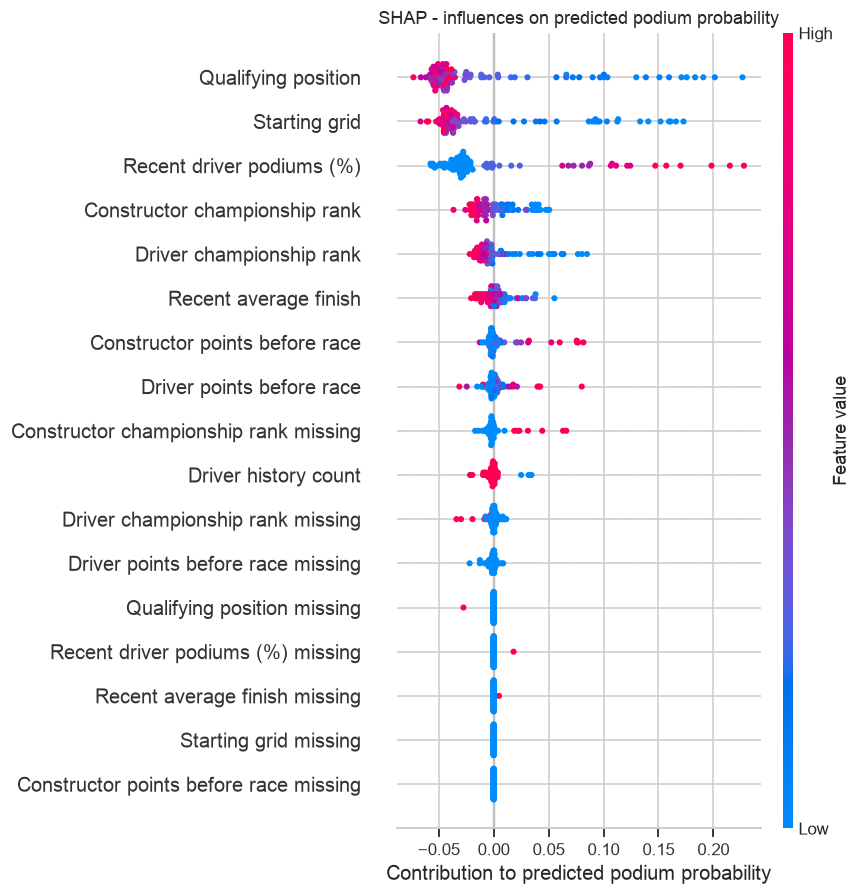

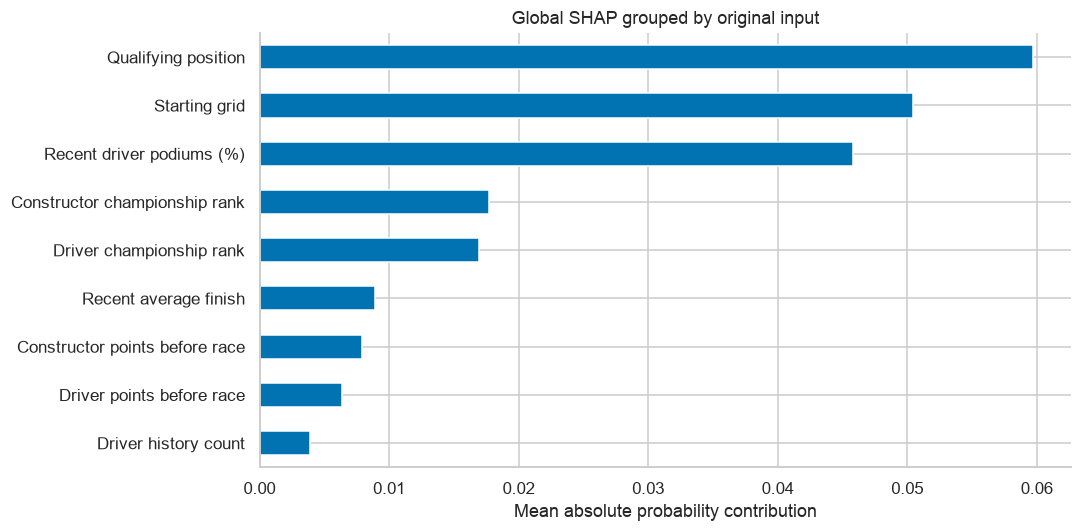

In [176]:
short_names = {
    "grid_for_analysis": "Starting grid", "qualifying_position": "Qualifying position",
    "recent_podium_rate": "Recent driver podiums (%)", "recent_avg_finish": "Recent average finish",
    "past_races_used": "Driver history count", "driver_points_before_race": "Driver points before race",
    "driver_standing_before_race": "Driver championship rank",
    "constructor_points_before_race": "Constructor points before race",
    "constructor_standing_before_race": "Constructor championship rank",
    "constructor_recent_podium_rate": "Recent constructor podiums (%)",
    "constructor_recent_avg_finish": "Constructor recent average finish",
    "constructor_past_races_used": "Constructor history count",
    "q1_relative_pct": "Q1 time above fastest (%)", "constructorId": "Constructor identity"
}
def feature_label(column):
    if column.startswith("missingindicator_"):
        return short_names.get(column.removeprefix("missingindicator_"), column) + " missing"
    if column.startswith("constructorId_"):
        identifier = column.removeprefix("constructorId_")
        names = constructors_clean.set_index("constructorId")["name"].astype(str).to_dict()
        return "Constructor: " + names.get(int(identifier), identifier)
    return short_names.get(column, column.replace("_", " "))

display_labels = [feature_label(column) for column in final_feature_columns]
shap.summary_plot(shap_values, explain_data, feature_names=display_labels,
                  max_display=17, show=False, rng=np.random.default_rng(SEED))
plt.title("SHAP - influences on predicted podium probability")
plt.xlabel("Contribution to predicted podium probability")
plt.tight_layout()
show_plot("xai_shap_summary")

raw_of_encoded = [
    column.removeprefix("missingindicator_") if column.startswith("missingindicator_")
    else "constructorId" if column.startswith("constructorId_") else column
    for column in final_feature_columns
]
grouped_shap_values = pd.DataFrame({
    feature: shap_values[:, np.array(raw_of_encoded) == feature].sum(axis=1)
    for feature in final_raw.columns
}, index=explain_data.index)
grouped_shap = grouped_shap_values.abs().mean().sort_values(ascending=False).rename("Mean absolute SHAP")
save_table(grouped_shap.to_frame(), "grouped_SHAP", index=True)
ax = grouped_shap.head(12).iloc[::-1].rename(index=lambda s: short_names.get(s, s)).plot.barh(figsize=(10, 5))
ax.set(title="Global SHAP grouped by original input", xlabel="Mean absolute probability contribution", ylabel="")
plt.tight_layout()
show_plot("xai_shap_grouped")

## Two local examples
Explain a complete validation appearance with high predicted probability, selected without its true
label, and the original sample's first appearance. The earlier notebook reported weak LIME fit
(R² approximately 0.293) for that original appearance. Re-evaluate it honestly with the new model.

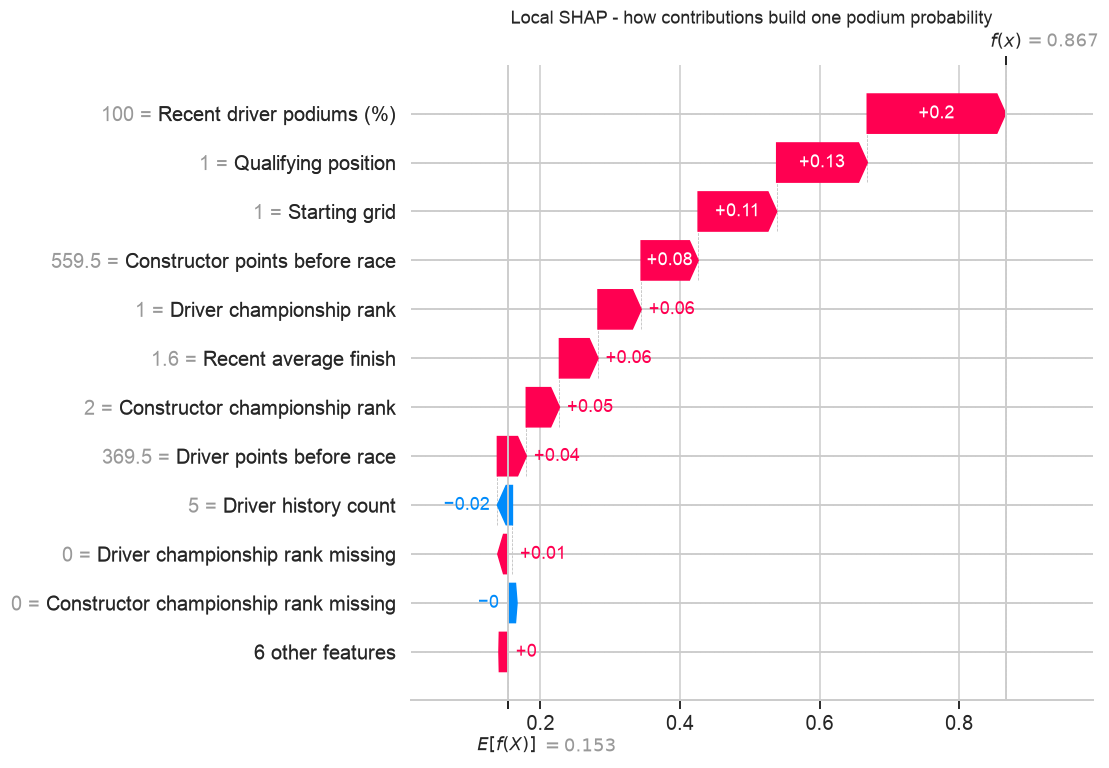

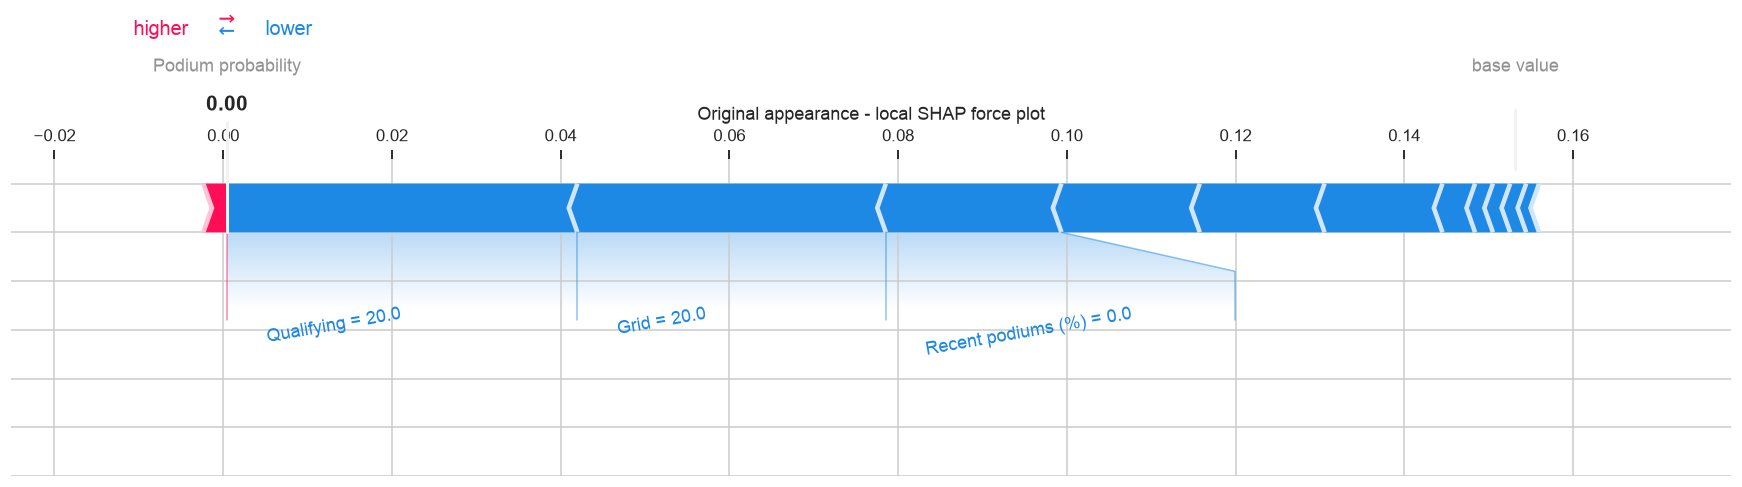

,raceId,driverId,year,forename,surname
0,1073,830,2021,Max,Verstappen
1,1072,853,2021,Nikita,Mazepin


In [177]:
primary_position = explain_data.index.get_loc(positive_index)
legacy_position = explain_data.index.get_loc(legacy_index)
local_shap = shap.Explanation(
    values=shap_values[primary_position], base_values=shap_base,
    data=explain_data.iloc[primary_position].to_numpy(), feature_names=display_labels)
shap.plots.waterfall(local_shap, max_display=12, show=False)
plt.title("Local SHAP - how contributions build one podium probability")
show_plot("xai_local_waterfall")

shap.force_plot(
    shap_base, shap_values[legacy_position], explain_data.iloc[legacy_position],
    feature_names=[
        {"grid_for_analysis": "Grid", "qualifying_position": "Qualifying",
         "recent_podium_rate": "Recent podiums (%)", "recent_avg_finish": "Avg finish",
         "driver_standing_before_race": "Driver rank",
         "constructor_standing_before_race": "Team rank"}.get(column, feature_label(column))
        for column in final_feature_columns],
    out_names="Podium probability", matplotlib=True,
    figsize=(16, 5), text_rotation=10, contribution_threshold=.17, show=False)
plt.title("Original appearance - local SHAP force plot")
plt.tight_layout()
show_plot("xai_original_appearance_force")

local_records = model_features.loc[[positive_index, legacy_index], ["raceId", "driverId", "year"]].copy()
local_records = local_records.merge(
    drivers_clean[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one")
display(local_records)

## LIME in the lab style
Explain the same two appearances. Numeric values use original units; missing flags are categorical.
If constructor identity is selected, LIME perturbs the whole category rather than separate one-hot
columns. Reconstruct raw gaps before using the fitted pipeline. This preserves the model prediction.

In [178]:
lime_flag_columns = [c for c in final_feature_columns if c.startswith("missingindicator_")]
lime_columns = final_numeric_features + lime_flag_columns + (["constructorId"] if final_include_constructor else [])
lime_medians = final_raw.loc[train_mask, final_numeric_features].median()
constructor_categories = (baseline_raw.loc[train_mask, "constructorId"].unique().tolist()
                          if final_include_constructor else [])
if final_include_constructor:
    constructor_categories = sorted(constructor_categories) + ["Unknown"]
constructor_map = {value: index for index, value in enumerate(constructor_categories)}

def lime_array(frame):
    values = frame[final_numeric_features].fillna(lime_medians).to_numpy(dtype=float)
    if lime_flag_columns:
        flags = np.column_stack([frame[c.removeprefix("missingindicator_")].isna().astype(int)
                                 for c in lime_flag_columns])
        values = np.column_stack([values, flags])
    if final_include_constructor:
        categories = frame["constructorId"].map(constructor_map).fillna(len(constructor_categories)-1)
        values = np.column_stack([values, categories])
    return values

def lime_predict(values):
    values = np.asarray(values)
    frame = pd.DataFrame(values[:, :len(final_numeric_features)], columns=final_numeric_features)
    for position, column in enumerate(lime_flag_columns, start=len(final_numeric_features)):
        frame.loc[values[:, position] >= .5, column.removeprefix("missingindicator_")] = np.nan
    if final_include_constructor:
        category_indices = np.rint(values[:, -1]).astype(int).clip(0, len(constructor_categories)-1)
        frame["constructorId"] = [constructor_categories[i] for i in category_indices]
    return final_pipeline.predict_proba(frame)

lime_categorical = list(range(len(final_numeric_features), len(lime_columns)))
lime_category_names = {i: ["Observed", "Missing"] for i in
                       range(len(final_numeric_features), len(final_numeric_features)+len(lime_flag_columns))}
if final_include_constructor:
    names_by_id = constructors_clean.set_index("constructorId")["name"].to_dict()
    lime_category_names[len(lime_columns)-1] = [
        names_by_id.get(int(value), value) if value != "Unknown" else "Unknown"
        for value in constructor_categories]
lime_explainer = LimeTabularExplainer(
    training_data=lime_array(final_raw.loc[train_mask]), feature_names=[feature_label(c) for c in lime_columns],
    class_names=["No podium", "Podium"], categorical_features=lime_categorical,
    categorical_names=lime_category_names, mode="classification", discretize_continuous=True,
    random_state=SEED)

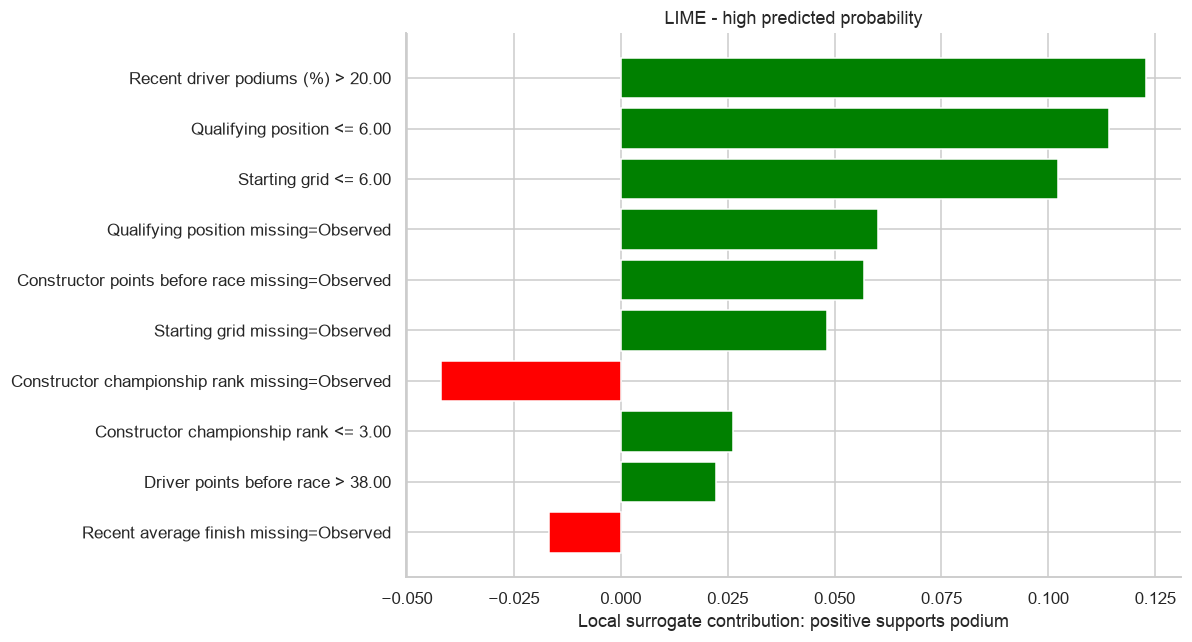

**High predicted probability - SHAP/LIME direction comparison**

,SHAP contribution,LIME local weight,Same direction
recent_podium_rate,0.1983,0.1229,True
qualifying_position,0.1298,0.1745,True
grid_for_analysis,0.1126,0.1505,True
constructor_points_before_race,0.0817,0.0570,True
recent_avg_finish,0.0553,-0.0168,False
constructor_standing_before_race,0.0452,-0.0159,False
driver_points_before_race,0.0420,0.0223,True


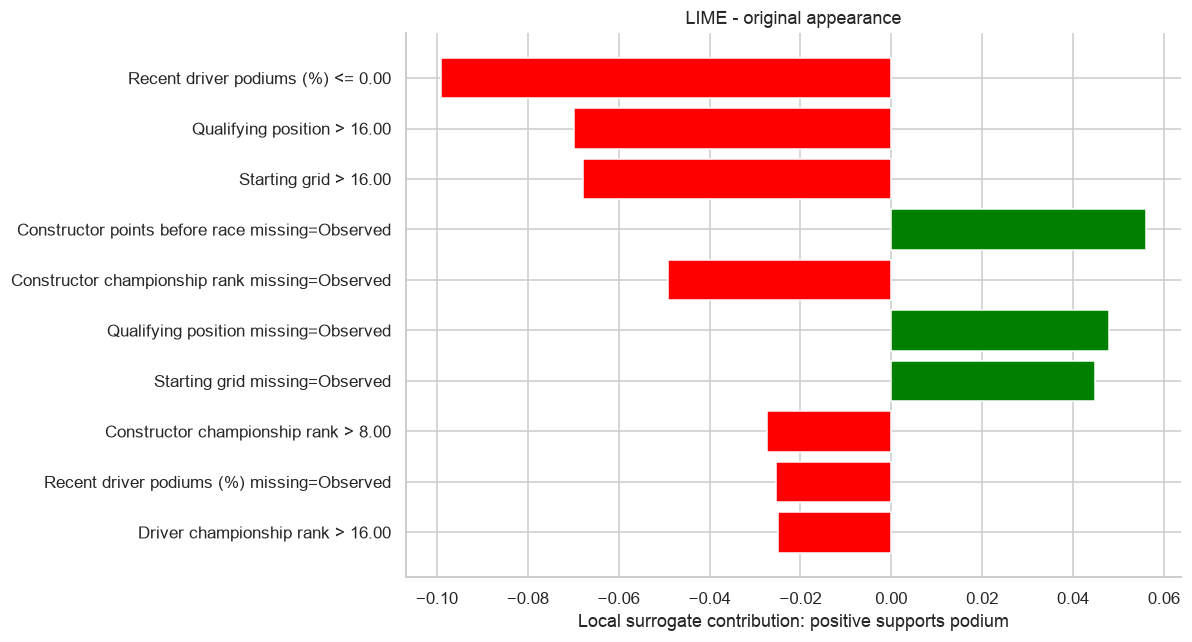

**Original appearance - SHAP/LIME direction comparison**

,SHAP contribution,LIME local weight,Same direction
qualifying_position,-0.0415,-0.0219,True
grid_for_analysis,-0.0366,-0.0229,True
recent_podium_rate,-0.0208,-0.1245,True
constructor_standing_before_race,-0.0187,-0.0763,True
driver_standing_before_race,-0.0160,-0.0250,True
constructor_points_before_race,0.0028,0.0561,True


,Example,raceId,driverId,Driver,Race,Year,Model probability,LIME approximation,Absolute approximation error,LIME R2,SHAP baseline,Actual podium,Top positive SHAP,Top negative SHAP
0,High predicted probability,1073,830,Max Verstappen,Abu Dhabi Grand Prix,2021,0.866700,0.384345,0.482355,0.489453,0.153177,1,"recent_podium_rate, qualifying_position, grid_...",past_races_used
1,Original appearance,1072,853,Nikita Mazepin,Saudi Arabian Grand Prix,2021,0.000454,-0.080305,0.080759,0.282243,0.153177,0,constructor_points_before_race,"qualifying_position, grid_for_analysis, recent..."


In [179]:
local_explanations, local_comparisons = [], []
for label, appearance_index in [("High predicted probability", positive_index), ("Original appearance", legacy_index)]:
    instance = lime_array(raw_validation.loc[[appearance_index]])[0]
    expected = float(probability_series.loc[appearance_index])
    np.testing.assert_allclose(lime_predict(instance[None, :])[0, 1], expected, atol=1e-10)
    lime_explainer.random_state = np.random.RandomState(SEED)
    lime_explanation = lime_explainer.explain_instance(
        instance, lime_predict, labels=(1,), num_features=10, num_samples=5000)
    if appearance_index == positive_index:
        display(HTML(lime_explanation.as_html(labels=(1,), show_table=True)))
    figure = lime_explanation.as_pyplot_figure(label=1)
    figure.set_size_inches(11, 6)
    figure.axes[0].set_title("LIME - " + label.lower())
    figure.axes[0].set_xlabel("Local surrogate contribution: positive supports podium")
    figure.tight_layout()
    show_plot("xai_lime_" + ("high_probability" if appearance_index == positive_index else "original"))

    lime_weights = {}
    for feature_index, weight in lime_explanation.local_exp[1]:
        feature = lime_columns[feature_index].removeprefix("missingindicator_")
        lime_weights[feature] = lime_weights.get(feature, 0.) + float(weight)
    shap_row = grouped_shap_values.loc[appearance_index]
    comparison = pd.DataFrame({
        "SHAP contribution": shap_row,
        "LIME local weight": pd.Series(lime_weights)
    }).dropna()
    comparison["Same direction"] = np.sign(comparison["SHAP contribution"]) == np.sign(comparison["LIME local weight"])
    comparison = comparison.reindex(comparison["SHAP contribution"].abs().sort_values(ascending=False).index)
    display(Markdown("**" + label + " - SHAP/LIME direction comparison**"))
    display(comparison.round(4))
    local_comparisons.append(comparison.assign(Example=label).reset_index(names="Feature"))
    row = model_features.loc[appearance_index]
    driver = drivers_clean.set_index("driverId").loc[row["driverId"]]
    race = races_clean.set_index("raceId").loc[row["raceId"]]
    local_explanations.append({
        "Example": label, "raceId": int(row["raceId"]), "driverId": int(row["driverId"]),
        "Driver": driver["forename"] + " " + driver["surname"], "Race": race["name"], "Year": int(row["year"]),
        "Model probability": expected, "LIME approximation": float(lime_explanation.local_pred[0]),
        "Absolute approximation error": abs(expected-float(lime_explanation.local_pred[0])),
        "LIME R2": float(lime_explanation.score), "SHAP baseline": shap_base,
        "Actual podium": int(row["podium"]),
        "Top positive SHAP": ", ".join(shap_row.loc[shap_row.gt(0)].sort_values(ascending=False).head(3).index),
        "Top negative SHAP": ", ".join(shap_row.loc[shap_row.lt(0)].sort_values().head(3).index)
    })
local_explanation_summary = pd.DataFrame(local_explanations)
display(local_explanation_summary)
save_table(local_explanation_summary, "local_explanation_summary")
save_table(pd.concat(local_comparisons, ignore_index=True), "local_SHAP_LIME_comparison")

## LIME locality check
The lab's discretized setup can fit a high-probability example poorly. Compare three continuous
setups that sample around the actual appearance, with explicitly reported kernel widths.
Keep the lab results. Check both local R² and point error; improving one does not establish the other.

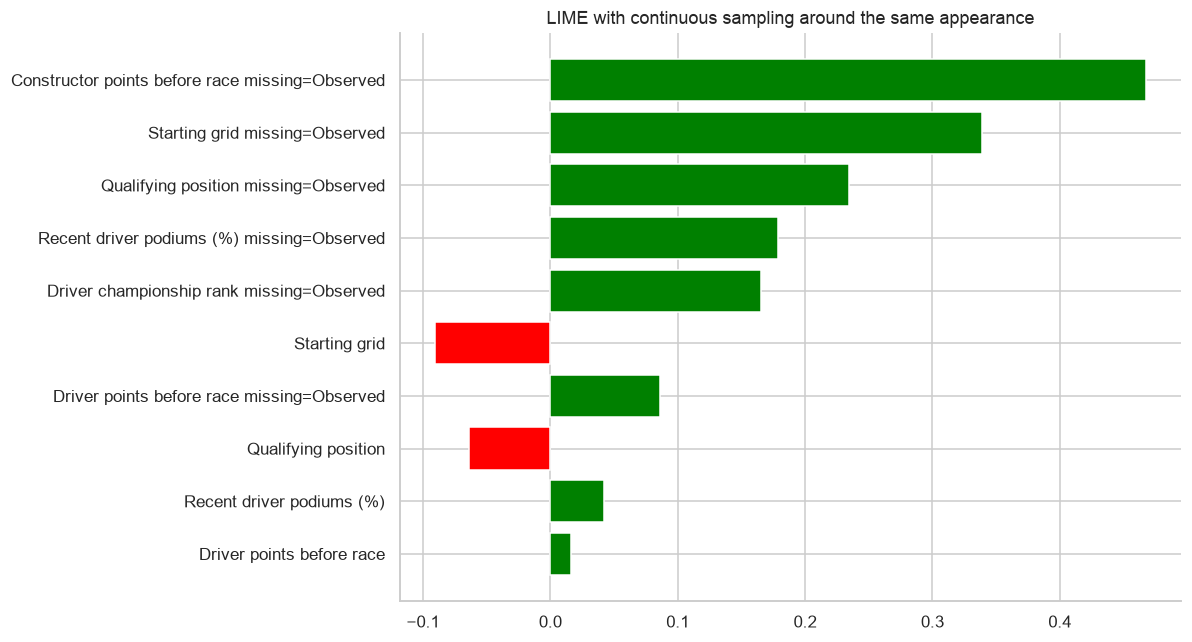

,Example,Setup,Model probability,LIME approximation,Absolute approximation error,LIME R2
0,High predicted probability,Lab discretized,0.8667,0.3843,0.4824,0.4895
1,Original appearance,Lab discretized,0.0005,-0.0803,0.0808,0.2822
2,High predicted probability,Continuous local; width 1.5,0.8667,0.8078,0.0589,0.4313
3,Original appearance,Continuous local; width 1.5,0.0005,0.0014,0.0009,0.2312
4,High predicted probability,Continuous local; width 2.25,0.8667,0.7974,0.0693,0.4190
5,Original appearance,Continuous local; width 2.25,0.0005,0.0016,0.0012,0.2089
6,High predicted probability,Continuous local; width 3.0,0.8667,0.7929,0.0738,0.4140
7,Original appearance,Continuous local; width 3.0,0.0005,0.0017,0.0013,0.2021


**Locality result:** the width-1.5 setup gives point error 0.059 and local R² 0.431. The full table retains every setup. A closer point prediction does not repair weak neighborhood fidelity. Use the verified SHAP decomposition for exact probability contributions; interpret LIME cautiously.

In [180]:
lime_setup_rows = []
for row in local_explanation_summary.to_dict("records"):
    lime_setup_rows.append({
        "Example": row["Example"], "Setup": "Lab discretized",
        "Model probability": row["Model probability"], "LIME approximation": row["LIME approximation"],
        "Absolute approximation error": row["Absolute approximation error"], "LIME R2": row["LIME R2"]
    })
for width in [1.5, 2.25, 3.0]:
    for label, index in [("High predicted probability", positive_index), ("Original appearance", legacy_index)]:
        local_explainer = LimeTabularExplainer(
            lime_array(final_raw.loc[train_mask]), feature_names=[feature_label(c) for c in lime_columns],
            class_names=["No podium", "Podium"], categorical_features=lime_categorical,
            categorical_names=lime_category_names, mode="classification", random_state=SEED,
            discretize_continuous=False, sample_around_instance=True, kernel_width=width)
        instance = lime_array(raw_validation.loc[[index]])[0]
        explanation = local_explainer.explain_instance(
            instance, lime_predict, labels=(1,), num_features=10, num_samples=5000)
        probability = float(probability_series.loc[index])
        lime_setup_rows.append({
            "Example": label, "Setup": "Continuous local; width " + str(width),
            "Model probability": probability, "LIME approximation": float(explanation.local_pred[0]),
            "Absolute approximation error": abs(probability-float(explanation.local_pred[0])),
            "LIME R2": float(explanation.score)
        })
        if width == 1.5 and index == positive_index:
            figure = explanation.as_pyplot_figure(label=1)
            figure.set_size_inches(11, 6)
            figure.axes[0].set_title("LIME with continuous sampling around the same appearance")
            figure.tight_layout()
            show_plot("xai_lime_continuous_local")
lime_setup_comparison = pd.DataFrame(lime_setup_rows)
display(lime_setup_comparison.round(4))
save_table(lime_setup_comparison, "LIME_setup_comparison")
local_check = lime_setup_comparison.loc[
    lime_setup_comparison["Setup"].eq("Continuous local; width 1.5")
    & lime_setup_comparison["Example"].eq("High predicted probability")].iloc[0]
display(Markdown(
    f"**Locality result:** the width-1.5 setup gives point error {local_check['Absolute approximation error']:.3f} "
    f"and local R² {local_check['LIME R2']:.3f}. The full table retains every setup. "
    "A closer point prediction does not repair weak neighborhood fidelity. "
    "Use the verified SHAP decomposition for exact probability contributions; interpret LIME cautiously."))

In [181]:
top_features = permutation_summary.head(3)["Feature"].map(lambda s: short_names.get(s, s)).tolist()
display(Markdown(
    "**Global interpretation:** the largest measured permutation decreases are for "
    + ", ".join(top_features) + ". Grouped SHAP reports contribution size relative to the training background. "
    "The methods measure different quantities, so their rankings need not match."))
for row in local_explanation_summary.to_dict("records"):
    quality = "weak" if row["LIME R2"] < .5 else "moderate" if row["LIME R2"] < .8 else "strong"
    display(Markdown(
        f"**{row['Example']}:** {row['Driver']}, {row['Year']} {row['Race']}. "
        f"Predicted podium probability {row['Model probability']:.2%}; threshold {final_threshold:.0%}. "
        f"SHAP positive contributors: {row['Top positive SHAP']}; negative contributors: {row['Top negative SHAP']}. "
        f"LIME R² = {row['LIME R2']:.3f} ({quality} local fit), with absolute point error "
        f"{row['Absolute approximation error']:.3f}. The comparison table shows where SHAP and LIME agree in direction."))

**Global interpretation:** the largest measured permutation decreases are for Qualifying position, Starting grid, Recent driver podiums (%). Grouped SHAP reports contribution size relative to the training background. The methods measure different quantities, so their rankings need not match.

**High predicted probability:** Max Verstappen, 2021 Abu Dhabi Grand Prix. Predicted podium probability 86.67%; threshold 43%. SHAP positive contributors: recent_podium_rate, qualifying_position, grid_for_analysis; negative contributors: past_races_used. LIME R² = 0.489 (weak local fit), with absolute point error 0.482. The comparison table shows where SHAP and LIME agree in direction.

**Original appearance:** Nikita Mazepin, 2021 Saudi Arabian Grand Prix. Predicted podium probability 0.05%; threshold 43%. SHAP positive contributors: constructor_points_before_race; negative contributors: qualifying_position, grid_for_analysis, recent_podium_rate. LIME R² = 0.282 (weak local fit), with absolute point error 0.081. The comparison table shows where SHAP and LIME agree in direction.

LIME's R² describes its local surrogate, not classifier accuracy. Its linear approximation may even
fall outside 0-1; the classifier's probability is the separately reported value. A good point match
does not establish a good neighborhood fit. Missing/related features and artificial perturbations
can affect explanations. All explanations describe model behavior, not causal effects.

## Final checks and limitations
Check raw data hashes, structural/types audits, source-row selection, pre-race history,
split separation, finite inputs and saved-model predictions. Historical status/measurement
uncertainty and era drift remain; previously viewed test years are not a fresh holdout.

The analytical report uses the same results and figures. Publish this verified revision to GitHub;
the current executed Kaggle version and PDF/form submission must be handled separately.
Each team member should be able to explain the choices and their evidence.

In [182]:
source_hashes_after = {
    name: hashlib.sha256((data_folder / (name + ".csv")).read_bytes()).hexdigest()
    for name in CSV_NAMES
}
assert source_hashes_after == source_hashes
assert audit_report["Result"].eq("PASS").all()
assert all(checks.values())
assert len(model_attempts) == 8
assert len(preprocessing_results) == 2
assert len(feature_version_results) == 5
assert all(len(result) == 8 for result in feature_version_results.values())
assert q1_ranking_comparison.notna().all().all()
assert not model_features.duplicated(["raceId", "driverId"]).any()
assert set(complete_modeling_report["Dataset"]) == {"Training", "Validation", "Test"}
assert complete_modeling_report[["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"]].notna().all().all()
assert hashlib.sha256(selection_path.read_bytes()).hexdigest() == selection_hash
assert len(results_clean) == len(results)
assert selected_results["resultId"].isin(results_clean["resultId"]).all()
final_audit = pd.DataFrame([
    ["All 14 table key/reference/sentinel audits", "PASS"],
    ["Semantic dates, clocks and durations", "PASS"],
    ["One coherent original entry per driver-race", "PASS"],
    ["Current/future-outcome history checks", "PASS"],
    ["Whole-race chronological split", "PASS"],
    ["Train-fitted preprocessing and aligned finite inputs", "PASS"],
    ["Eight model configurations and three required families", "PASS"],
    ["Ablation and two preprocessing-order results", "PASS"],
    ["Five separately reported feature trials", "PASS"],
    ["Q1 common-circuit ranks and era comparison", "PASS"],
    ["Frozen selection unchanged after test evaluation", "PASS"],
    ["Saved-model reload and inference contract", "PASS"],
    ["SHAP reconstruction and LIME prediction wrappers", "PASS"],
    ["Raw source CSV hashes unchanged", "PASS"],
    ["Flagged lap/timing accuracy", "LIMITATION - retained unchanged"],
    ["2022-2024 test first-view status", "Previously evaluated in original notebook"]
], columns=["Check", "Result"])
display(final_audit)
save_table(final_audit, "final_quality_checks")
save_table(X_train_final.head(0), "input_schema")
save_table(pd.concat([model_features[["raceId", "driverId", "split", "podium"]],
                      final_preprocessor.transform(final_raw)], axis=1), "final_model_inputs")
(output_folder / "figure_manifest.json").write_text(json.dumps(figure_manifest, indent=2))
summary = {
    "selection": selection, "test_results": test_results.to_dict("records"),
    "modeling_rows": len(model_features), "raw_result_rows": len(results),
    "unique_driver_race_rows": len(driver_race_outcomes), "constructor_conflicts": len(constructor_conflicts),
    "flagged_laps": len(lap_review), "flagged_timing": len(timing_review),
    "split_summary": split_summary.reset_index().to_dict("records"),
    "q1_answer": "Grid 1-2, identifiable non-starts excluded, same-circuit era ranking and duplicate sensitivity.",
    "q2_home_rate": float(q2_adjusted["Home"]), "q2_away_rate": float(q2_adjusted["Away"]),
    "q2_difference": q2_difference, "q2_interval": q2_ci, "q2_appearances": q2_n,
    "q3_policies": q3_policy_comparison.to_dict("records"),
    "local_explanations": local_explanations, "lime_setup_comparison": lime_setup_rows,
    "raw_hashes": source_hashes,
    "raw_csvs_unchanged": True, "leakage_checks": "PASS", "figure_count": len(figure_manifest),
    "versions": versions
}
(output_folder / "analysis_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("All implemented final checks passed. Figures saved:", len(figure_manifest))

,Check,Result
0,All 14 table key/reference/sentinel audits,PASS
1,"Semantic dates, clocks and durations",PASS
2,One coherent original entry per driver-race,PASS
3,Current/future-outcome history checks,PASS
4,Whole-race chronological split,PASS
5,Train-fitted preprocessing and aligned finite ...,PASS
6,Eight model configurations and three required ...,PASS
7,Ablation and two preprocessing-order results,PASS
8,Five separately reported feature trials,PASS
9,Q1 common-circuit ranks and era comparison,PASS


All implemented final checks passed. Figures saved: 43
